# Patrones electorales de las comunas y mirada a 2027
Dinámicas Electorales de Barrancabermeja

**Laura Pérez, Cientifica de datos** 
Cuaderno 06 



Reglas que se respetan en todo el cuaderno:

- Todo sale de datos **públicos y oficiales** (Registraduría / CNE). Procesamiento propio y reproducible.
- **Ningún patrón se reporta agregando los dos ciclos territoriales.** Cada regularidad se verifica en 2019 **y** en 2023 por separado; la que no se cumple en ambos se marca como *no replicada* y no sustenta ninguna recomendación. Se declara siempre el número de casos.
- **Los resultados nulos se reportan igual que los positivos**, para no quedarse solo con lo que confirma la hipótesis.
- Los análisis por comuna son **agregados (ecológicos)**: describen el comportamiento del *territorio*, nunca el voto de una persona identificable (el voto es secreto).
- No se imputan datos faltantes; cuando una fuente tiene cobertura parcial, se anota la salvedad.


In [1]:
# --- Configuración, rutas y utilidades -------------------------------------
%matplotlib inline
from pathlib import Path
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from matplotlib.colors import LinearSegmentedColormap
try:
    from scipy.stats import spearmanr, pearsonr
    HAVE_SCIPY = True
except Exception:
    HAVE_SCIPY = False

# Localiza la raíz del proyecto subiendo desde la ubicación del cuaderno
def find_root(start):
    for cand in [Path(start).resolve(), *Path(start).resolve().parents]:
        if (cand / "datos" / "analitico" / "agregado_territorio.csv").exists():
            return cand
    raise FileNotFoundError("No encuentro datos/analitico/ subiendo desde " + str(start))

try:    HERE = Path(__file__).parent          # ejecución por script
except NameError: HERE = Path.cwd()           # ejecución interactiva
ROOT  = find_root(HERE)
ANAL  = ROOT / "datos" / "analitico"
PROC  = ROOT / "datos" / "procesados"
R26   = ROOT / "datos" / "intermedios" / "registraduria" / "2026"
URB   = [f"COMUNA {i}" for i in range(1, 8)]

# Paleta del Observatorio (coherente con el carrusel)
INK, VERM, OCHRE, TEAL, MUTED, PAPER = "#14100D", "#E24B2E", "#E3A008", "#1C8A6E", "#9A9288", "#F5F1E8"
# Paleta validada para daltonismo: TEAL↔VERM ΔE=9.5 (protan), suelo de croma y
# de visión normal superados. Donde TEAL y VERM coexisten siempre hay además
# etiqueta directa, nunca color solo.
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "font.family": "DejaVu Sans", "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#B9B2A6", "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK, "ytick.color": INK, "axes.titlecolor": INK,
    "axes.grid": True, "grid.color": "#E6E1D6", "grid.linewidth": .8,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlepad": 12,
})
def comuna_colors(highlight="COMUNA 2"):
    return [VERM if c == highlight else "#6B6358" for c in URB]

print("Proyecto :", ROOT)
print("pandas", pd.__version__, "| scipy disponible:", HAVE_SCIPY)
print("Datos analíticos encontrados:", (ANAL/'agregado_territorio.csv').exists())


Proyecto : D:\Users\LAURA PEREZ\Desktop\CIENCIA DE DATOS\Proy_Electoral_Bca
pandas 3.0.6 | scipy disponible: True
Datos analíticos encontrados: True


## 1. Fuentes y cobertura

El cuaderno cruza tres familias electorales. Antes de comparar, conviene fijar qué hay y con qué cobertura, porque **no todas las elecciones son igual de comparables**.


In [2]:
# Inventario de elecciones disponibles y su cobertura
ae = pd.read_csv(ANAL / "agregado_eleccion.csv")
inv = (ae[["anio","familia","corporacion","potencial_electoral","votos_depositados",
           "participacion","cobertura_del_censo","potencial_es_del_distrito_completo"]]
       .sort_values(["familia","anio","corporacion"]).reset_index(drop=True))
inv["potencial_electoral"] = inv["potencial_electoral"].astype(int)
inv.rename(columns={"cobertura_del_censo":"cobertura_%",
                    "potencial_es_del_distrito_completo":"distrito_completo"}, inplace=True)
inv


,anio,familia,corporacion,potencial_electoral,votos_depositados,participacion,cobertura_%,distrito_completo
0,2022,congreso,CAMARA,166797,100605,60.32,90.2,False
1,2022,congreso,SENADO,166797,101430,60.81,90.2,False
2,2019,territorial,ALCALDE,175303,121980,69.58,100.0,True
3,2019,territorial,ASAMBLEA,175303,119968,68.43,100.0,True
4,2019,territorial,CONCEJO,175303,121765,69.46,100.0,True
5,2019,territorial,GOBERNADOR,175303,120891,68.96,100.0,True
6,2019,territorial,JAL,175106,116070,66.29,100.0,True
7,2023,territorial,ALCALDE,187483,132133,70.48,100.0,True
8,2023,territorial,ASAMBLEA,187483,128983,68.80,100.0,True
9,2023,territorial,CONCEJO,187483,131961,70.39,100.0,True


**Lo que usamos y por qué, panorama completo:**

- **Local (territorial):** Alcaldía y Concejo **2019** y **2023**. Cobertura 100 %, mismo día de votación, base más limpia y eje del análisis.
- **Nacional:** se incluye **toda** la oferta nacional disponible para poder comparar y ver la tendencia, priorizando siempre **la más reciente**:
  - **Congreso 2022** (Senado/Cámara) las legislativas se celebran cada 4 años (2022 y 2026; **no hubo elección de Congreso en 2025**).
  - **Congreso 2026** (Senado/Cámara) la legislativa **más reciente**, computada en este cuaderno desde el escrutinio por mesa de la Registraduría.
  - **Presidencia 2026** (1.ª y 2.ª vuelta) — la elección nacional más reciente de todas.
- **Salvedad de Congreso 2022:** a nivel *ciudad* la participación de distrito completo es ~60 %; al desagregar por comuna, ~6 puestos quedan sin comuna asignada (cobertura ≈ 92 %), así que **su nivel por comuna se usa solo como referencia**. El **Congreso 2026** y la **Presidencia 2026** sí traen mapeo completo por comuna (DIVIPOL), así que son la referencia nacional fina.


## 2. ¿Vota distinto Barranca en lo local y en lo nacional?

Primero el retrato de ciudad: participación por elección, usando siempre la cifra de **distrito completo** (la comparable).


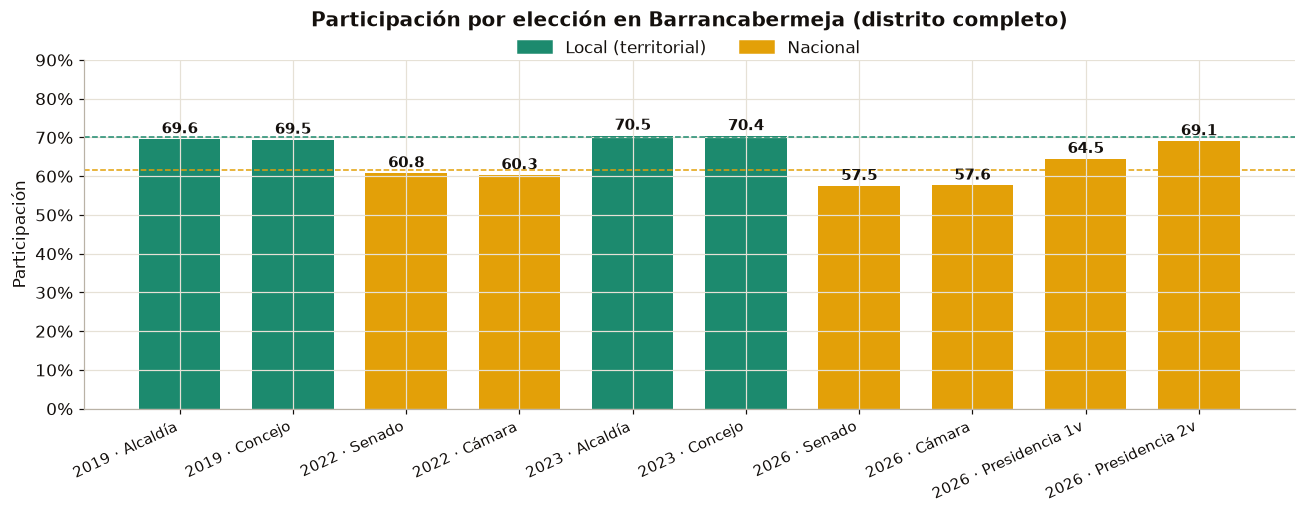

Promedio participación  LOCAL : 70.0%
Promedio participación NACIONAL: 61.6%


In [3]:
# Serie ciudad: participación por elección (distrito completo)
def pres_city(v):
    esc = pd.read_csv(R26 / f"presidencia_2026_{v}_escrutinio_barrancabermeja.csv", dtype=str)
    dep = pd.to_numeric(esc["votos"], errors="coerce").fillna(0).sum()
    dvf = next(p for p in [R26/f"presidencia_2026_{v}_divipol_barrancabermeja.csv",
                           R26/f"presidencia_2026_{v}_divipol_local_barrancabermeja.csv"] if p.exists())
    dv  = pd.read_csv(dvf, dtype=str)
    pot = (pd.to_numeric(dv.potencial_hombres,errors="coerce").fillna(0)
         + pd.to_numeric(dv.potencial_mujeres,errors="coerce").fillna(0)).sum()
    return dep/pot*100

def part_ciudad(anio, corp):
    return float(ae.query("anio==@anio & corporacion==@corp").participacion.iloc[0])
# Congreso 2026 (computado aparte y guardado como agregado liviano)
cong26 = pd.read_csv(PROC/"participacion"/"participacion_congreso_2026.csv")
def cong_city(corp):
    return float(cong26.query("nivel=='ciudad' & corporacion==@corp").participacion.iloc[0])

serie = [
    ("2019", "Local",    "Alcaldía",       part_ciudad(2019,"ALCALDE")),
    ("2019", "Local",    "Concejo",        part_ciudad(2019,"CONCEJO")),
    ("2022", "Nacional", "Senado",         part_ciudad(2022,"SENADO")),
    ("2022", "Nacional", "Cámara",         part_ciudad(2022,"CAMARA")),
    ("2023", "Local",    "Alcaldía",       part_ciudad(2023,"ALCALDE")),
    ("2023", "Local",    "Concejo",        part_ciudad(2023,"CONCEJO")),
    ("2026", "Nacional", "Senado",         cong_city("SENADO")),
    ("2026", "Nacional", "Cámara",         cong_city("CAMARA")),
    ("2026", "Nacional", "Presidencia 1v", pres_city("1v")),
    ("2026", "Nacional", "Presidencia 2v", pres_city("2v")),
]
S = pd.DataFrame(serie, columns=["año","ámbito","elección","participación"])
S["etiqueta"] = S["año"] + " · " + S["elección"]

fig, ax = plt.subplots(figsize=(12, 4.8))
colors = [TEAL if a=="Local" else OCHRE for a in S["ámbito"]]
bars = ax.bar(S["etiqueta"], S["participación"], color=colors, width=.72)
ax.axhline(S.query("ámbito=='Local'").participación.mean(), color=TEAL, ls="--", lw=1)
ax.axhline(S.query("ámbito=='Nacional'").participación.mean(), color=OCHRE, ls="--", lw=1)
for b,v in zip(bars, S["participación"]):
    ax.text(b.get_x()+b.get_width()/2, v+0.6, f"{v:.1f}", ha="center", va="bottom", fontsize=9.5, fontweight="bold")
ax.set_ylim(0, 90); ax.yaxis.set_major_formatter(PercentFormatter())
ax.set_ylabel("Participación"); ax.set_title("Participación por elección en Barrancabermeja (distrito completo)", pad=22)
ax.set_xticklabels(S["etiqueta"], rotation=25, ha="right", fontsize=9.5)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=TEAL,label="Local (territorial)"), Patch(color=OCHRE,label="Nacional")],
          loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.10), frameon=False)
plt.tight_layout(); plt.show()

prom_local = S[S["ámbito"]=="Local"]["participación"].mean()
prom_nac   = S[S["ámbito"]=="Nacional"]["participación"].mean()
print(f"Promedio participación  LOCAL : {prom_local:.1f}%")
print(f"Promedio participación NACIONAL: {prom_nac:.1f}%")


**Hallazgo 1: Barranca se moviliza más por lo local que por lo nacional, y la legislativa es la que menos arrastra (y cayendo).** `Nivel A/B`

Con el panorama completo el patrón es nítido. La participación territorial (Alcaldía/Concejo) ronda el **70 %** en 2019 y 2023. En lo nacional:
- **Legislativas (Congreso):** **~60 %** en 2022 y **~57,6 %** en 2026 — las de **menor** participación, y **a la baja**.
- **Presidencia 2026:** **64,5 %** en 1.ª vuelta y **69,1 %** en 2.ª — sube, hasta casi igualar lo local.

Orden de arrastre: **Local ≈ Presidencial 2v > Presidencial 1v > Legislativas**. La contienda local moviliza tanto como la gran final presidencial y claramente más que el Congreso.

*Lo que NO significa:* que sea así en todo el país (el patrón nacional suele ser el inverso). Es un rasgo **propio de Barranca**, consistente en varios ciclos.


## 3. Participación por comuna y estabilidad del patrón

¿El mapa de quién participa y quién se abstiene es estable entre elecciones, o cambia según el tipo de contienda?


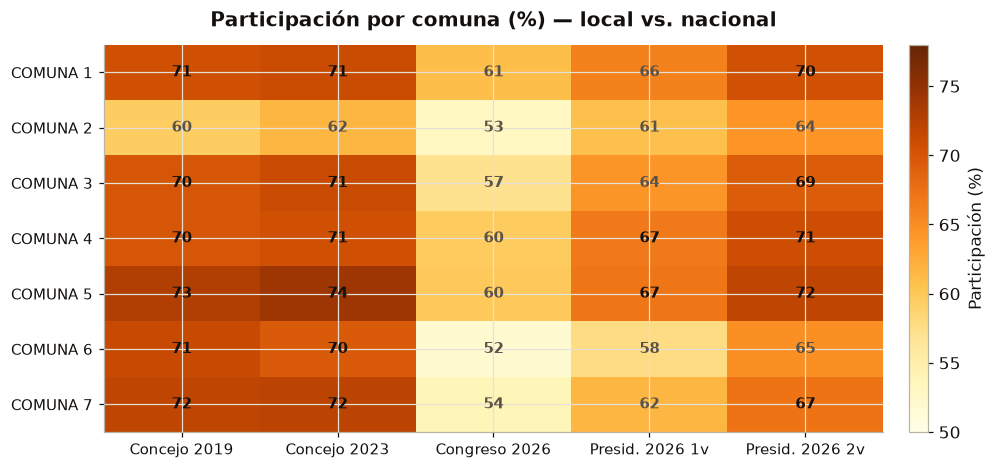

,Concejo 2019,Concejo 2023,Congreso 2026,Presid. 2026 1v,Presid. 2026 2v,Congreso 2022*
COMUNA 1,70.6,71.1,60.9,66.0,70.4,58.0
COMUNA 2,59.5,61.6,52.9,60.8,64.4,49.2
COMUNA 3,70.0,71.2,57.1,64.3,69.3,56.2
COMUNA 4,70.0,70.6,59.7,66.6,70.8,57.9
COMUNA 5,72.8,74.1,59.9,66.9,71.8,58.2
COMUNA 6,71.3,69.5,51.8,57.7,64.7,51.4
COMUNA 7,71.8,72.0,53.8,61.6,67.2,53.6


Spearman  Concejo2019 ↔ Concejo2023     : 0.72
Spearman  Concejo2023 ↔ Congreso2026    : 0.54
Spearman  Concejo2023 ↔ Presidencia2026 : 0.61


In [4]:
# Matriz de participación por comuna (elecciones con cobertura limpia por comuna)
at = pd.read_csv(ANAL / "agregado_territorio.csv")
at = at[at.ambito == "urbano"].copy()
def part(anio, corp):
    d = at[(at.anio==anio) & (at.corporacion==corp)].set_index("territorio")
    return (d.votos_depositados / d.potencial_electoral * 100).reindex(URB)

def pres_comuna(v):
    esc = pd.read_csv(R26 / f"presidencia_2026_{v}_escrutinio_barrancabermeja.csv", dtype=str)
    esc["votos"] = pd.to_numeric(esc["votos"], errors="coerce").fillna(0)
    dep = esc.groupby("comuna_divipol")["votos"].sum()
    dvf = next(p for p in [R26/f"presidencia_2026_{v}_divipol_barrancabermeja.csv",
                           R26/f"presidencia_2026_{v}_divipol_local_barrancabermeja.csv"] if p.exists())
    dv  = pd.read_csv(dvf, dtype=str)
    pot = (pd.to_numeric(dv.potencial_hombres,errors="coerce").fillna(0)
         + pd.to_numeric(dv.potencial_mujeres,errors="coerce").fillna(0))
    pot = pot.groupby(dv.comuna_divipol).sum()
    return (dep/pot*100).reindex(URB)

cong26 = pd.read_csv(PROC/"participacion"/"participacion_congreso_2026.csv")
c26 = cong26.query("nivel=='comuna' & corporacion=='SENADO'").set_index("territorio").participacion.reindex(URB)
M = pd.DataFrame({
    "Concejo 2019": part(2019,"CONCEJO"), "Concejo 2023": part(2023,"CONCEJO"),
    "Congreso 2026": c26,
    "Presid. 2026 1v": pres_comuna("1v"), "Presid. 2026 2v": pres_comuna("2v"),
}).round(1)
M["Congreso 2022*"] = part(2022,"SENADO").round(1)   # referencia, cobertura ~92%

# Heatmap (local + nacional más reciente, todas con cobertura limpia por comuna)
cols = ["Concejo 2019","Concejo 2023","Congreso 2026","Presid. 2026 1v","Presid. 2026 2v"]
fig, ax = plt.subplots(figsize=(9.2, 4.4))
data = M[cols].values
im = ax.imshow(data, cmap="YlOrBr", aspect="auto", vmin=50, vmax=78)
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, fontsize=10)
ax.set_yticks(range(len(URB))); ax.set_yticklabels(URB, fontsize=10)
for i in range(len(URB)):
    for j in range(len(cols)):
        ax.text(j, i, f"{data[i,j]:.0f}", ha="center", va="center",
                color=INK if data[i,j] > 66 else "#5B5347", fontsize=10, fontweight="bold")
ax.set_title("Participación por comuna (%) — local vs. nacional")
cb = fig.colorbar(im, ax=ax, fraction=.045, pad=.03); cb.set_label("Participación (%)")
plt.tight_layout(); plt.show()

display(M)

# Estabilidad del ranking
if HAVE_SCIPY:
    r1 = spearmanr(M["Concejo 2019"], M["Concejo 2023"]).correlation
    r2 = spearmanr(M["Concejo 2023"], M["Congreso 2026"]).correlation
    r3 = spearmanr(M["Concejo 2023"], M["Presid. 2026 1v"]).correlation
    print(f"Spearman  Concejo2019 ↔ Concejo2023     : {r1:.2f}")
    print(f"Spearman  Concejo2023 ↔ Congreso2026    : {r2:.2f}")
    print(f"Spearman  Concejo2023 ↔ Presidencia2026 : {r3:.2f}")


**Hallazgo 2: El mapa de la abstención es estructural, no coyuntural.** `Nivel B`

El orden de las comunas por participación se **repite elección tras elección y a través de niveles** (Spearman Concejo 2019-2023 ≈ **0,72**; Concejo 2023 - Congreso 2026 y - Presidencia 2026, positivos). La **Comuna 2 es la de menor participación en TODAS** las contiendas local, legislativa y presidencial (53 % en Congreso 2026), y la 5 suele liderar. Quien se abstiene en lo local tiende a abstenerse también en lo nacional.

*Lo que NO significa:* que sean las mismas personas cada vez (es patrón de territorio, no de individuos). El **nivel** sí cambia con el tipo de elección; el **orden** es el que se mantiene.


## 4. ¿Se vota Alcaldía sin votar Concejo? (voto diferenciado)

Alcaldía y Concejo se votan **el mismo día**, con tarjetas separadas. Podemos medir, de forma agregada, dos cosas: cuántas personas depositaron la tarjeta de Alcaldía pero no la de Concejo (*roll-off* de participación), y cuántas sí la depositaron pero la dejaron en blanco o nula (*roll-off* de voto válido).


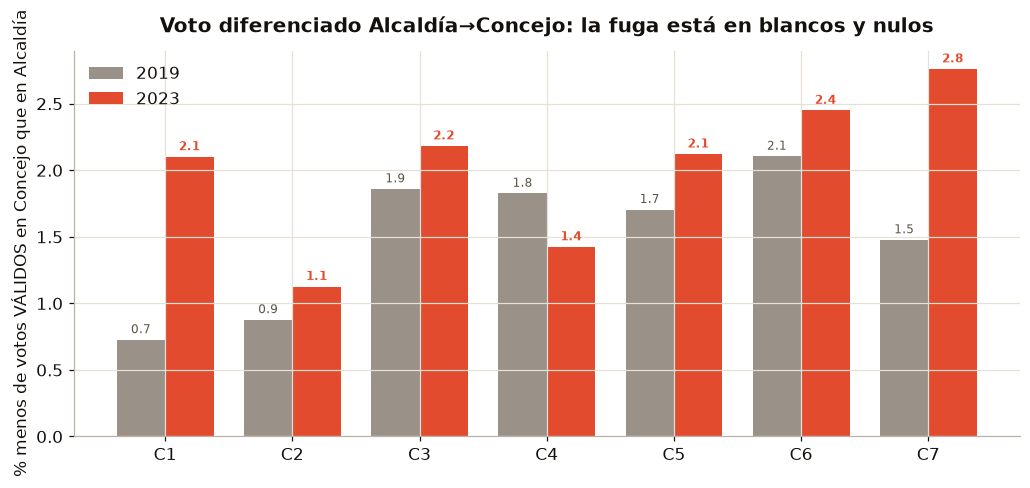

2019  roll-off DEPOSITADOS = 0.18%  |  roll-off VÁLIDOS = 1.46%  (1,546 tarjetas)
2023  roll-off DEPOSITADOS = 0.15%  |  roll-off VÁLIDOS = 2.00%  (2,265 tarjetas)


In [5]:
# Roll-off Alcaldía vs Concejo por comuna y año
def rolloff(y):
    a = at[(at.anio==y)&(at.corporacion=="ALCALDE")].set_index("territorio").reindex(URB)
    c = at[(at.anio==y)&(at.corporacion=="CONCEJO")].set_index("territorio").reindex(URB)
    return pd.DataFrame({
        "dep_dif_%": ((a.votos_depositados - c.votos_depositados)/a.votos_depositados*100),
        "val_dif_%": ((a.votos_validos    - c.votos_validos)   /a.votos_validos*100),
    })
ro19, ro23 = rolloff(2019), rolloff(2023)

fig, ax = plt.subplots(figsize=(9.5, 4.4))
x = np.arange(len(URB)); w = .38
ax.bar(x-w/2, ro19["val_dif_%"], w, color=MUTED, label="2019")
ax.bar(x+w/2, ro23["val_dif_%"], w, color=VERM,  label="2023")
ax.set_xticks(x); ax.set_xticklabels([c.replace('COMUNA ','C') for c in URB])
ax.set_ylabel("% menos de votos VÁLIDOS en Concejo que en Alcaldía")
ax.set_title("Voto diferenciado Alcaldía→Concejo: la fuga está en blancos y nulos")
ax.legend(frameon=False)
for xi, v in zip(x-w/2, ro19["val_dif_%"]): ax.text(xi, v+.05, f"{v:.1f}", ha="center", fontsize=8, color="#5B5347")
for xi, v in zip(x+w/2, ro23["val_dif_%"]): ax.text(xi, v+.05, f"{v:.1f}", ha="center", fontsize=8, color=VERM, fontweight="bold")
plt.tight_layout(); plt.show()

# Totales ciudad
for y, ro in [(2019, ro19), (2023, ro23)]:
    a = at[(at.anio==y)&(at.corporacion=="ALCALDE")]; c = at[(at.anio==y)&(at.corporacion=="CONCEJO")]
    dep = (a.votos_depositados.sum()-c.votos_depositados.sum())
    val = (a.votos_validos.sum()-c.votos_validos.sum())
    print(f"{y}  roll-off DEPOSITADOS = {dep/a.votos_depositados.sum()*100:.2f}%  |  "
          f"roll-off VÁLIDOS = {val/a.votos_validos.sum()*100:.2f}%  ({int(val):,} tarjetas)")


**Hallazgo 3: Casi nadie vota "solo Alcaldía": el que va, vota todo. La diferencia está en cómo marca el Concejo.** `Nivel A/B`

En depositar la tarjeta, el *roll-off* es **mínimo** (0,15- 0,18 %): quien va a las urnas deposita tanto la de Alcaldía como la de Concejo. Pero el Concejo recibe **~2 % menos votos válidos** que la Alcaldía (1,46 % en 2019 → **2,00 % en 2023**, unas **2.265 tarjetas** en 2023): más gente deja el Concejo en blanco o lo anula. La brecha **creció** entre 2019 y 2023.

*Lo que NO significa:* no podemos identificar personas (voto secreto); es una diferencia **agregada** entre dos corporaciones. Y "menos válidos" incluye blanco + nulo + no marcado, no solo desinterés.


## 5. Arquetipos de comuna

Cruzamos tres ejes por comuna: **nivel** de participación (2023), **tendencia** (cambio 2019-2023) y **tamaño/crecimiento** del censo. Eso agrupa a las comunas en perfiles con lecturas distintas de cara a una campaña.


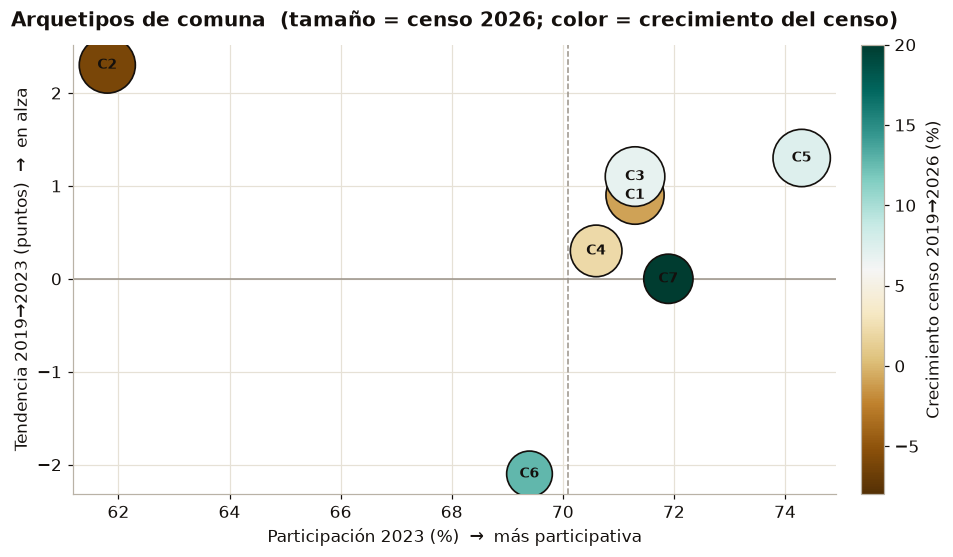

,part_2023,tendencia_19_23,censo_2026,crec_censo_19_26_%
territorio,,,,
COMUNA 1,71.3,0.9,27890,-1.0
COMUNA 2,61.8,2.3,25773,-6.1
COMUNA 3,71.3,1.1,29369,6.8
COMUNA 4,70.6,0.3,21430,2.1
COMUNA 5,74.3,1.3,27015,7.5
COMUNA 6,69.4,-2.1,16255,12.7
COMUNA 7,71.9,-0.0,19309,33.6


In [6]:
# Censo por comuna 2019 / 2023 / 2026
cen = pd.DataFrame({
    "censo_2019": at[(at.anio==2019)&(at.corporacion=="ALCALDE")].set_index("territorio").potencial_electoral,
    "censo_2023": at[(at.anio==2023)&(at.corporacion=="ALCALDE")].set_index("territorio").potencial_electoral,
}).reindex(URB)
dv1 = pd.read_csv(R26/"presidencia_2026_1v_divipol_barrancabermeja.csv", dtype=str)
cen["censo_2026"] = ((pd.to_numeric(dv1.potencial_hombres,errors="coerce").fillna(0)
                    + pd.to_numeric(dv1.potencial_mujeres,errors="coerce").fillna(0))
                     .groupby(dv1.comuna_divipol).sum().reindex(URB))
cen = cen.astype(float)

p23 = part(2023,"ALCALDE"); p19 = part(2019,"ALCALDE")
seg = pd.DataFrame({
    "part_2023": p23.round(1),
    "tendencia_19_23": (p23 - p19).round(1),
    "censo_2026": cen.censo_2026.astype(int),
    "crec_censo_19_26_%": ((cen.censo_2026/cen.censo_2019 - 1)*100).round(1),
})

fig, ax = plt.subplots(figsize=(8.8, 5.2))
sizes = (seg.censo_2026/seg.censo_2026.max()*1400)+120
sc = ax.scatter(seg.part_2023, seg.tendencia_19_23, s=sizes,
                c=seg["crec_censo_19_26_%"], cmap="BrBG", vmin=-8, vmax=20,
                edgecolor=INK, linewidth=1.1, zorder=3)
ax.axhline(0, color=MUTED, lw=1); ax.axvline(seg.part_2023.mean(), color=MUTED, lw=1, ls="--")
for c in URB:
    ax.annotate(c.replace("COMUNA ","C"), (seg.part_2023[c], seg.tendencia_19_23[c]),
                ha="center", va="center", fontsize=9, fontweight="bold", zorder=4)
ax.set_xlabel("Participación 2023 (%)  →  más participativa")
ax.set_ylabel("Tendencia 2019→2023 (puntos)  →  en alza")
ax.set_title("Arquetipos de comuna  (tamaño = censo 2026; color = crecimiento del censo)")
cb = fig.colorbar(sc, ax=ax, fraction=.045, pad=.03); cb.set_label("Crecimiento censo 2019→2026 (%)")
plt.tight_layout(); plt.show()
display(seg)


**Hallazgo 4: Cuatro perfiles distintos, cuatro estrategias distintas.** `Nivel B`

- **Comuna 2  grande, apática y encogiéndose:** la de menor participación y censo a la baja. Gran bolsa de voto dormido, pero difícil de activar.
- **Comunas 6 y 7 la periferia que crece:** censo disparado (C7 **+25 %** 2019→2023), participación alta; es donde se está moviendo el electorado.
- **Comuna 5  el bastión participativo:** la de mayor participación y en alza.
- **Comunas 1, 3, 4  el centro estable:** participación ~70 %, poco movimiento.

*Lo que NO significa:* los arquetipos son descriptivos, no categorías fijas; una comuna puede cambiar de perfil si cambian censo o movilización.


## 6. El censo se mueve: a dónde va el electorado y con qué edades

El censo electoral no es estático. Ver cómo se redistribuye entre comunas y qué edad tiene cada una es clave para 2027.


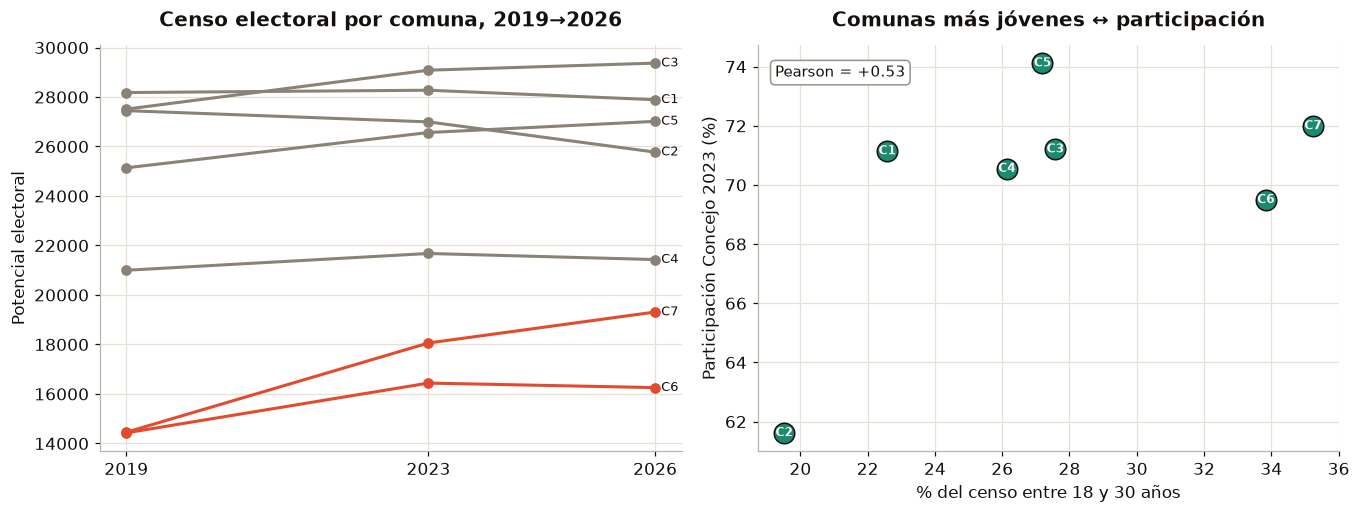

Crecimiento del censo 2019→2026 por comuna:
territorio
COMUNA 7    33.6
COMUNA 6    12.7
COMUNA 5     7.5
COMUNA 3     6.8
COMUNA 4     2.1
COMUNA 1    -1.0
COMUNA 2    -6.1

Censo urbano:  2019=158,148  2023=167,087  2026=167,041


In [7]:
# Evolución del censo por comuna + participación actual del censo
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))

ax = axes[0]
yrs = [2019, 2023, 2026]
for c in URB:
    vals = [cen.loc[c, f"censo_{y}"] for y in yrs]
    ax.plot(yrs, vals, marker="o", lw=2,
            color=VERM if c in ("COMUNA 7","COMUNA 6") else ("#C7392020" if False else "#8A8276"),
            label=c if c in ("COMUNA 7","COMUNA 6","COMUNA 2") else None, zorder=3 if c in ("COMUNA 7","COMUNA 6","COMUNA 2") else 2)
    ax.annotate(c.replace("COMUNA ","C"), (2026, cen.loc[c,"censo_2026"]), fontsize=8.5, va="center",
                xytext=(4,0), textcoords="offset points")
ax.set_title("Censo electoral por comuna, 2019→2026"); ax.set_ylabel("Potencial electoral")
ax.set_xticks(yrs)

ax = axes[1]
pe = pd.read_csv(PROC/"participacion"/"perfil_etario_concejo_2023.csv")
pp = pd.read_csv(ANAL/"panel_puestos.csv", dtype=str)
mapc = pp[pp.anio=="2023"][["cod_zona","cod_puesto","territorio"]].drop_duplicates()
pe["cod_zona"] = pe["cod_zona"].astype(str).str.zfill(2); pe["cod_puesto"] = pe["cod_puesto"].astype(str).str.zfill(2)
pe = pe.merge(mapc, on=["cod_zona","cod_puesto"], how="left")
age = (pe[pe.territorio.isin(URB)].groupby("territorio")
       .apply(lambda d: pd.Series({
           "part": np.average(d.participacion, weights=d.potencial_electoral),
           "jovenes_18_30": np.average(d.pct_censo_18_a_30, weights=d.potencial_electoral)}))
       .reindex(URB))
ax.scatter(age.jovenes_18_30, age.part, s=180, color=TEAL, edgecolor=INK, zorder=3)
for c in URB:
    ax.annotate(c.replace("COMUNA ","C"), (age.jovenes_18_30[c], age.part[c]),
                ha="center", va="center", fontsize=8, color="white", fontweight="bold", zorder=4)
ax.set_xlabel("% del censo entre 18 y 30 años"); ax.set_ylabel("Participación Concejo 2023 (%)")
ax.set_title("Comunas más jóvenes ↔ participación")
if HAVE_SCIPY:
    r = pearsonr(age.jovenes_18_30, age.part).statistic
    ax.text(.03, .95, f"Pearson = {r:+.2f}", transform=ax.transAxes, fontsize=10, va="top",
            bbox=dict(boxstyle="round", fc="white", ec=MUTED))
plt.tight_layout(); plt.show()

print("Crecimiento del censo 2019→2026 por comuna:")
print(((cen.censo_2026/cen.censo_2019-1)*100).round(1).sort_values(ascending=False).to_string())
print(f"\nCenso urbano:  2019={int(cen.censo_2019.sum()):,}  2023={int(cen.censo_2023.sum()):,}  2026={int(cen.censo_2026.sum()):,}")


**Hallazgo 5: El electorado se corre hacia la periferia joven.** `Nivel A/B`

El censo urbano total está casi **estancado** (~167 mil), pero por dentro se redistribuye: las **Comunas 6 y 7** (periferia) ganan electores y son las **más jóvenes** (33–35 % de su censo tiene 18–30 años), mientras la **Comuna 2 se encoge** y envejece. A nivel de comuna, las más jóvenes tienden a participar **más** (correlación positiva), al revés del tópico nacional.

*Lo que NO significa:* es una correlación **ecológica** entre territorios; no prueba que "los jóvenes votan más" a nivel individual. El dato etario es del **censo**, no de quienes efectivamente votaron.


### 7.2 Hay concejales elegidos por un solo puesto: los "fortines" 

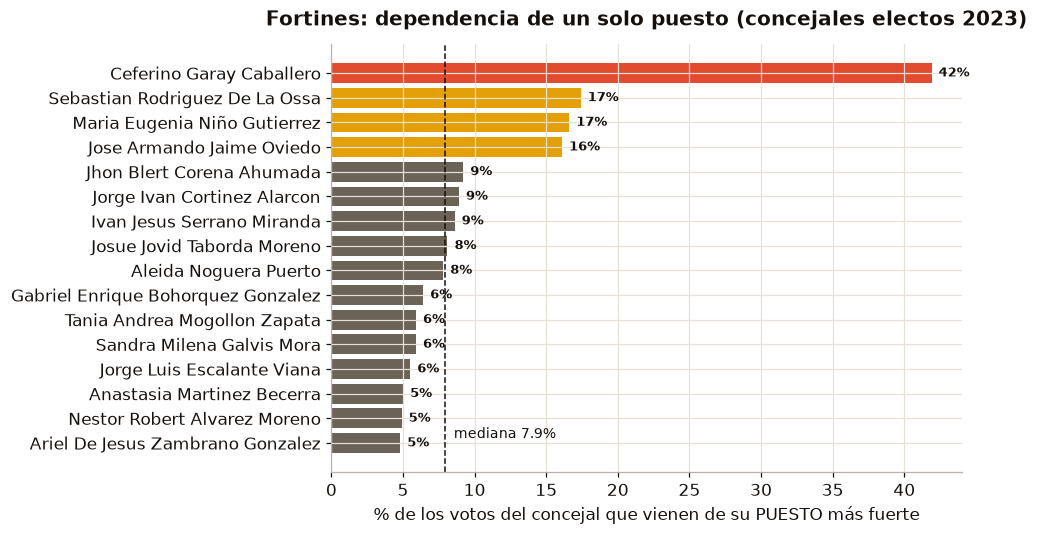

Outlier: Ceferino Garay Caballero — 42% de sus 1,684 votos en UN puesto
         (LA FORTUNA AUTOPISTA, CORREGIMIENTO LA FORTUNA AUTOPISTA); HHI=0.213 vs mediana 0.029


In [9]:
# Fortines: ¿cuánto del voto de cada concejal electo viene de un solo puesto?
fo = pd.read_csv(PROC/"analisis"/"fortines_concejo_2023.csv")
el = fo[fo.electo].sort_values("top_pto_pct", ascending=True)
fig, ax = plt.subplots(figsize=(9, 5))
colors = [VERM if v > 30 else (OCHRE if v > 15 else "#6B6358") for v in el.top_pto_pct]
ax.barh([c.title() for c in el.candidato], el.top_pto_pct, color=colors)
med = el.top_pto_pct.median()
ax.axvline(med, color=INK, ls="--", lw=1); ax.text(med + 0.6, 0.2, f"mediana {med:.1f}%", fontsize=9)
for y, v in enumerate(el.top_pto_pct):
    ax.text(v + 0.5, y, f"{v:.0f}%", va="center", fontsize=8.5, fontweight="bold")
ax.set_xlabel("% de los votos del concejal que vienen de su PUESTO más fuerte")
ax.set_title("Fortines: dependencia de un solo puesto (concejales electos 2023)")
plt.tight_layout(); plt.show()
t = el.sort_values("top_pto_pct", ascending=False).iloc[0]
print(f"Outlier: {t.candidato.title()} — {t.top_pto_pct:.0f}% de sus {int(t.votos):,} votos en UN puesto")
print(f"         ({t.lugar_top}, {t.comuna_top}); HHI={t.hhi} vs mediana {el.hhi.median():.3f}")


**Hallazgo 7: Un concejal fue elegido, esencialmente, por un solo puesto de votación.** `Nivel A/B`

**Ceferino Garay** sacó el **42 % de todos sus votos en un único puesto** (La Fortuna Autopista, zona rural), y dos de cada tres en apenas tres puestos. Su concentración (HHI 0,213) es **siete veces** la mediana de los electos (0,029): el caso extremo de **voto-fortín**, una base territorial capturada. En el otro extremo, concejales como Ariel Zambrano o Néstor Álvarez reparten su voto por toda la ciudad (≤5 % en su mejor puesto): votación transversal.

*Lo que NO significa:* alta concentración no prueba compra de votos ni irregularidad; mide **dependencia territorial**. Pero separa con nitidez dos formas de hacer política: tejer un bastión o sumar ciudad.


### 7.3 Dos abstenciones distintas: apatía vs. movilización solo local

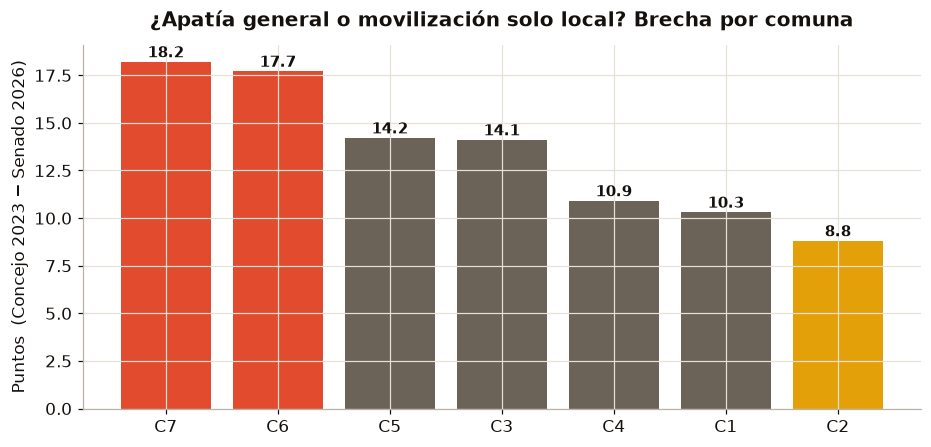

,Concejo_2023,Senado_2026,brecha
territorio,,,
COMUNA 7,72.0,53.8,18.2
COMUNA 6,69.5,51.8,17.7
COMUNA 5,74.1,59.9,14.2
COMUNA 3,71.2,57.1,14.1
COMUNA 4,70.6,59.7,10.9
COMUNA 1,71.1,60.9,10.3
COMUNA 2,61.6,52.9,8.8


In [10]:
# Brecha de movilización local - nacional por comuna
con23 = part(2023, "CONCEJO")
cong26 = pd.read_csv(PROC/"participacion"/"participacion_congreso_2026.csv")
sen26 = cong26.query("nivel=='comuna' & corporacion=='SENADO'").set_index("territorio").participacion.reindex(URB)
gap = (con23 - sen26).round(1).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8.6, 4.2))
colors = [VERM if g > 15 else ("#6B6358" if g > 10 else OCHRE) for g in gap]
ax.bar([c.replace("COMUNA ", "C") for c in gap.index], gap.values, color=colors)
for i, g in enumerate(gap.values): ax.text(i, g + 0.25, f"{g:.1f}", ha="center", fontweight="bold", fontsize=9.5)
ax.set_ylabel("Puntos  (Concejo 2023 − Senado 2026)")
ax.set_title("¿Apatía general o movilización solo local? Brecha por comuna")
plt.tight_layout(); plt.show()
display(pd.DataFrame({"Concejo_2023": con23.round(1), "Senado_2026": sen26.round(1),
                     "brecha": (con23 - sen26).round(1)}).reindex(gap.index))


**Hallazgo 8: La abstención de la Comuna 2 no es la misma que la de las Comunas 6 y 7.** `Nivel B`

El promedio esconde que hay **dos abstenciones distintas**:
- **Comunas 6 y 7** (periferia en crecimiento): votan ~70 % en lo local pero caen a ~52 % en lo nacional  **brecha de ~18 puntos**. Su electorado se **activa sobre todo para lo local**: firma de movilización local intensa.
- **Comuna 2**: su brecha es la **menor (~9 pts)**. No se activa para lo local; participa poco **en todo** por igual apatía pareja.

Y aquí se cierra el círculo con el censo: las comunas que **más crecen** (6 y 7) son las que **más se activan justo para las territoriales**. Ahí se está concentrando el voto que decide una elección local.

*Lo que NO significa:* "movilización local" describe el patrón; no identifica su causa (arraigo comunitario, liderazgos locales u otras redes).


## 8. Anatomía de una lista de 17: qué estructura produce curul y cuál no

Esta es la sección central del cuaderno. Se rehízo completa con un objetivo: **llegar por la vía matemática** a las respuestas que importan para armar una lista en 2027, con un **solo criterio** de clasificación de candidaturas y verificando **cada resultado en 2019 y en 2023 por separado**.

Las preguntas, en el orden en que se responden:

1. **Reglas del juego (8.1).** ¿Cuántas curules, cuántas candidaturas por lista, qué umbral y qué cifra repartidora? ¿Por cuántos votos se decidió la última curul?
2. **Criterio único (8.2).** ¿Cómo se clasifica a una candidatura (figura, medio, banca, relleno) de forma que sirva igual en los dos años y en 2027?
3. **Estructura (8.3–8.5).** ¿En qué posiciones de los 17 puestos se diferencia una lista con curul de una sin curul? ¿Qué parte de la diferencia de votos explica la cabeza, el bloque 2–5 y la cola? ¿Qué variables separan con significancia estadística y cuáles no?
4. **Ecuación y simulación (8.6–8.7).** ¿Cuántos votos aporta, en promedio, cada tipo de candidatura? ¿Qué combinaciones de 17 dan una, dos o tres curules, y con qué probabilidad?
5. **Márgenes (8.8–8.9).** ¿Cuánto le faltó a cada lista perdedora y cuánto le sobró a cada ganadora, en votos y en figuras equivalentes? ¿Qué explica los 978 votos entre Los Verídicos y Por un Cambio Bueno y Justo?
6. **Figuras sobrantes (8.10–8.11).** En En Marcha, de las seis figuras que no salieron, ¿cuántas eran necesarias para conservar las tres curules y cuántos votos no se convirtieron en curul? ¿Pasa lo mismo en otras listas?

### 8.0 Qué hay que explicar y qué no

**Lo que NO es un hallazgo.** Si una lista saca curul lo decide la ley (Art. 263 CP): solo compiten las listas que superan el **umbral**; se ordenan los cocientes `votos ÷ 1, 2, …, 17`, el 17.º fija la **cifra repartidora** y cada lista obtiene tantas curules como veces cabe la cifra en su total. Decir "las listas ganadoras tienen más votos" es aritmética, no análisis.

**Lo que SÍ hay que explicar** es la **función de producción**: qué combinación de 17 candidaturas genera ese total, cuántos votos sobran o faltan y cómo se reparten las curules dentro de la lista.

### Reglas de rigor de esta sección

1. **Cada resultado se calcula por ciclo.** Solo se usa como regla lo que se cumple en 2019 **y** en 2023.
2. **Validación fuera de muestra.** Los modelos se ajustan con un ciclo y se prueban con el otro.
3. **Se declara el `n`** y se reportan los resultados nulos.
4. **Un solo criterio de clasificación**, en unidades de cifra repartidora, con prueba de sensibilidad a los cortes (8.13).
5. Las 3 listas cerradas (sin voto preferente) cuentan para el reparto, pero no entran en el análisis por tipo de candidatura.

### 8.1 Las reglas del juego, verificadas con el dato

Antes de analizar composiciones hay que fijar los números que no se discuten:

- **17 curules.** Ley 136 de 1994, art. 22: los municipios de 100.001 a 250.000 habitantes eligen 17 concejales. Barrancabermeja eligió 17 en 2019 y 2023, y la proyección DANE para 2027 (≈232.000 habitantes) la mantiene en ese rango.
- **Hasta 17 candidaturas por lista.** Ley 1475 de 2011, art. 28: una lista no puede tener más candidaturas que curules a proveer. Se comprueba abajo con el máximo de candidaturas con voto por lista.
- **Umbral.** Art. 263 CP: en concejos, 50 % del cociente electoral (votos válidos ÷ curules). Una lista bajo el umbral no participa en el reparto.
- **Cifra repartidora.** El 17.º cociente más alto entre las listas que superan el umbral.

In [11]:
# --- 8.1 Reglas del juego: curules, tope de candidaturas, umbral y cifra repartidora ---
ce = pd.read_csv(ANAL/"candidato_eleccion.csv", encoding="utf-8-sig",
                 dtype={"cod_partido": str, "cod_candidato": str})
pe = pd.read_csv(ANAL/"partido_eleccion.csv", encoding="utf-8-sig", dtype={"cod_partido": str})
ag = pd.read_csv(ANAL/"agregado_eleccion.csv", encoding="utf-8-sig")
ce = ce[ce.corporacion=="CONCEJO"].copy()
pe = pe[pe.corporacion=="CONCEJO"].copy()

CURULES = 17
VALIDOS = {int(r.anio): float(r.votos_validos) for r in ag[ag.corporacion=="CONCEJO"].itertuples()}
UMBRAL  = {y: 0.5*VALIDOS[y]/CURULES for y in VALIDOS}      # Art. 263 CP: 50 % del cociente

def reparto(tot, umbral, n=CURULES):
    "Cifra repartidora (D'Hondt). tot = {lista: votos}. Devuelve (curules, cifra, cocientes ordenados)."
    elig = {k: v for k, v in tot.items() if v >= umbral}
    qs = sorted(((v/i, k) for k, v in elig.items() for i in range(1, n+1)), key=lambda t: -t[0])
    s = {k: 0 for k in tot}
    for q, k in qs[:n]:
        s[k] += 1
    return s, qs[n-1][0], qs

def totales(y):
    return pe[pe.anio==y].set_index("nombre_partido").votos.astype(float).to_dict()

def seats_cifra(y):
    "Atajo usado por celdas posteriores: (curules por lista, cifra repartidora)."
    s, c, _ = reparto(totales(y), UMBRAL[y]); return s, c

CIF, SEATS, Q18, QS = {}, {}, {}, {}
filas = []
for y in (2019, 2023):
    s, c, qs = reparto(totales(y), UMBRAL[y])
    CIF[y], SEATS[y], Q18[y], QS[y] = c, s, qs[CURULES][0], qs
    sin_umbral = reparto(totales(y), 0)[0]
    py = pe[pe.anio==y]
    filas.append({
        "votos válidos (incluye blanco)": int(VALIDOS[y]),
        "umbral (50 % del cociente)": round(UMBRAL[y]),
        "cifra repartidora (17.º cociente)": round(c),
        "siguiente cociente (18.º)": round(qs[CURULES][0]),
        "curules asignadas": sum(s.values()),
        "listas inscritas con votos": len(py),
        "listas abiertas": int((~py.sin_voto_preferente_observado).sum()),
        "listas bajo el umbral": int((py.votos < UMBRAL[y]).sum()),
        "listas con curul": sum(v > 0 for v in s.values()),
        "máx. candidaturas con voto en una lista": int(ce[ce.anio==y].groupby("nombre_partido").size().max()),
        "el umbral cambia el reparto": s != sin_umbral,
    })
REGLAS = pd.DataFrame(filas, index=[2019, 2023]).T
display(REGLAS)
assert all(sum(SEATS[y].values()) == 17 for y in SEATS)

for y in (2019, 2023):
    print(f"\n{y} · cocientes alrededor del corte (cifra = {CIF[y]:,.0f})")
    for i, (q, k) in enumerate(QS[y][12:20], start=13):
        marca = "  <- última curul" if i == 17 else ("  <- primera sin curul" if i == 18 else "")
        print(f"  {i:>2}. {q:>8,.0f}  {k[:48]}{marca}")

,2019,2023
votos válidos (incluye blanco),115917,125061
umbral (50 % del cociente),3409,3678
cifra repartidora (17.º cociente),4412,4042
siguiente cociente (18.º),4341,3853
curules asignadas,17,17
listas inscritas con votos,18,25
listas abiertas,17,23
listas bajo el umbral,5,13
listas con curul,11,11
máx. candidaturas con voto en una lista,17,17



2019 · cocientes alrededor del corte (cifra = 4,412)
  13.    4,832  SUMEMOS
  14.    4,622  PARTIDO ALIANZA SOCIAL INDEPENDIENTE ASI
  15.    4,464  BIENESTAR Y UNIDAD SOCIAL - BUS
  16.    4,454  MOVIMIENTO SOCIAL TAREA DE TODOS
  17.    4,412  PARTIDO CAMBIO RADICAL  <- última curul
  18.    4,341  PARTIDO CENTRO DEMOCRATICO  <- primera sin curul
  19.    4,320  CIVICOS AL 100%
  20.    4,191  PARTIDO LIBERAL COLOMBIANO

2023 · cocientes alrededor del corte (cifra = 4,042)
  13.    5,012  PARTIDO LIBERAL COLOMBIANO
  14.    4,648  INDEPENDIENTES
  15.    4,111  PACTO HISTORICO
  16.    4,073  POR UN CAMBIO BUENO Y JUSTO
  17.    4,042  PARTIDO NUEVO LIBERALISMO  <- última curul
  18.    3,853  PARTIDO CONSERVADOR - PARTIDO MIRA  <- primera sin curul
  19.    3,838  AGRUPACIÓN POLÍTICA EN MARCHA
  20.    3,614  CIVICOS


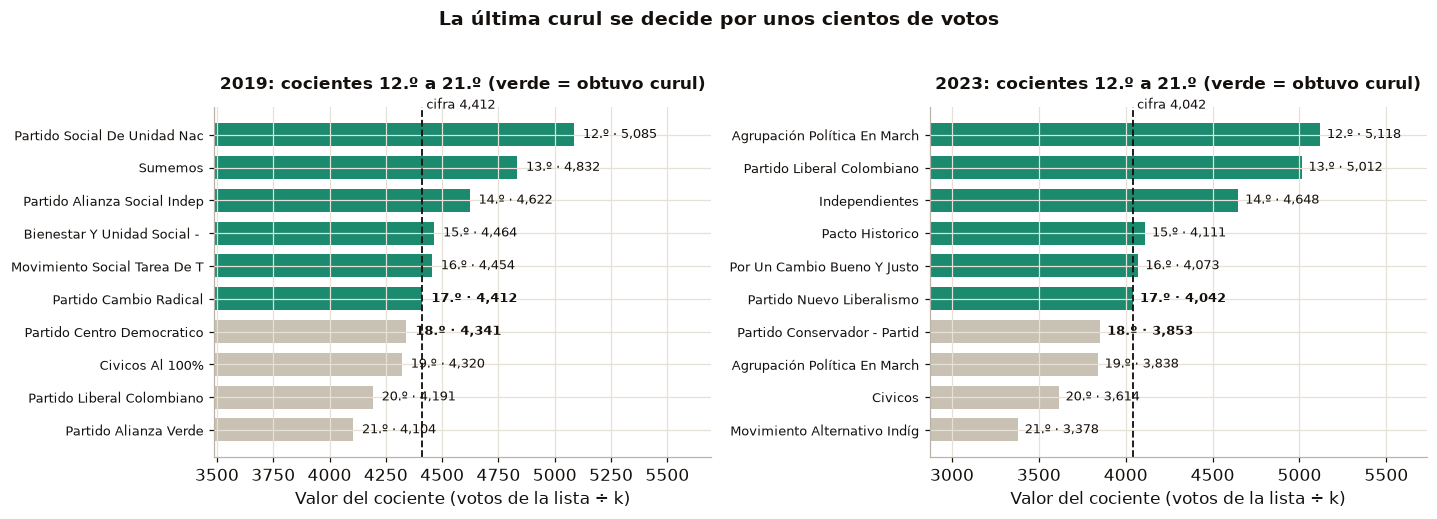

In [12]:
# Gráfico: la carrera por las últimas curules
fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.6))
for ax, y in zip(axes, (2019, 2023)):
    seg = QS[y][11:21]
    etiquetas = [f"{k.title()[:28]}" for q, k in seg]
    vals = [q for q, k in seg]
    pos = np.arange(len(seg))[::-1]
    cols = [TEAL if i < 6 else "#C9C1B3" for i in range(len(seg))]
    ax.barh(pos, vals, color=cols, height=.7)
    ax.axvline(CIF[y], color=INK, lw=1.2, ls="--")
    ax.text(CIF[y], len(seg)-.3, f" cifra {CIF[y]:,.0f}", fontsize=8.5, va="bottom")
    for p, v, i in zip(pos, vals, range(len(seg))):
        ax.text(v+40, p, f"{12+i}.º · {v:,.0f}", va="center", fontsize=8.2,
                fontweight="bold" if i in (5, 6) else "normal")
    ax.set_yticks(pos); ax.set_yticklabels(etiquetas, fontsize=8.2)
    ax.set_xlim(min(vals)*.85, max(vals)*1.12)
    ax.set_title(f"{y}: cocientes 12.º a 21.º (verde = obtuvo curul)", fontsize=11)
    ax.set_xlabel("Valor del cociente (votos de la lista ÷ k)")
fig.suptitle("La última curul se decide por unos cientos de votos", fontsize=12.5, fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

**Hallazgo 9: Las reglas son las esperadas y la última curul se decide por márgenes de cientos de votos.** `Nivel A`

- Ambos ciclos repartieron **17 curules** y ninguna lista tuvo más de **17 candidaturas con voto**.
- El umbral fue de **3.409 votos en 2019 y 3.678 en 2023**. Quedaron por debajo **5 de 18 listas en 2019 y 13 de 25 en 2023**: en 2023, más de la mitad de las listas ni siquiera entró al reparto. Aun así el umbral **no cambió quién ganó**: todas las listas con opción de curul lo superaban.
- La cifra repartidora fue **4.412** (2019) y **4.042** (2023). El cociente siguiente, el primero que quedó sin curul, fue **4.341** (Centro Democrático, 2019) y **3.853** (Partido Conservador – MIRA, 2023).
- En 2019 Centro Democrático quedó a **72 votos** de una curul. En 2023 la curul 17 se decidió entre Por un Cambio Bueno y Justo (4.073) y Conservador – MIRA (3.853), 220 votos.

Esa distancia entre el 17.º y el 18.º cociente define dos umbrales distintos que se usan en el resto de la sección: **para entrar** una lista nueva debe superar la cifra repartidora; **para conservar** una curul que ya tiene, a una lista le basta con no caer por debajo del siguiente cociente en la fila (3.853 en 2023). Esa diferencia explica el caso de En Marcha en 8.10.

*Lo que NO significa:* la norma de 17 curules depende de la población certificada para 2027; con ≈232.000 habitantes Barrancabermeja sigue en el rango de 17, pero la cifra definitiva la fija la Registraduría.

### 8.2 Un solo criterio para clasificar candidaturas

El análisis anterior mezclaba cortes: "figura" ≥930 votos y "banca" de 100 a 929. Con ese criterio una candidatura de 900 votos y otra de 120 contaban igual como banca, y por eso los 978 votos entre dos listas parecían "un integrante de banca más" cuando equivalen casi a una figura (8.9).

Desde aquí se usa **un único criterio**, en **unidades de cifra repartidora** del año (`u = votos ÷ cifra`). Así 1,0 significa "una curul de votos" en cualquier elección, incluida 2027.

| Tipo | Corte en cifras | Equivalente 2019 | Equivalente 2023 | Lógica |
|---|---|---|---|---|
| **F · Figura** | u ≥ 0,225 | ≥ 993 | ≥ 910 | Nivel del concejal electo menos votado (0,230 en ambos años) |
| **M · Medio** | 0,124 ≤ u < 0,225 | 547–992 | 501–909 | Aporta entre un octavo y un cuarto de curul |
| **B · Banca** | 0,025 ≤ u < 0,124 | 110–546 | 101–500 | Campaña real, aporte pequeño |
| **R · Relleno** | u < 0,025 | < 110 | < 101 | Completa la lista; casi no suma |

En 2023 no hay candidaturas entre 901 y 931 votos, así que "figura ≥910" y "figura ≥930" clasifican igual. La sensibilidad a estos cortes se prueba en 8.13.

In [13]:
# --- 8.2 Criterio único: tipos de candidatura en unidades de cifra repartidora ---
CUT   = {"F": 0.225, "M": 0.124, "B": 0.025}
TIPOS = {"F": "Figura", "M": "Medio", "B": "Banca", "R": "Relleno"}
COLT  = {"F": TEAL, "M": "#58A98F", "B": OCHRE, "R": "#BDB5A6"}

def clasificar(u, cut=CUT):
    return np.select([u >= cut["F"], u >= cut["M"], u >= cut["B"]], ["F", "M", "B"], "R")

ce["cifra"] = ce.anio.map(CIF)
ce["u"]     = ce.votos / ce.cifra
ce["tipo"]  = clasificar(ce.u)
ce["rango_lista"] = ce.groupby(["anio", "nombre_partido"]).votos.rank(method="first", ascending=False).astype(int)
ce["curules_lista"] = [SEATS[a][p] for a, p in zip(ce.anio, ce.nombre_partido)]
ce["electo"] = ce.rango_lista <= ce.curules_lista

PISO = ce[ce.electo].groupby("anio").agg(piso=("votos", "min"), piso_u=("u", "min"),
                                         mediana_electo=("votos", "median"))
PISO["mejor_no_electo"] = ce[~ce.electo].groupby("anio").votos.max()
display(PISO.round(3))

t = (ce.groupby(["anio", "tipo"]).agg(n=("votos", "size"), minimo=("votos", "min"), maximo=("votos", "max"),
                                       media=("votos", "mean"), mediana=("votos", "median"),
                                       media_u=("u", "mean"), electos=("electo", "sum"))
       .round({"media": 0, "media_u": 3}))
t["% electos"] = (100*t.electos/t.n).round(1)
display(t.reindex(["F", "M", "B", "R"], level=1))

# Tabla de listas: perfil de 17 posiciones y composición
P17 = [f"p{i}" for i in range(1, 18)]
filas = []
for _, r in pe.iterrows():
    v = np.sort(ce[(ce.anio==r.anio) & (ce.nombre_partido==r.nombre_partido)].votos.values)[::-1]
    prof = np.zeros(17); prof[:len(v)] = v
    filas.append(dict(anio=r.anio, lista=r.nombre_partido, total=float(r.votos), logo=float(r.votos_de_lista),
                      cerrada=bool(r.sin_voto_preferente_observado), n_cand=len(v),
                      cur=SEATS[r.anio][r.nombre_partido], **dict(zip(P17, prof))))
LST = pd.DataFrame(filas)
LST["cifra"] = LST.anio.map(CIF)
U17 = LST[P17].values / LST.cifra.values[:, None]
for k in "FMBR":
    lo = CUT.get(k, 0); hi = {"F": 9, "M": CUT["F"], "B": CUT["M"], "R": CUT["B"]}[k]
    LST[k] = ((U17 >= lo) & (U17 < hi) & (U17 > 0)).sum(1)
LST["vacios"] = 17 - LST.n_cand
LST["u_tot"]   = LST.total / LST.cifra
LST["u_p1"]    = U17[:, 0]
LST["u_p2_5"]  = U17[:, 1:5].sum(1)
LST["u_p6_17"] = U17[:, 5:].sum(1)
LST["u_logo"]  = LST.logo / LST.cifra
LST["gano"]    = LST.cur > 0
AB = LST[~LST.cerrada].copy()          # 40 listas abiertas
print(f"Listas: {len(LST)} · abiertas: {len(AB)} (2019: {(AB.anio==2019).sum()}, 2023: {(AB.anio==2023).sum()})")

,piso,piso_u,mediana_electo,mejor_no_electo
anio,,,,
2019,1013,0.230,1701.0,1705
2023,932,0.231,1519.0,1472


n  minimo  maximo   media  mediana  media_u  electos  % electos
anio tipo                                                                   
2019 F      35    1013    2684  1509.0   1447.0    0.342       17       48.6
     M      30     550     958   742.0    720.0    0.168        0        0.0
     B     113     112     533   238.0    211.0    0.054        0        0.0
     R      97       7     110    52.0     50.0    0.012        0        0.0
2023 F      37     932    2228  1302.0   1248.0    0.322       16       43.2
     M      44     510     900   679.0    653.5    0.168        0        0.0
     B     107     102     500   218.0    183.0    0.054        0        0.0
     R     171       9     100    48.0     45.0    0.012        0        0.0

Listas: 43 · abiertas: 40 (2019: 17, 2023: 23)


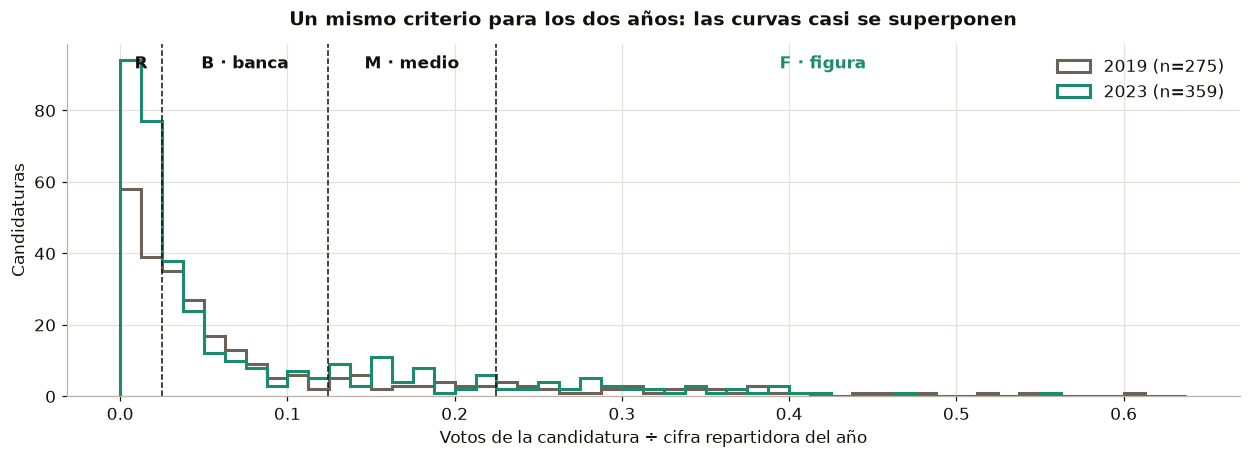

In [14]:
# Gráfico: distribución de candidaturas en unidades de cifra, con los cortes del criterio
fig, ax = plt.subplots(figsize=(11.5, 4.3))
bins = np.r_[0, np.arange(0.0125, 0.65, 0.0125)]
for y, col, ls in [(2019, "#6B6358", "-"), (2023, TEAL, "-")]:
    ax.hist(ce[ce.anio==y].u, bins=bins, histtype="step", lw=2, color=col, label=f"{y} (n={int((ce.anio==y).sum())})")
for k, x in CUT.items():
    ax.axvline(x, color=INK, lw=1, ls="--")
ax.text(CUT["B"]/2, ax.get_ylim()[1]*.93, "R", ha="center", fontweight="bold")
ax.text((CUT["B"]+CUT["M"])/2, ax.get_ylim()[1]*.93, "B · banca", ha="center", fontweight="bold")
ax.text((CUT["M"]+CUT["F"])/2, ax.get_ylim()[1]*.93, "M · medio", ha="center", fontweight="bold")
ax.text(.42, ax.get_ylim()[1]*.93, "F · figura", ha="center", fontweight="bold", color=TEAL)
ax.set_xlabel("Votos de la candidatura ÷ cifra repartidora del año")
ax.set_ylabel("Candidaturas")
ax.set_title("Un mismo criterio para los dos años: las curvas casi se superponen", fontsize=12.5)
ax.legend(frameon=False); plt.tight_layout(); plt.show()

**Hallazgo 10: Medido en cifras repartidoras, el piso del concejal es el mismo en los dos ciclos y el criterio sirve para 2027.** `Nivel A/B`

El concejal electo menos votado sacó **1.013 votos en 2019** y **932 en 2023**: **0,230 cifras** en ambos años. La cifra bajó 8 % y el piso bajó con ella. Por eso el criterio se expresa en cifras y no en votos: en 2027 una figura será quien llegue a ~0,225 de la cifra que resulte.

Con ese criterio, los cuatro tipos tienen el mismo aporte medio en los dos años: **figura ≈ 0,33 cifras, medio ≈ 0,17, banca ≈ 0,054, relleno ≈ 0,012**. Es la base de la ecuación de 8.6.

*Lo que NO significa:* son dos elecciones. Que el piso coincida en 0,230 es una regularidad, no una ley; por eso los cortes se someten a prueba de sensibilidad en 8.13.

### 8.3 La estructura de 17 puestos: dónde se diferencia una lista con curul

Cada lista se ordena de su candidatura más votada (posición 1) a la menos votada (posición 17); los puestos vacíos cuentan como cero. Luego se promedia, posición por posición, el voto expresado en cifras. Así se ve **la forma** de una lista ganadora frente a una perdedora, sin depender de etiquetas.

Para medir en qué posición la diferencia es más nítida se usa el **delta de Cliff** (δ): la probabilidad de que una lista con curul supere en esa posición a una sin curul, menos la probabilidad contraria. δ = 1 significa que **todas** las listas con curul superan a **todas** las que no la tuvieron; δ = 0, que no hay diferencia.

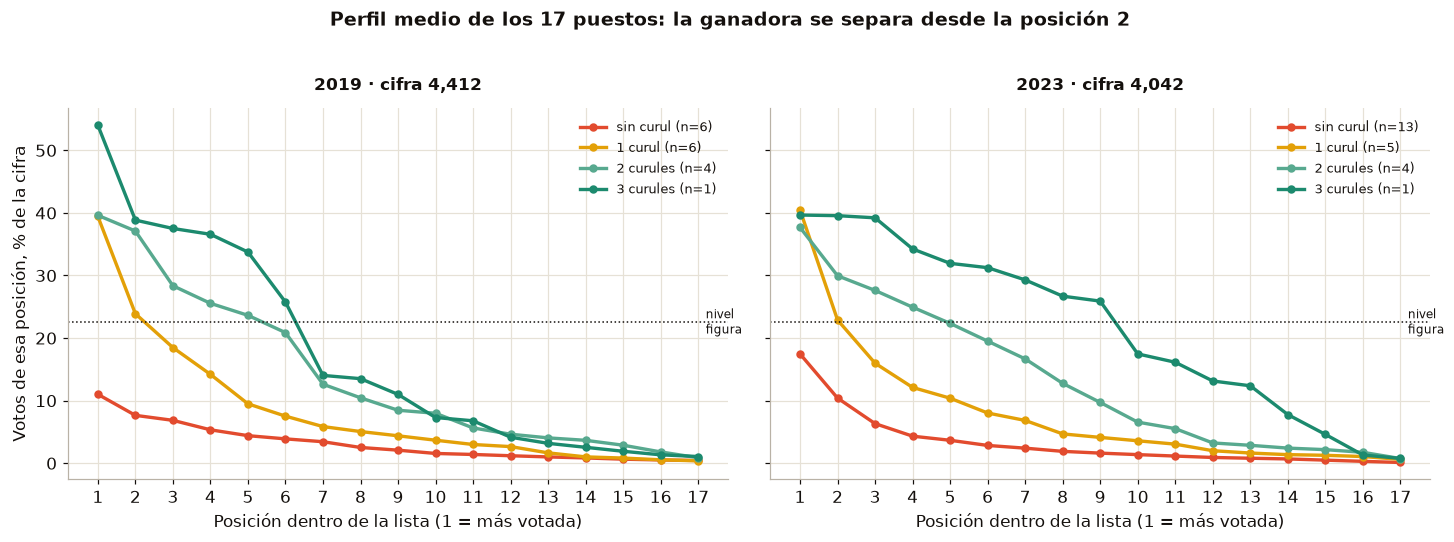

,pos 1,pos 2,pos 3,pos 4,pos 5,pos 6,pos 7,pos 8,pos 9,pos 10,pos 11,pos 12,pos 13,pos 14,pos 15,pos 16,pos 17
2019 · sin curul,11.0,7.6,6.8,5.3,4.4,3.9,3.4,2.5,2.1,1.6,1.4,1.2,1.0,0.8,0.6,0.5,0.4
2019 · 1 curul,39.4,23.9,18.5,14.2,9.5,7.5,5.9,5.1,4.4,3.7,3.0,2.7,1.7,1.0,0.8,0.5,0.4
2019 · 2 curules,39.6,37.1,28.4,25.5,23.6,20.9,12.6,10.4,8.5,8.0,5.6,4.6,4.0,3.7,2.9,1.8,0.9
2019 · 3 curules,54.0,38.8,37.5,36.6,33.7,25.7,14.0,13.5,11.0,7.3,6.8,4.1,3.2,2.5,1.9,1.3,1.1
2023 · sin curul,17.5,10.4,6.3,4.3,3.7,2.8,2.4,1.9,1.6,1.4,1.1,0.9,0.8,0.7,0.5,0.3,0.1
2023 · 1 curul,40.5,22.9,16.0,12.1,10.4,8.0,6.8,4.7,4.1,3.6,3.0,2.0,1.6,1.4,1.3,1.1,0.6
2023 · 2 curules,37.7,30.0,27.6,24.9,22.3,19.5,16.7,12.8,9.7,6.6,5.5,3.2,2.9,2.4,2.2,1.7,0.7
2023 · 3 curules,39.7,39.6,39.2,34.2,31.9,31.2,29.3,26.7,25.9,17.5,16.1,13.1,12.4,7.8,4.6,1.3,0.8


In [15]:
# --- 8.3 Perfil de 17 posiciones por número de curules, cada ciclo por separado ---
GRUPOS = [(0, "sin curul", VERM), (1, "1 curul", OCHRE), (2, "2 curules", "#58A98F"), (3, "3 curules", TEAL)]
PERFIL = {}
fig, axes = plt.subplots(1, 2, figsize=(13.4, 4.8), sharey=True)
for ax, y in zip(axes, (2019, 2023)):
    d = AB[AB.anio==y]
    for c, lbl, col in GRUPOS:
        g = d[d.cur.clip(upper=3)==c]
        if not len(g): continue
        m = 100*g[P17].mean().values/CIF[y]
        PERFIL[(y, c)] = m
        ax.plot(range(1, 18), m, marker="o", ms=4.5, lw=2.2, color=col, label=f"{lbl} (n={len(g)})")
    ax.axhline(100*CUT["F"], color=INK, ls=":", lw=1)
    ax.text(17.2, 100*CUT["F"], "nivel\nfigura", fontsize=7.8, va="center")
    ax.set_xticks(range(1, 18)); ax.set_xlabel("Posición dentro de la lista (1 = más votada)")
    ax.set_title(f"{y} · cifra {CIF[y]:,.0f}", fontsize=11)
    ax.legend(frameon=False, fontsize=8.6)
axes[0].set_ylabel("Votos de esa posición, % de la cifra")
fig.suptitle("Perfil medio de los 17 puestos: la ganadora se separa desde la posición 2",
             fontsize=12.5, fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

tab = pd.DataFrame({f"{y} · {lbl}": np.round(PERFIL[(y, c)], 1) for y in (2019, 2023)
                    for c, lbl, _ in GRUPOS if (y, c) in PERFIL}, index=[f"pos {i}" for i in range(1, 18)]).T
display(tab)

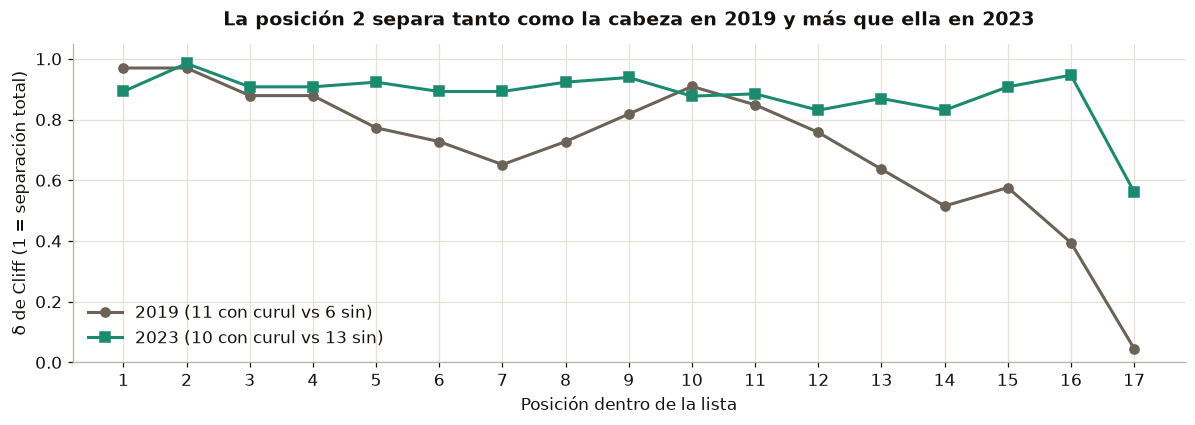

        1     2     3     4     5     6     7     8     9     10    11    12    13    14    15    16    17
2019  0.97  0.97  0.88  0.88  0.77  0.73  0.65  0.73  0.82  0.91  0.85  0.76  0.64  0.52  0.58  0.39  0.05
2023  0.89  0.98  0.91  0.91  0.92  0.89  0.89  0.92  0.94  0.88  0.88  0.83  0.87  0.83  0.91  0.95  0.56

Posición con mayor δ: {2019: 1, 2023: 2}


In [16]:
# Delta de Cliff por posición: ¿qué puesto separa mejor a ganadoras de perdedoras?
def cliff(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    return ((a[:, None] > b[None, :]).sum() - (a[:, None] < b[None, :]).sum()) / (len(a)*len(b))

DPOS = pd.DataFrame({y: [cliff(AB[(AB.anio==y) & AB.gano][p], AB[(AB.anio==y) & ~AB.gano][p]) for p in P17]
                     for y in (2019, 2023)}, index=range(1, 18))
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(DPOS.index, DPOS[2019], marker="o", color="#6B6358", lw=2, label="2019 (11 con curul vs 6 sin)")
ax.plot(DPOS.index, DPOS[2023], marker="s", color=TEAL, lw=2, label="2023 (10 con curul vs 13 sin)")
ax.set_ylim(0, 1.05); ax.set_xticks(range(1, 18))
ax.set_xlabel("Posición dentro de la lista"); ax.set_ylabel("δ de Cliff (1 = separación total)")
ax.set_title("La posición 2 separa tanto como la cabeza en 2019 y más que ella en 2023", fontsize=12.3)
ax.legend(frameon=False, loc="lower left"); plt.tight_layout(); plt.show()
print(DPOS.round(2).T.to_string())
print("\nPosición con mayor δ:", {y: int(DPOS[y].idxmax()) for y in (2019, 2023)})

**Hallazgo 11: El número 2 de la lista separa a ganadoras de perdedoras tanto o más que la cabeza.** `Nivel B`

El perfil medio muestra que la candidatura más votada de una lista sin curul no está tan lejos de la de una ganadora: en 2023, la primera posición de las perdedoras promedia 17,5 % de la cifra y la de las listas de una curul, 40,5 %. La **posición 2** separa tanto como la cabeza en 2019 (δ = 0,97 en ambas) y más que ella en 2023 (δ = **0,98** frente a 0,89). En la práctica, casi toda lista con curul tuvo un número 2 más fuerte que el número 2 de cualquier lista sin curul.

Las posiciones 3 a 15 también separan (δ entre 0,6 y 0,95). Solo el puesto 17 deja de hacerlo: el último lugar de la lista casi no aporta en ningún caso.

*Lo que NO significa:* no dice que el número 2 cause la curul. Una lista que logra reclutar un segundo nombre fuerte suele lograr también el resto del equipo. Dice dónde mirar primero al evaluar una lista.

### 8.4 ¿De dónde sale la diferencia de votos entre listas? Descomposición exacta

El total de una lista es una suma: `T = cabeza (pos. 1) + bloque 2–5 + cola 6–17 + voto solo por el logo`. Por propiedad de la covarianza,

$$\mathrm{Var}(T) = \mathrm{Cov}(C_1,T) + \mathrm{Cov}(C_{2\text{–}5},T) + \mathrm{Cov}(C_{6\text{–}17},T) + \mathrm{Cov}(\text{logo},T)$$

así que la parte de la variación del total que aporta cada bloque es `Cov(Cₖ, T) / Var(T)` y las cuatro partes suman exactamente 100 %. Los intervalos salen de 5.000 remuestreos *bootstrap* de las listas de cada año.

2019                        2023                    
                   parte % IC90 bajo IC90 alto parte % IC90 bajo IC90 alto
cabeza (pos. 1)       16.0      11.7      20.7    11.5       7.8      18.5
bloque 2–5            49.1      44.0      53.6    42.2      39.2      47.0
cola 6–17             32.5      25.8      40.0    43.7      33.3      50.2
voto solo de lista     2.5       2.0       3.0     2.6       1.9       4.0

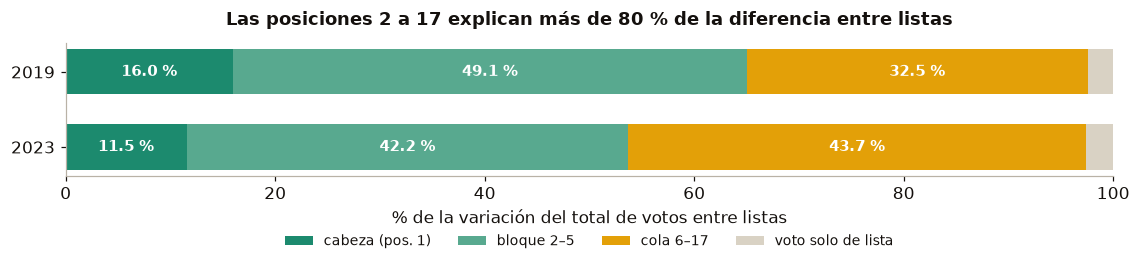

In [17]:
# --- 8.4 Descomposición de la varianza del total por bloques de posiciones ---
rng = np.random.default_rng(2027)
BLOQ = {"cabeza (pos. 1)": "u_p1", "bloque 2–5": "u_p2_5", "cola 6–17": "u_p6_17", "voto solo de lista": "u_logo"}
def partes(d):
    T = d.u_tot.values; vT = T.var(ddof=1)
    return np.array([np.cov(d[c].values, T)[0, 1]/vT for c in BLOQ.values()])
res = {}
for y in (2019, 2023):
    d = AB[AB.anio==y].reset_index(drop=True)
    boot = np.array([partes(d.iloc[rng.integers(0, len(d), len(d))]) for _ in range(5000)])
    res[y] = pd.DataFrame({"parte %": 100*partes(d), "IC90 bajo": 100*np.nanpercentile(boot, 5, 0),
                           "IC90 alto": 100*np.nanpercentile(boot, 95, 0)}, index=BLOQ.keys())
DESC = pd.concat(res, axis=1).round(1); display(DESC)

fig, ax = plt.subplots(figsize=(10.5, 2.9))
cols = [TEAL, "#58A98F", OCHRE, "#D9D2C4"]
for i, y in enumerate((2019, 2023)):
    left = 0
    for (b, v), c in zip(res[y]["parte %"].items(), cols):
        ax.barh(i, v, left=left, color=c, height=.6)
        if v > 6: ax.text(left+v/2, i, f"{v:.1f} %", ha="center", va="center", color="white" if c != "#D9D2C4" else INK,
                          fontweight="bold", fontsize=10)
        left += v
ax.set_yticks([0, 1]); ax.set_yticklabels(["2019", "2023"]); ax.set_xlim(0, 100); ax.invert_yaxis()
ax.set_xlabel("% de la variación del total de votos entre listas")
for b, c in zip(BLOQ, cols): ax.bar(0, 0, color=c, label=b)
ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(.5, -.35), fontsize=9)
ax.set_title("Las posiciones 2 a 17 explican más de 80 % de la diferencia entre listas", fontsize=12)
ax.grid(False); plt.tight_layout(); plt.show()

**Hallazgo 12: La cabeza de lista explica poco de la diferencia entre listas; el equipo explica casi todo.** `Nivel B`

De la variación del total de votos entre listas abiertas:

| Bloque | 2019 | 2023 |
|---|:---:|:---:|
| Cabeza (posición 1) | 16,0 % | 11,5 % |
| **Bloque 2–5** | **49,1 %** | **42,2 %** |
| Cola 6–17 | 32,5 % | 43,7 % |
| Voto solo de lista | 2,5 % | 2,6 % |

El patrón se repite en los dos ciclos: **las posiciones 2 a 17 explican más del 80 % de por qué una lista tiene más votos que otra**. Las cabezas de lista se parecen más entre sí que los equipos que las acompañan. En 2023 la cola 6, 17 pesó más que en 2019, porque las listas ganadoras completaron mejor sus 17 puestos.

*Lo que NO significa:* que la cabeza no importe. Sin una candidatura de nivel figura, ninguna lista abierta ganó (8.5). Significa que, entre listas que sí la tienen, lo que marca la diferencia es el resto.

### 8.5 Con curul vs sin curul: pruebas estadísticas por ciclo

Para cada ciclo se comparan las listas con y sin curul en nueve variables de composición. Se reporta la mediana de cada grupo, el δ de Cliff y un **p-valor por permutación** (10.000 reasignaciones aleatorias de la etiqueta "con curul"; no supone distribución normal, adecuado con n pequeño). Una variable **replica** si separa con p < 0,05 en los dos años y con el mismo signo.

,2019 mediana con,2019 mediana sin,2019 δ,2019 p,2023 mediana con,2023 mediana sin,2023 δ,2023 p,replica
variable,,,,,,,,,
nº de figuras,3.000,0.000,0.970,0.000,2.500,0.000,0.931,0.000,sí
nº de medios,2.000,0.500,0.636,0.038,3.000,1.000,0.592,0.015,sí
nº de banca,7.000,6.000,0.091,0.787,5.500,4.000,0.385,0.120,no
nº de relleno,4.000,7.500,-0.758,0.009,5.000,9.000,-0.754,0.002,sí
puestos vacíos,0.000,0.000,0.061,1.000,0.000,1.000,-0.562,0.020,no
votos pos. 1 (cifras),0.412,0.094,0.970,0.000,0.381,0.179,0.892,0.000,sí
votos pos. 2–5 (cifras),0.959,0.234,0.939,0.001,0.770,0.268,0.954,0.000,sí
votos pos. 6–17 (cifras),0.617,0.194,0.758,0.011,0.647,0.156,0.969,0.000,sí
voto solo de lista (cifras),0.060,0.020,0.833,0.002,0.074,0.036,0.731,0.003,sí


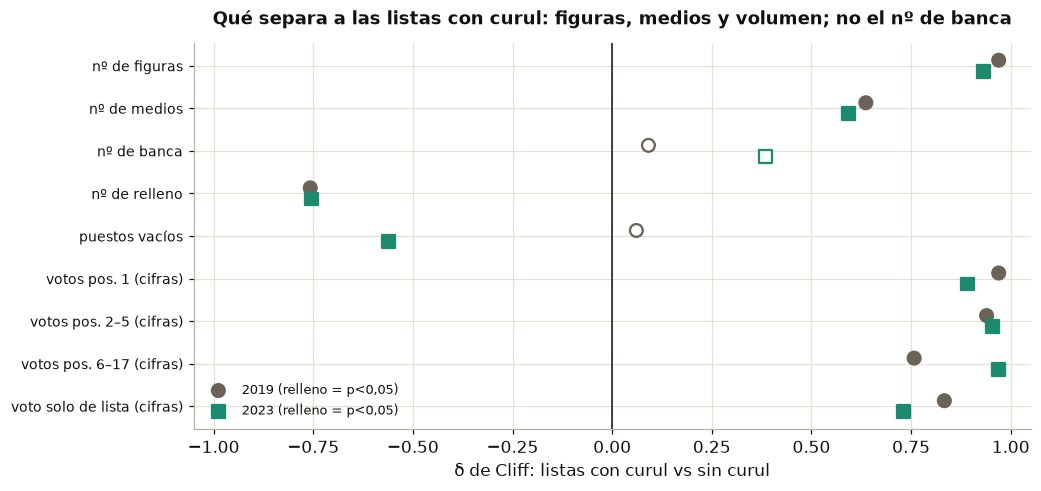

In [18]:
# --- 8.5 Pruebas de permutación por ciclo ---
VARS = {"F": "nº de figuras", "M": "nº de medios", "B": "nº de banca", "R": "nº de relleno", "vacios": "puestos vacíos",
        "u_p1": "votos pos. 1 (cifras)", "u_p2_5": "votos pos. 2–5 (cifras)", "u_p6_17": "votos pos. 6–17 (cifras)",
        "u_logo": "voto solo de lista (cifras)"}
rng = np.random.default_rng(2027)
def perm_p(a, b, n=10000):
    x = np.r_[a, b].astype(float); k = len(a); obs = abs(cliff(a, b)); c = 0
    for _ in range(n):
        x = rng.permutation(x); c += abs(cliff(x[:k], x[k:])) >= obs - 1e-12
    return (c + 1)/(n + 1)
filas = []
for v, lbl in VARS.items():
    f = {"variable": lbl}
    for y in (2019, 2023):
        d = AB[AB.anio==y]; g, p = d[d.gano][v].values, d[~d.gano][v].values
        f[f"{y} mediana con"] = np.median(g); f[f"{y} mediana sin"] = np.median(p)
        f[f"{y} δ"] = cliff(g, p); f[f"{y} p"] = perm_p(g, p)
    f["replica"] = ("sí" if f["2019 p"] < .05 and f["2023 p"] < .05 and np.sign(f["2019 δ"]) == np.sign(f["2023 δ"])
                    else "no")
    filas.append(f)
PRUEBAS = pd.DataFrame(filas).set_index("variable")
display(PRUEBAS.round(3))

fig, ax = plt.subplots(figsize=(9.6, 4.6))
yy = np.arange(len(PRUEBAS))[::-1]
for y, mk, col, off in [(2019, "o", "#6B6358", .13), (2023, "s", TEAL, -.13)]:
    sig = PRUEBAS[f"{y} p"] < .05
    ax.scatter(PRUEBAS[f"{y} δ"], yy+off, marker=mk, s=70, color=[col if s else "white" for s in sig],
               edgecolor=col, linewidth=1.5, label=f"{y} (relleno = p<0,05)", zorder=3)
ax.axvline(0, color=INK, lw=1)
ax.set_yticks(yy); ax.set_yticklabels(PRUEBAS.index, fontsize=9)
ax.set_xlim(-1.05, 1.05); ax.set_xlabel("δ de Cliff: listas con curul vs sin curul")
ax.set_title("Qué separa a las listas con curul: figuras, medios y volumen; no el nº de banca", fontsize=11.5)
ax.legend(frameon=False, fontsize=8.5, loc="lower left"); plt.tight_layout(); plt.show()

In [19]:
# Franjas por número de figuras, por ciclo
print("Listas abiertas con curul / total, según el número de figuras (F ≥ 0,225 cifras)\n")
print(f"{'franja':14} {'2019':>8} {'2023':>8} {'total':>8}")
for lbl, m in [("F = 0", AB.F==0), ("F = 1", AB.F==1), ("F = 2", AB.F==2), ("F ≥ 3", AB.F>=3)]:
    out = []
    for y in (2019, 2023, None):
        s = AB[m] if y is None else AB[m & (AB.anio==y)]
        out.append(f"{int(s.gano.sum())}/{len(s)}")
    print(f"{lbl:14} {out[0]:>8} {out[1]:>8} {out[2]:>8}")

print("\nLas 9 listas con exactamente una figura:")
cols = ["anio", "lista", "total", "F", "M", "B", "R", "vacios", "u_p1", "u_p2_5", "u_p6_17", "cur"]
z = AB[AB.F==1][cols].copy(); z["resto_sin_cabeza_u"] = (AB.u_tot - AB.u_p1)[AB.F==1]
display(z.sort_values(["anio", "total"], ascending=[True, False]).round(2))

Listas abiertas con curul / total, según el número de figuras (F ≥ 0,225 cifras)

franja             2019     2023    total
F = 0               0/5     0/10     0/15
F = 1               2/3      3/6      5/9
F = 2               2/2      2/2      4/4
F ≥ 3               7/7      5/5    12/12

Las 9 listas con exactamente una figura:


,anio,lista,total,F,M,B,R,vacios,u_p1,u_p2_5,u_p6_17,cur,resto_sin_cabeza_u
9,2019,BIENESTAR Y UNIDAD SOCIAL - BUS,4464.0,1,2,7,7,0,0.23,0.48,0.26,1,0.78
10,2019,MOVIMIENTO SOCIAL TAREA DE TODOS,4454.0,1,1,11,4,0,0.27,0.39,0.32,1,0.74
12,2019,BARRANCABERMEJA LIBRE HUMANA Y EN PAZ,3600.0,1,2,3,11,0,0.24,0.40,0.15,0,0.58
25,2023,PARTIDO DEMÓCRATA COLOMBIANO,6267.0,1,3,8,5,0,0.42,0.59,0.51,1,1.13
26,2023,PARTIDO POLÍTICO LA FUERZA DE LA PAZ,5600.0,1,4,4,8,0,0.37,0.66,0.31,1,1.02
28,2023,POR UN CAMBIO BUENO Y JUSTO,4073.0,1,1,5,10,0,0.36,0.37,0.23,1,0.65
33,2023,JUNTOS,3096.0,1,1,3,11,1,0.29,0.28,0.15,0,0.47
34,2023,LOS VERIDICOS,3095.0,1,0,6,8,2,0.35,0.23,0.13,0,0.42
36,2023,VAMOS UNIDOS,3033.0,1,0,4,12,0,0.36,0.19,0.16,0,0.39


**Hallazgo 13: Lo que separa a una lista con curul es tener figuras, medios y volumen en las posiciones 2, 17. El número de candidaturas de banca no separa.** `Nivel B`

Variables que separan con p < 0,05 **en los dos ciclos** (δ de Cliff 2019 / 2023): número de figuras (+0,97 / +0,93), número de medios (+0,64 / +0,59), número de relleno (−0,76 / −0,75), votos de la posición 1 (+0,97 / +0,89), **votos de las posiciones 2–5 (+0,94 / +0,95)**, votos de las posiciones 6–17 (+0,76 / +0,97) y voto solo de lista.

**El número de candidaturas de banca (101–500 votos) no separa** en ninguno de los dos años (p = 0,78 y 0,12). Las listas perdedoras tienen casi tanta banca como las ganadoras; lo que les falta son figuras y medios, y les sobra relleno. Esto corrige la lectura anterior de "una figura + 7 de banca": contar banca no basta, hay que sumar sus votos.

Por franjas de figuras, con el criterio único:

| Figuras en la lista | 2019 | 2023 | Total |
|---|:---:|:---:|:---:|
| 0 | 0/5 | 0/10 | **0/15** |
| 1 | 2/3 | 3/6 | 5/9 |
| 2 o más | 9/9 | 7/7 | **16/16** |

Con **una sola figura** la lista queda en zona de riesgo y se decide por cuánto suma el resto: las cinco que ganaron reunieron fuera de la cabeza al menos **0,65 cifras**; las cuatro que perdieron, como máximo **0,58**.

*Lo que NO significa:* "dos figuras garantizan curul" describe 16 listas observadas; dos figuras sin equipo no alcanzarían (8.6 da la cuenta). Y el corte de 0,65 cifras en la franja de una figura es aritmética: cabeza + resto = total.

### 8.6 La ecuación de la curul

Si el total de una lista es la suma de lo que aporta cada candidatura, se puede estimar cuánto aporta **en promedio** cada tipo con una regresión lineal sin intercepto:

$$u_{\text{lista}} = \beta_F\,F + \beta_M\,M + \beta_B\,B + \beta_R\,R + \varepsilon$$

donde `u` es el total de la lista en cifras y F, M, B, R son las cantidades de cada tipo (F + M + B + R ≤ 17). Cada β incluye el voto solo de lista que en promedio acompaña a ese tipo. La lista obtiene **s curules cuando u ≥ s** (en 2023 bastaba u ≥ 0,953 por curul para conservarla, ver 8.1).

**Validación:** se estima la ecuación con un ciclo y se predice el otro, sin reajustar.

In [20]:
# --- 8.6 Ecuación de la curul: mínimos cuadrados sin intercepto, por ciclo y validación cruzada ---
XV = ["F", "M", "B", "R"]
def ols(d):
    X = d[XV].values.astype(float); yv = d.u_tot.values
    b, *_ = np.linalg.lstsq(X, yv, rcond=None)
    e = yv - X @ b; s2 = e @ e / (len(yv) - len(b))
    se = np.sqrt(np.diag(s2*np.linalg.inv(X.T @ X)))
    return b, se, np.sqrt(np.mean(e**2))
filas, BETA = [], {}
for y in (2019, 2023, "ambos"):
    d = AB if y == "ambos" else AB[AB.anio==y]
    b, se, rmse = ols(d); BETA[y] = b
    filas.append({"ciclo": y, "n listas": len(d), **{f"β{k}": b[i] for i, k in enumerate(XV)},
                  **{f"ee {k}": se[i] for i, k in enumerate(XV)}, "error típico (cifras)": rmse})
ECU = pd.DataFrame(filas).set_index("ciclo"); display(ECU.round(3))

print("Validación cruzada entre ciclos (sin reajustar):")
VAL = {}
for tr, te in ((2019, 2023), (2023, 2019)):
    d = AB[AB.anio==te]; pred = d[XV].values @ BETA[tr]
    VAL[te] = pred
    print(f"  ajusta {tr} → predice {te}: r = {np.corrcoef(pred, d.u_tot)[0,1]:.3f} · "
          f"error mediano {np.median(abs(pred-d.u_tot))*CIF[te]:,.0f} votos · "
          f"acierta curul sí/no {((pred>=1)==d.gano).mean():.0%} · "
          f"acierta nº de curules {(np.floor(pred)==d.cur).mean():.0%}")

b = BETA["ambos"]
print("\nEquivalencias (ecuación con los dos ciclos):")
print(f"  1 curul ≈ {1/b[0]:.1f} figuras ≈ {1/b[1]:.1f} medios ≈ {1/b[2]:.0f} bancas")
print(f"  1 figura ≈ {b[0]/b[1]:.1f} medios ≈ {b[0]/b[2]:.1f} bancas ≈ {b[0]/b[3]:.0f} rellenos")

,n listas,βF,βM,βB,βR,ee F,ee M,ee B,ee R,error típico (cifras)
ciclo,,,,,,,,,,
2019,17,0.388,0.140,0.061,0.004,0.017,0.021,0.009,0.007,0.116
2023,23,0.338,0.162,0.063,0.012,0.007,0.010,0.005,0.003,0.070
ambos,40,0.355,0.155,0.063,0.009,0.009,0.011,0.005,0.003,0.109


Validación cruzada entre ciclos (sin reajustar):
  ajusta 2019 → predice 2023: r = 0.995 · error mediano 375 votos · acierta curul sí/no 96% · acierta nº de curules 87%
  ajusta 2023 → predice 2019: r = 0.988 · error mediano 551 votos · acierta curul sí/no 100% · acierta nº de curules 88%

Equivalencias (ecuación con los dos ciclos):
  1 curul ≈ 2.8 figuras ≈ 6.4 medios ≈ 16 bancas
  1 figura ≈ 2.3 medios ≈ 5.7 bancas ≈ 38 rellenos


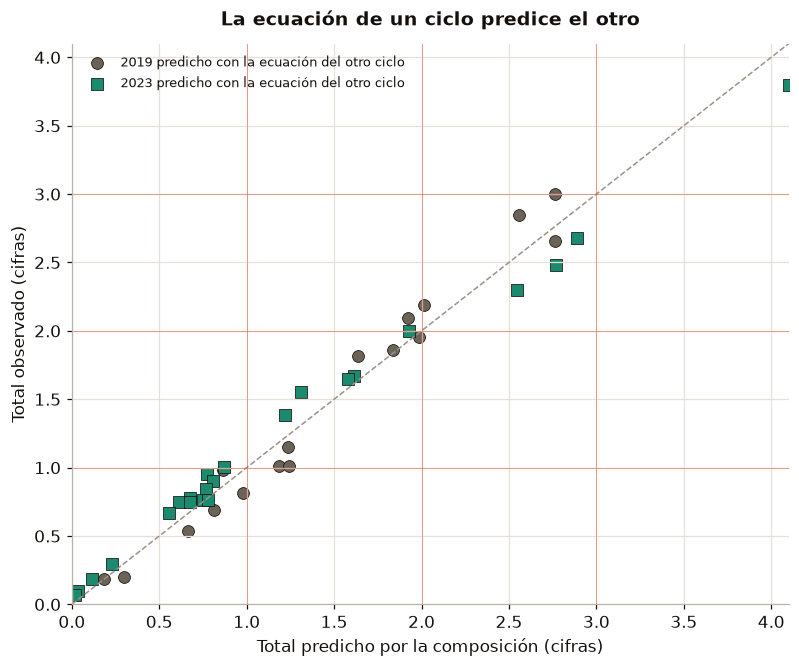

In [21]:
# Gráfico: predicción fuera de muestra vs total observado
fig, ax = plt.subplots(figsize=(7.4, 6.2))
for y, mk, col in [(2019, "o", "#6B6358"), (2023, "s", TEAL)]:
    d = AB[AB.anio==y]
    ax.scatter(VAL[y], d.u_tot, marker=mk, s=60, color=col, edgecolor=INK, lw=.5,
               label=f"{y} predicho con la ecuación del otro ciclo")
lim = [0, 4.1]; ax.plot(lim, lim, color=MUTED, ls="--", lw=1)
for s in (1, 2, 3):
    ax.axhline(s, color=VERM, lw=.6, alpha=.5); ax.axvline(s, color=VERM, lw=.6, alpha=.5)
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Total predicho por la composición (cifras)"); ax.set_ylabel("Total observado (cifras)")
ax.set_title("La ecuación de un ciclo predice el otro", fontsize=12.5)
ax.legend(frameon=False, fontsize=8.6, loc="upper left"); plt.tight_layout(); plt.show()

**Hallazgo 14: Una curul se puede escribir como una ecuación, y la ecuación es la misma en los dos ciclos.** `Nivel B`

Con los dos ciclos juntos (40 listas abiertas), en cifras repartidoras:

$$u_{\text{lista}} \approx 0{,}355\,F + 0{,}155\,M + 0{,}063\,B + 0{,}009\,R$$

Estimada por separado, los coeficientes son muy parecidos (figura 0,39 en 2019 y 0,34 en 2023; medio 0,14 y 0,16; banca 0,061 y 0,063). Ajustada con 2019, la ecuación predice el total de las listas de 2023 con **r = 0,995** (error mediano 375 votos) y acierta si la lista tuvo o no curul en **96 %** de los casos; ajustada con 2023, predice 2019 con r = 0,988 (error mediano 551 votos) y acierta el 100 %.

Las equivalencias que se desprenden son:

- **1 curul ≈ 2,8 figuras ≈ 6,4 medios ≈ 16 bancas.**
- **1 figura ≈ 2,3 medios ≈ 5,7 bancas.**

Con 17 puestos, el mínimo para una curul con **una sola figura** sale de despejar: 0,355 + 0,155·M + 0,063·B + 0,009·R ≥ 1. Sin medios hacen falta al menos 10 bancas; con un medio, 7 bancas; con dos medios, 4 bancas, completando el resto con relleno.

*Lo que NO significa:* la ecuación da el **promedio** de cada tipo. Una figura concreta puede valer 0,23 o 0,6 cifras; por eso 8.7 simula la variación real. Y supone que los votos de cada candidatura se suman sin restarse entre sí, algo que la validación entre ciclos respalda para las listas observadas.

### 8.7 Simulación con 17 puestos: qué combinaciones dan una, dos o tres curules

La ecuación da promedios. Para obtener **probabilidades** se simula: para una composición dada (F, M, B, R con F + M + B + R = 17) se sortea el voto de cada candidatura **de las candidaturas reales de ese mismo tipo** observadas en 2019 y 2023 (en cifras), se suma, se agrega el voto solo de lista con la proporción observada en una lista real elegida al azar, y se cuentan las curules (u ≥ 1, ≥ 2, ≥ 3). Cada composición se simula 4.000 veces (*bootstrap* paramétrico-libre).

**Validación previa:** cada lista observada se simula con su composición real usando **solo las candidaturas del otro ciclo**, y se compara con lo que pasó.

In [22]:
# --- 8.7 Simulación de listas de 17 puestos ---
rng = np.random.default_rng(2027)
POOL = {y: {k: ce[(ce.anio==y) & (ce.tipo==k)].u.values for k in "FMBR"} for y in (2019, 2023)}
POOL["ambos"] = {k: np.r_[POOL[2019][k], POOL[2023][k]] for k in "FMBR"}
LOGO = {y: (AB[AB.anio==y].logo/(AB[AB.anio==y].total-AB[AB.anio==y].logo)).values for y in (2019, 2023)}
LOGO["ambos"] = np.r_[LOGO[2019], LOGO[2023]]

def simular(F=0, M=0, B=0, R=0, pool="ambos", n=4000):
    "Totales simulados (en cifras) de una lista con esa composición."
    tot = np.zeros(n)
    for k, c in zip("FMBR", (F, M, B, R)):
        if c: tot += rng.choice(POOL[pool][k], size=(n, c)).sum(1)
    return tot*(1 + rng.choice(LOGO[pool], size=n))

def curules_de(u): return np.floor(u + 1e-9).astype(int)

# Validación fuera de muestra
filas = []
for _, r in AB.iterrows():
    otro = 2023 if r.anio == 2019 else 2019
    u = simular(r.F, r.M, r.B, r.R, pool=otro, n=8000); s = curules_de(u)
    filas.append(dict(anio=r.anio, lista=r.lista[:34], F=r.F, M=r.M, B=r.B, R=r.R, curules=r.cur,
                      p_curul=(s>=1).mean(), curules_mas_probable=np.bincount(s).argmax(),
                      u_obs=r.u_tot, u_p10=np.percentile(u, 10), u_p90=np.percentile(u, 90)))
SIMV = pd.DataFrame(filas)
for y in (2019, 2023):
    d = SIMV[SIMV.anio==y]; g = d.curules > 0
    brier = ((d.p_curul - g)**2).mean(); base = ((g.mean() - g)**2).mean()
    print(f"{y}: acierta curul sí/no {((d.p_curul>=.5)==g).mean():.0%} · acierta nº de curules "
          f"{(d.curules_mas_probable==d.curules).mean():.0%} · Brier {brier:.3f} (sin modelo {base:.3f}) · "
          f"total observado dentro del intervalo 80 %: {((d.u_obs>=d.u_p10)&(d.u_obs<=d.u_p90)).mean():.0%}")
display(SIMV.round(2))

2019: acierta curul sí/no 94% · acierta nº de curules 76% · Brier 0.016 (sin modelo 0.228) · total observado dentro del intervalo 80 %: 76%
2023: acierta curul sí/no 96% · acierta nº de curules 96% · Brier 0.033 (sin modelo 0.246) · total observado dentro del intervalo 80 %: 96%


,anio,lista,F,M,B,R,curules,p_curul,curules_mas_probable,u_obs,u_p10,u_p90
0,2019,PARTIDO CAMBIO RADICAL,6,2,6,3,3,1.00,2,3.00,2.52,3.17
1,2019,PARTIDO LIBERAL COLOMBIANO,6,0,8,2,2,1.00,2,2.85,2.28,2.92
2,2019,MOVIMIENTO ALTERNATIVO INDIGENA Y,4,6,7,0,2,1.00,2,2.66,2.59,3.18
3,2019,SUMEMOS,2,5,8,2,2,1.00,2,2.19,1.86,2.33
4,2019,PARTIDO ALIANZA SOCIAL INDEPENDIEN,3,3,6,4,2,1.00,1,2.09,1.74,2.25
5,2019,CIVICOS AL 100%,3,3,7,4,1,1.00,2,1.96,1.80,2.31
6,2019,PARTIDO ALIANZA VERDE,3,2,7,5,1,1.00,1,1.86,1.64,2.12
7,2019,PARTIDO POLO DEMOCRATICO ALTERNATI,3,1,6,7,1,1.00,1,1.82,1.44,1.91
8,2019,PARTIDO SOCIAL DE UNIDAD NACIONAL,2,1,5,7,1,0.98,1,1.15,1.07,1.45
9,2019,BIENESTAR Y UNIDAD SOCIAL - BUS,1,2,7,7,1,0.96,1,1.01,1.04,1.39


Composiciones simuladas: 1,105


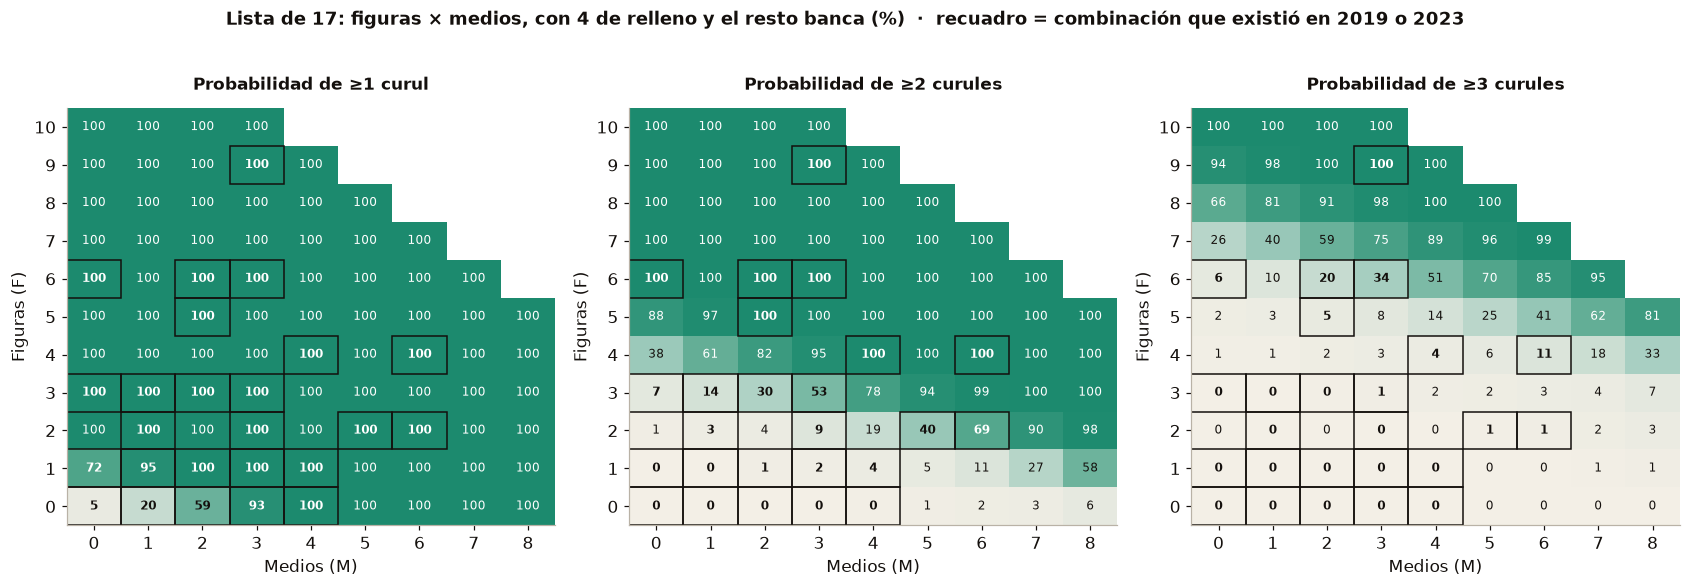

In [23]:
# Todas las composiciones posibles de 17 puestos
filas = []
for F in range(0, 13):
    for M in range(0, 18-F):
        for B in range(0, 18-F-M):
            R = 17-F-M-B
            u = simular(F, M, B, R); s = curules_de(u)
            filas.append(dict(F=F, M=M, B=B, R=R, p1=(s>=1).mean(), p2=(s>=2).mean(), p3=(s>=3).mean(),
                              p4=(s>=4).mean(), e_cur=s.mean(), u_med=np.median(u),
                              fig_sin_curul=np.maximum(F - s, 0).mean()))
GRID = pd.DataFrame(filas)
OBS_FM = set(zip(AB.F, AB.M))        # combinaciones (F, M) que existieron en la realidad
print(f"Composiciones simuladas: {len(GRID):,}")

R_FIJO = 4                            # relleno típico de las listas ganadoras (mediana 4–5)
fig, axes = plt.subplots(1, 3, figsize=(15.5, 5.2))
cmap = LinearSegmentedColormap.from_list("t", ["#F3EFE6", "#A8CFC2", "#58A98F", TEAL])
for ax, (col, tit) in zip(axes, [("p1", "Probabilidad de ≥1 curul"), ("p2", "Probabilidad de ≥2 curules"),
                                  ("p3", "Probabilidad de ≥3 curules")]):
    h = GRID[GRID.R==R_FIJO].pivot(index="F", columns="M", values=col).iloc[:11, :9]
    ax.imshow(h.values, cmap=cmap, vmin=0, vmax=1, aspect="auto", origin="lower")
    for i, F in enumerate(h.index):
        for j, M in enumerate(h.columns):
            v = h.loc[F, M]
            if np.isnan(v): continue
            ax.text(j, i, f"{100*v:.0f}", ha="center", va="center", fontsize=7.6,
                    color="white" if v > .6 else INK,
                    fontweight="bold" if (F, M) in OBS_FM else "normal")
            if (F, M) in OBS_FM:
                ax.add_patch(plt.Rectangle((j-.5, i-.5), 1, 1, fill=False, ec=INK, lw=1))
    ax.set_xticks(range(h.shape[1])); ax.set_xticklabels(h.columns)
    ax.set_yticks(range(h.shape[0])); ax.set_yticklabels(h.index)
    ax.set_xlabel("Medios (M)"); ax.set_ylabel("Figuras (F)"); ax.set_title(tit, fontsize=11); ax.grid(False)
fig.suptitle(f"Lista de 17: figuras × medios, con {R_FIJO} de relleno y el resto banca (%)  ·  "
             "recuadro = combinación que existió en 2019 o 2023", fontsize=11.5, fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

Figuras mínimas para alcanzar la meta con probabilidad ≥ 80 % (lista de 17, relleno = 4, resto banca)



,meta,medios,figuras mínimas,banca,relleno,probabilidad,curules esperadas,figuras sin curul esperadas,combinación observada
0,1 curul,0,2,11,4,1.00,1.01,0.99,no
1,1 curul,1,1,11,4,0.95,0.95,0.05,sí
2,1 curul,2,1,10,4,1.00,1.01,0.00,sí
3,1 curul,3,0,10,4,0.93,0.94,0.00,sí
4,1 curul,4,0,9,4,1.00,1.00,0.00,sí
5,1 curul,5,0,8,4,1.00,1.01,0.00,no
6,1 curul,6,0,7,4,1.00,1.02,0.00,no
7,2 curules,0,5,8,4,0.88,1.90,3.10,no
8,2 curules,1,5,7,4,0.97,2.00,3.00,no
9,2 curules,2,4,7,4,0.82,1.84,2.15,no


,F,B,curules esperadas,curul extra por la figura,p1,p2,p3,figuras sin curul esperadas
61,0,10,0.94,NaN,0.93,0.00,0.00,0.00
228,1,9,1.02,0.08,1.00,0.02,0.00,0.00
377,2,8,1.09,0.08,1.00,0.09,0.00,0.91
509,3,7,1.54,0.44,1.00,0.53,0.01,1.46
625,4,6,1.98,0.45,1.00,0.95,0.03,2.02
726,5,5,2.08,0.10,1.00,1.00,0.08,2.92
813,6,4,2.36,0.28,1.00,1.00,0.34,3.64
887,7,3,2.79,0.43,1.00,1.00,0.75,4.21
949,8,2,3.06,0.27,1.00,1.00,0.98,4.94
1000,9,1,3.26,0.20,1.00,1.00,1.00,5.74


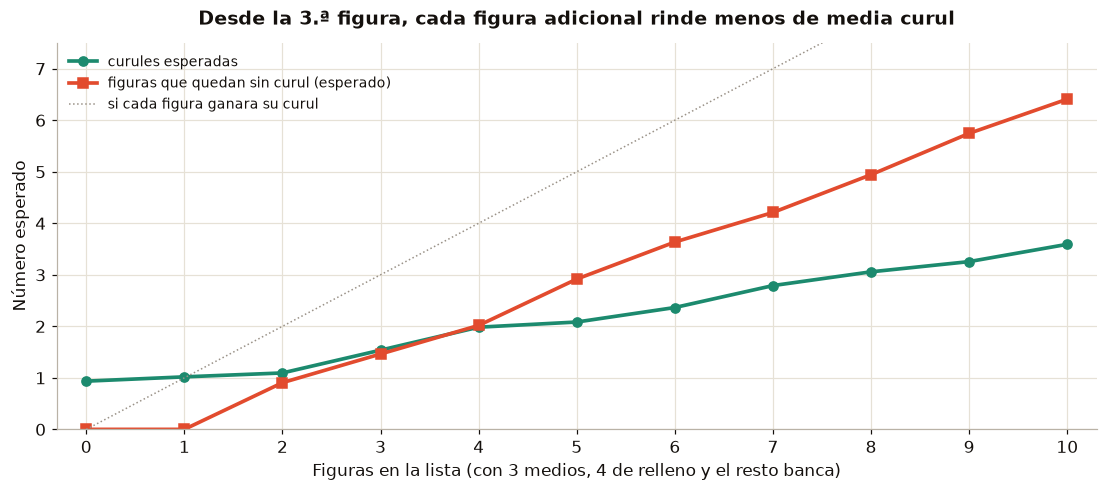

In [24]:
# Recetas mínimas y rendimiento de cada figura adicional
print("Figuras mínimas para alcanzar la meta con probabilidad ≥ 80 % (lista de 17, relleno = 4, resto banca)\n")
filas = []
for meta, col in ((1, "p1"), (2, "p2"), (3, "p3")):
    for M in range(0, 7):
        d = GRID[(GRID.R==R_FIJO) & (GRID.M==M) & (GRID[col]>=.8)].sort_values("F")
        if len(d):
            r = d.iloc[0]
            filas.append({"meta": f"{meta} curul" + ("es" if meta > 1 else ""), "medios": M, "figuras mínimas": int(r.F),
                          "banca": int(r.B), "relleno": int(r.R), "probabilidad": r[col], "curules esperadas": r.e_cur,
                          "figuras sin curul esperadas": r.fig_sin_curul,
                          "combinación observada": "sí" if (int(r.F), M) in OBS_FM else "no"})
RECETAS = pd.DataFrame(filas); display(RECETAS.round(2))

M_FIJO = 3
d = GRID[(GRID.M==M_FIJO) & (GRID.R==R_FIJO)].sort_values("F").copy()
d["curul extra por la figura"] = d.e_cur.diff()
display(d[["F", "B", "e_cur", "curul extra por la figura", "p1", "p2", "p3", "fig_sin_curul"]].round(2)
        .rename(columns={"e_cur": "curules esperadas", "fig_sin_curul": "figuras sin curul esperadas"}))

fig, ax = plt.subplots(figsize=(10.2, 4.6))
ax.plot(d.F, d.e_cur, marker="o", lw=2.4, color=TEAL, label="curules esperadas")
ax.plot(d.F, d.fig_sin_curul, marker="s", lw=2.4, color=VERM, label="figuras que quedan sin curul (esperado)")
ax.plot([0, 10], [0, 10], color=MUTED, ls=":", lw=1, label="si cada figura ganara su curul")
ax.set_xlim(-.3, 10.3); ax.set_ylim(0, 7.5); ax.set_xticks(range(0, 11))
ax.set_xlabel(f"Figuras en la lista (con {M_FIJO} medios, {R_FIJO} de relleno y el resto banca)")
ax.set_ylabel("Número esperado")
ax.set_title("Desde la 3.ª figura, cada figura adicional rinde menos de media curul", fontsize=12.3)
ax.legend(frameon=False, fontsize=9); plt.tight_layout(); plt.show()

**Hallazgo 15: Con 17 puestos: una curul pide 1 figura y 1,2 medios; dos curules, 4 figuras; tres curules, 7 u 8 figuras, y dejan 4,5 figuras sin puesto.** `Nivel B/C`

La simulación reproduce lo observado: con las candidaturas de un ciclo predice el otro y acierta si la lista tuvo o no curul en 94 % (2019) y 96 % (2023) de los casos, y el número exacto de curules en 76 % y 96 %.

Sobre todas las combinaciones de 17 puestos (relleno = 4, resto banca), las recetas con probabilidad ≥ 80 %:

| Meta | Receta mínima | Probabilidad | Figuras que quedan sin curul (esperado) |
|---|---|:---:|:---:|
| **1 curul** | 1 figura + 1 medio + 11 banca + 4 relleno | 95 % | 0 |
| **1 curul** | 1 figura + 2 medios + 10 banca + 4 relleno | ≈100 % | 0 |
| **2 curules** | 4 figuras + 3 medios + 6 banca + 4 relleno | 95 % | 2 |
| **3 curules** | 8 figuras + 3 medios + 2 banca + 4 relleno | 98 % | 5 |
| **3 curules** | 7 figuras + 4 medios + 2 banca + 4 relleno | 89 % | 4 |

**Cuántas figuras convienen.** Con 3 medios fijos, la 2.ª figura casi no suma curules (+0,08: la lista ya tenía una); la **3.ª y la 4.ª** son las que llevan a la segunda curul (+0,44 y +0,45 cada una); la 5.ª aporta +0,10 y de la 6.ª a la 8.ª entre +0,27 y +0,43, porque empujan hacia la tercera. Cada figura por encima de las curules que la lista hará queda sin puesto: con 8 figuras se esperan 3 curules y **5 figuras sin curul**. El costo personal de buscar la tercera curul es alto, y la cuarta prácticamente no está al alcance con 17 puestos.

*Lo que NO significa:* las celdas sin recuadro son combinaciones que **no existieron** en 2019 ni 2023; en ellas el resultado es extrapolación de la suma. En particular, la simulación dice que una lista sin figuras pero con 3–4 medios podría ganar, pero en la realidad **ninguna** de las 15 listas sin figura lo logró (Conservador – MIRA, con 4 medios, quedó a 190 votos): quien no consigue figura tampoco suele conseguir el resto. La simulación cuenta curules con u ≥ 1 cifra, un criterio algo exigente: para conservar una curul bastaba 0,95–0,98 cifras (8.1).

### 8.8 Cuánto le faltó a cada lista y cuánto le sobró

Para cada lista se calcula de forma **exacta**, recalculando el reparto completo con el umbral (los demás totales fijos):

- **Falta para la siguiente curul:** votos adicionales mínimos para ganar una curul más (para una lista sin curul, la primera).
- **Sobrante:** votos que la lista podía perder y conservar sus curules. Son votos que **no se convirtieron en curul**.

Luego se expresan en **equivalentes**: figuras medianas del año (1.447 votos en 2019; 1.248 en 2023) y bancas medianas (211 y 183).

In [25]:
# --- 8.8 Márgenes exactos por lista ---
def curules_con(y, lista, V):
    T = totales(y); dv = V - T[lista]; T[lista] = V
    s, _, _ = reparto(T, 0.5*(VALIDOS[y] + dv)/CURULES)
    return s[lista]

def minimo_para(y, lista, meta, lo, hi):
    "Menor total de la lista que le da al menos `meta` curules (búsqueda binaria)."
    for _ in range(50):
        m = (lo + hi)/2
        if curules_con(y, lista, m) >= meta: hi = m
        else: lo = m
    return int(np.ceil(hi))

MED_F = {y: ce[(ce.anio==y) & (ce.tipo=="F")].votos.median() for y in (2019, 2023)}
MED_B = {y: ce[(ce.anio==y) & (ce.tipo=="B")].votos.median() for y in (2019, 2023)}
filas = []
for y in (2019, 2023):
    for lista, V in totales(y).items():
        s = SEATS[y][lista]
        minimo = minimo_para(y, lista, s, 0, V) if s else np.nan
        siguiente = minimo_para(y, lista, s+1, V, 4*V + 20000)
        filas.append(dict(anio=y, lista=lista, votos=int(V), curules=s, minimo_para_conservar=minimo,
                          sobrante=V - minimo if s else np.nan, falta_siguiente=siguiente - V))
MARG = pd.DataFrame(filas)
MARG["falta en figuras"] = MARG.falta_siguiente / MARG.anio.map(MED_F)
MARG["falta en bancas"]  = MARG.falta_siguiente / MARG.anio.map(MED_B)
MARG["sobrante en figuras"] = MARG.sobrante / MARG.anio.map(MED_F)
display(MARG.sort_values(["anio", "votos"], ascending=[True, False]).round(2))

print("Votos que no se convirtieron en curul (sobrantes de listas con curul + votos de listas sin curul):")
for y in (2019, 2023):
    d = MARG[MARG.anio==y]
    sob = d.sobrante.sum(); perd = d[d.curules==0].votos.sum()
    print(f"  {y}: sobrantes {sob:,.0f} + listas sin curul {perd:,.0f} = {sob+perd:,.0f} "
          f"({100*(sob+perd)/VALIDOS[y]:.1f} % de los válidos, que incluyen {int(ag[(ag.corporacion=='CONCEJO')&(ag.anio==y)].votos_blanco.iloc[0]):,} en blanco)")

,anio,lista,votos,curules,minimo_para_conservar,sobrante,falta_siguiente,falta en figuras,falta en bancas,sobrante en figuras
0,2019,PARTIDO CAMBIO RADICAL,13236,3,13024.0,212.0,4580.0,3.17,21.71,0.15
1,2019,PARTIDO LIBERAL COLOMBIANO,12574,2,8683.0,3891.0,663.0,0.46,3.14,2.69
2,2019,MOVIMIENTO ALTERNATIVO INDIGENA Y SOCIAL MAIS,11720,2,8683.0,3037.0,1517.0,1.05,7.19,2.10
3,2019,SUMEMOS,9665,2,8683.0,982.0,3572.0,2.47,16.93,0.68
4,2019,PARTIDO ALIANZA SOCIAL INDEPENDIENTE ASI,9243,2,8683.0,560.0,3994.0,2.76,18.93,0.39
5,2019,CIVICOS AL 100%,8641,1,4341.0,4300.0,184.0,0.13,0.87,2.97
6,2019,PARTIDO ALIANZA VERDE,8208,1,4341.0,3867.0,617.0,0.43,2.92,2.67
7,2019,PARTIDO POLO DEMOCRATICO ALTERNATIVO,8020,1,4341.0,3679.0,805.0,0.56,3.82,2.54
8,2019,PARTIDO SOCIAL DE UNIDAD NACIONAL PARTIDO DE ...,5085,1,4341.0,744.0,3740.0,2.58,17.73,0.51
9,2019,BIENESTAR Y UNIDAD SOCIAL - BUS,4464,1,4342.0,122.0,4361.0,3.01,20.67,0.08


Votos que no se convirtieron en curul (sobrantes de listas con curul + votos de listas sin curul):
  2019: sobrantes 21,507 + listas sin curul 16,179 = 37,686 (32.5 % de los válidos, que incluyen 4,428 en blanco)
  2023: sobrantes 21,545 + listas sin curul 32,799 = 54,344 (43.5 % de los válidos, que incluyen 5,207 en blanco)


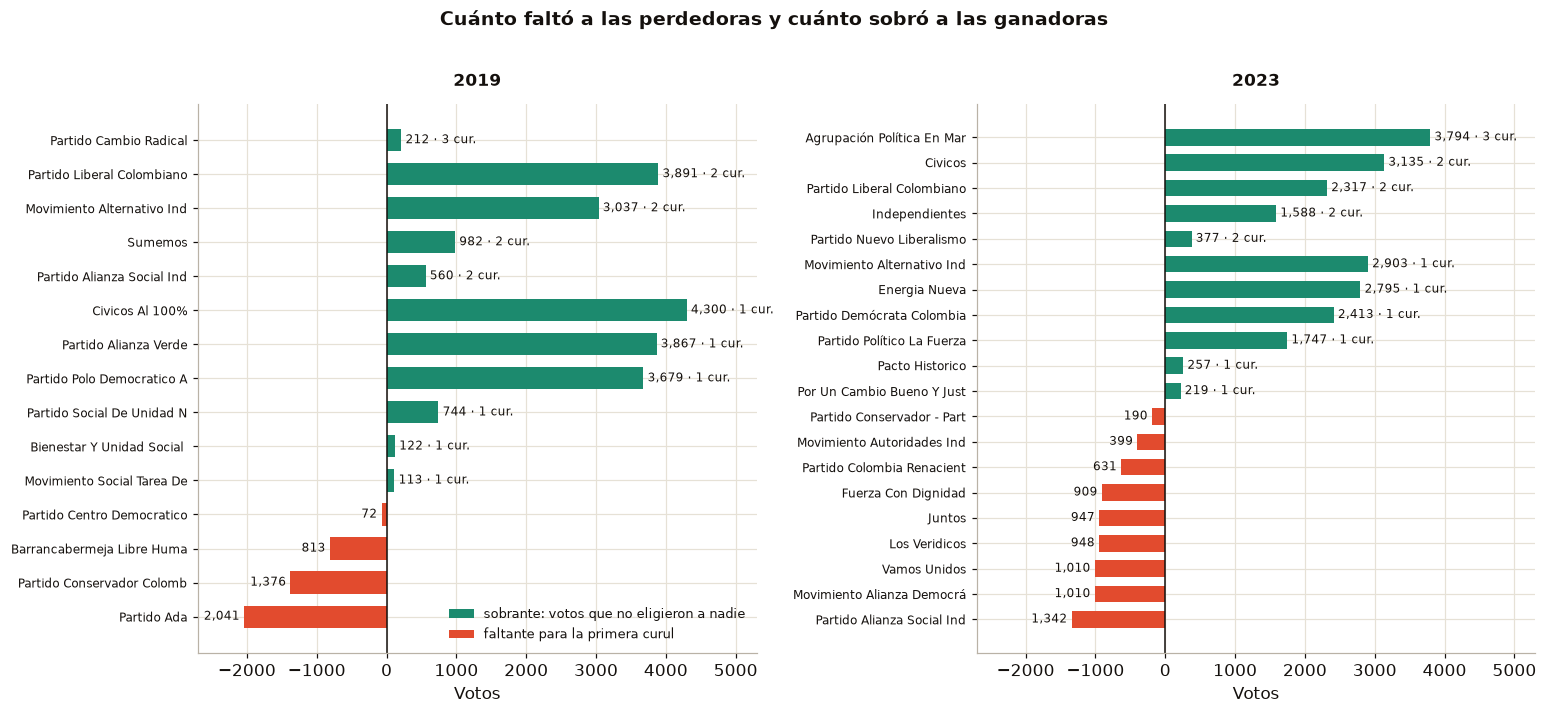

In [26]:
# Gráfico: márgenes de cada lista, en votos
fig, axes = plt.subplots(1, 2, figsize=(14.2, 6.4))
for ax, y in zip(axes, (2019, 2023)):
    d = MARG[(MARG.anio==y) & (MARG.votos >= 0.5*CIF[y])].sort_values("votos")
    pos = np.arange(len(d))
    sob = d.sobrante.fillna(0).values; fal = d.falta_siguiente.values
    gan = d.curules.values > 0
    ax.barh(pos[gan], sob[gan], color=TEAL, height=.65, label="sobrante: votos que no eligieron a nadie")
    ax.barh(pos[~gan], -fal[~gan], color=VERM, height=.65, label="faltante para la primera curul")
    for p, r in zip(pos, d.itertuples()):
        if r.curules:
            ax.text(r.sobrante + 60, p, f"{int(r.sobrante):,} · {r.curules} cur.", va="center", fontsize=7.6)
        else:
            ax.text(-r.falta_siguiente - 60, p, f"{int(r.falta_siguiente):,}", va="center", ha="right", fontsize=7.6)
    ax.set_yticks(pos); ax.set_yticklabels([l.title()[:26] for l in d.lista], fontsize=7.8)
    ax.axvline(0, color=INK, lw=1); ax.set_xlim(-2700, 5300); ax.set_axisbelow(True)
    ax.set_title(f"{y}", fontsize=11); ax.set_xlabel("Votos")
axes[0].legend(frameon=False, fontsize=8.2, loc="lower right")
fig.suptitle("Cuánto faltó a las perdedoras y cuánto sobró a las ganadoras", fontsize=12.5, fontweight="bold", y=1.01)
plt.tight_layout(); plt.show()

**Hallazgo 16: A las perdedoras cercanas les faltó menos de una figura; a varias ganadoras les sobraron más de dos.** `Nivel A/B`

- **Les faltó menos de una figura.** En 2023, Conservador – MIRA quedó a **190 votos** de la curul (≈1 banca), AICO a 399 (≈2 bancas), y Fuerza con Dignidad, Juntos, Los Verídicos, Alianza Democrática Amplia y Vamos Unidos a entre **909 y 1.010 votos**: entre 0,73 y 0,81 figuras medianas, o unas 5 bancas medianas cada una. En 2019, Centro Democrático quedó a **72 votos**.
- **Les sobró mucho.** En 2023 En Marcha tuvo **3.794 votos sobrantes** (3,0 figuras medianas), Cívicos 3.135 y MAIS 2.903. En 2019, Cívicos al 100 % tuvo 4.300 sobrantes y quedó a 184 votos de una segunda curul.
- **Votos que no eligieron a nadie.** Sumando sobrantes y votos de listas sin curul: **37.686 en 2019 (32,5 % de los válidos)** y **54.344 en 2023 (43,5 %)**. Ese porcentaje creció 11 puntos entre ciclos, en línea con el aumento de listas que compitieron sin llegar a la cifra.

*Lo que NO significa:* el sobrante es inevitable en un reparto proporcional; toda lista con curul tiene algo. Lo que muestra es **dónde estuvo la ineficiencia**: votos concentrados en listas que ya tenían sus curules aseguradas, mientras otras listas quedaban a menos de una figura de la suya.

### 8.9 Los 978 votos entre Los Verídicos y Por un Cambio Bueno y Justo

Las dos listas de 2023 tenían una sola figura de tamaño parecido. Una sumó 3.095 votos y se quedó sin curul; la otra, 4.073 y ganó. La pregunta es de dónde salen exactamente los 978 votos de diferencia. Se responde posición por posición.

,votos,% de la diferencia
posición 1 (la figura),38,3.9
posición 2,406,41.5
posiciones 3–5,166,17.0
posiciones 6–15,349,35.7
posiciones 16–17,68,7.0
voto solo de lista,-49,-5.0
TOTAL,978,100.0


Los Verídicos                  total 3,095 · 15 candidaturas con voto · F=1 M=0 B=6 R=8 · vacíos 2
Por un Cambio Bueno y Justo    total 4,073 · 17 candidaturas con voto · F=1 M=1 B=5 R=10 · vacíos 0

978 votos = 0.242 cifras ≈ 0.78 figuras medianas ≈ 5.3 bancas medianas
Lo que le faltaba a Los Verídicos para la curul: 948 votos


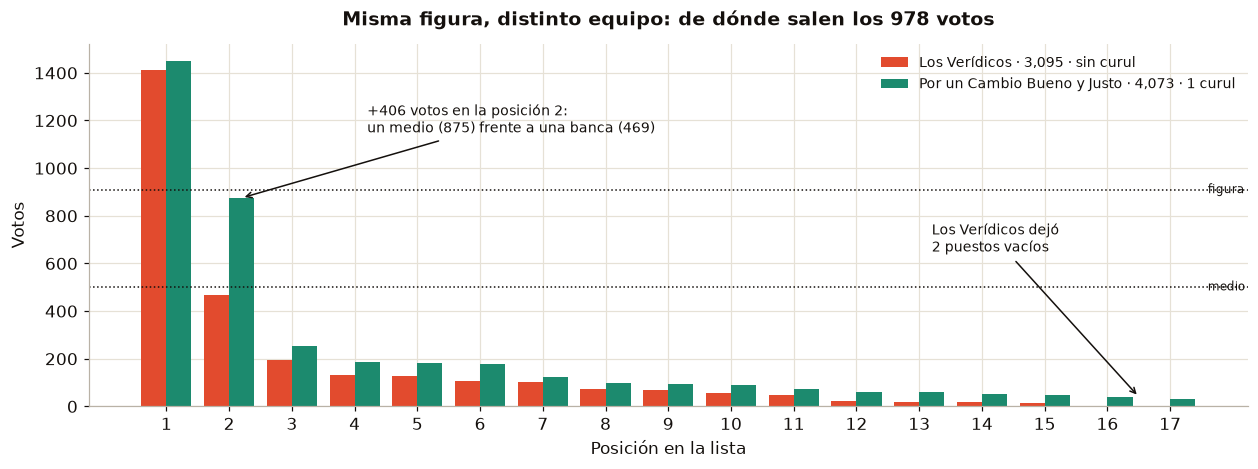

In [27]:
# --- 8.9 Descomposición posición por posición de la diferencia entre dos listas ---
A_ = LST[(LST.anio==2023) & (LST.lista=="LOS VERIDICOS")].iloc[0]
B_ = LST[(LST.anio==2023) & (LST.lista=="POR UN CAMBIO BUENO Y JUSTO")].iloc[0]
dif = (B_[P17] - A_[P17]).astype(float).values
tramos = {"posición 1 (la figura)": dif[0], "posición 2": dif[1], "posiciones 3–5": dif[2:5].sum(),
          "posiciones 6–15": dif[5:15].sum(), "posiciones 16–17": dif[15:].sum(),
          "voto solo de lista": B_.logo - A_.logo}
TR = pd.Series(tramos); TR["TOTAL"] = TR.sum()
display(pd.DataFrame({"votos": TR.astype(int), "% de la diferencia": (100*TR/TR["TOTAL"]).round(1)}))
for nombre, r in (("Los Verídicos", A_), ("Por un Cambio Bueno y Justo", B_)):
    print(f"{nombre:30} total {int(r.total):,} · {int(r.n_cand)} candidaturas con voto · "
          f"F={r.F} M={r.M} B={r.B} R={r.R} · vacíos {r.vacios}")
d978 = TR["TOTAL"]; b = BETA["ambos"]
print(f"\n978 votos = {d978/CIF[2023]:.3f} cifras ≈ {d978/MED_F[2023]:.2f} figuras medianas ≈ "
      f"{d978/MED_B[2023]:.1f} bancas medianas")
print(f"Lo que le faltaba a Los Verídicos para la curul: {int(MARG[(MARG.anio==2023)&(MARG.lista=='LOS VERIDICOS')].falta_siguiente.iloc[0])} votos")

fig, ax = plt.subplots(figsize=(11.6, 4.4))
x = np.arange(1, 18); w = .4
ax.set_axisbelow(True)
ax.bar(x - w/2, A_[P17].values.astype(float), w, color=VERM, label=f"Los Verídicos · {int(A_.total):,} · sin curul")
ax.bar(x + w/2, B_[P17].values.astype(float), w, color=TEAL, label=f"Por un Cambio Bueno y Justo · {int(B_.total):,} · 1 curul")
ax.axhline(CUT["F"]*CIF[2023], color=INK, ls=":", lw=1); ax.text(17.6, CUT["F"]*CIF[2023], "figura", fontsize=8, va="center")
ax.axhline(CUT["M"]*CIF[2023], color=INK, ls=":", lw=1); ax.text(17.6, CUT["M"]*CIF[2023], "medio", fontsize=8, va="center")
ax.annotate("+406 votos en la posición 2:\nun medio (875) frente a una banca (469)", xy=(2.2, 875), xytext=(4.2, 1150),
            fontsize=9, arrowprops=dict(arrowstyle="->", color=INK))
ax.annotate("Los Verídicos dejó\n2 puestos vacíos", xy=(16.5, 40), xytext=(13.2, 650), fontsize=9,
            arrowprops=dict(arrowstyle="->", color=INK))
ax.set_xticks(x); ax.set_xlabel("Posición en la lista"); ax.set_ylabel("Votos")
ax.set_title("Misma figura, distinto equipo: de dónde salen los 978 votos", fontsize=12.5)
ax.legend(frameon=False, fontsize=9); plt.tight_layout(); plt.show()

**Hallazgo 17: Los 978 votos no son "un integrante de banca más": equivalen a 0,8 figuras, y vienen del número 2 y de toda la cola.** `Nivel A`

Las dos listas tenían una figura casi idéntica (1.412 y 1.450 votos). La diferencia se reparte así:

| Tramo | Votos | % de la diferencia |
|---|:---:|:---:|
| Posición 1 (la figura) | +38 | 4 % |
| **Posición 2** | **+406** | **42 %** |
| Posiciones 3–5 | +166 | 17 % |
| Posiciones 6–15 | +349 | 36 % |
| Posiciones 16–17 (vacías en Los Verídicos) | +68 | 7 % |
| Voto solo de lista | −49 | −5 % |

Con el criterio único: Por un Cambio Bueno y Justo era **1 figura + 1 medio + 5 banca + 10 relleno**, y Los Verídicos **1 figura + 0 medios + 6 banca + 8 relleno + 2 puestos vacíos**. Lo decisivo fue tener un **número 2 de nivel medio** (875 votos frente a 469) y que cada una de las posiciones 3 a 17 sumara algo más. Los 978 votos son **0,24 cifras ≈ 0,78 figuras medianas ≈ 5,3 bancas medianas**; a Los Verídicos le bastaban **948** para la curul.

*Lo que NO significa:* son dos listas, no una regla. Pero el mecanismo coincide con 8.3, 8.5: con una sola figura, la curul la decide el número 2 y el volumen del resto, no cuántos nombres de banca haya.

### 8.10 En Marcha 2023: ¿cuántas de sus seis figuras sin curul eran necesarias?

En Marcha sacó **15.354 votos y 3 curules** con 9 figuras: 3 elegidas y 6 sin curul (7.248 votos entre las seis). Para saber cuántas de esas seis hacían falta se recalcula el reparto **exacto** de 2023, con umbral y cifra repartidora, en las **64 combinaciones posibles** de conservar o quitar a cada una de las seis, manteniendo fijos todos los demás votos.

Primero, el umbral relevante. Para **conservar** su tercera curul, En Marcha no necesitaba 3 × 4.042: necesitaba que su tercer cociente (votos ÷ 3) no cayera por debajo del siguiente cociente en la fila, que era el de Conservador – MIRA (3.853). Es decir, **3 × 3.853 ≈ 11.559 votos**.

In [28]:
# --- 8.10 En Marcha: enumeración exacta de las 64 combinaciones ---
from itertools import combinations
EM = "AGRUPACIÓN POLÍTICA EN MARCHA"
d = ce[(ce.anio==2023) & (ce.nombre_partido==EM)].sort_values("votos", ascending=False)
V_EM = totales(2023)[EM]
elegidas = d[d.electo]; sin_curul = d[(~d.electo) & (d.tipo=="F")]
fs = sin_curul.votos.values.astype(float)
print(f"Total {V_EM:,.0f} · elegidas {elegidas.votos.tolist()} · figuras sin curul {fs.astype(int).tolist()} = {fs.sum():,.0f}")
print(f"Resto de la lista (otras candidaturas + voto de lista): {V_EM - elegidas.votos.sum() - fs.sum():,.0f}\n")

minimo3 = minimo_para(2023, EM, 3, 0, V_EM)
para4   = minimo_para(2023, EM, 4, V_EM, 3*V_EM)
print(f"Mínimo para conservar 3 curules : {minimo3:,} votos (3 × 3.853 = 11.559 empataba con Conservador – MIRA; un empate se sortea)")
print(f"Votos sobrantes                 : {V_EM - minimo3:,.0f}  ({(V_EM-minimo3)/V_EM:.1%} de la lista)")
print(f"Votos para una 4.ª curul        : {para4:,}  (le faltaron {para4 - V_EM:,.0f})")
necesarios = minimo3 - (V_EM - fs.sum())
print(f"De los {fs.sum():,.0f} votos de las seis figuras sin curul, eran necesarios {necesarios:,.0f} "
      f"y sobraban {fs.sum()-necesarios:,.0f}\n")

filas = []
for k in range(7):
    for keep in combinations(range(6), k):
        kept = fs[list(keep)].sum()
        filas.append(dict(conservadas=k, votos_conservados=kept, curules=curules_con(2023, EM, V_EM - fs.sum() + kept),
                          cuales=[int(fs[i]) for i in keep]))
EN = pd.DataFrame(filas)
resumen = EN.groupby("conservadas").agg(combinaciones=("curules", "size"),
                                        con_3_curules=("curules", lambda s: int((s>=3).sum())),
                                        votos_min=("votos_conservados", "min"), votos_max=("votos_conservados", "max"))
display(resumen)
print("Combinaciones de 3 figuras que NO alcanzan:")
display(EN[(EN.conservadas==3) & (EN.curules<3)][["cuales", "votos_conservados", "curules"]])

# ¿Quién habría recibido la curul?
T = totales(2023); T[EM] = minimo3 - 5
s, c, _ = reparto(T, 0.5*(VALIDOS[2023] - (V_EM - minimo3 + 5))/CURULES)
print("Si En Marcha hubiera tenido un voto menos que el mínimo, la curul pasaba a:",
      [k for k in s if s[k] != SEATS[2023][k] and k != EM])

Total 15,354 · elegidas [1603, 1599, 1585] · figuras sin curul [1384, 1291, 1263, 1184, 1079, 1047] = 7,248
Resto de la lista (otras candidaturas + voto de lista): 3,319

Mínimo para conservar 3 curules : 11,560 votos (3 × 3.853 = 11.559 empataba con Conservador – MIRA; un empate se sortea)
Votos sobrantes                 : 3,794  (24.7% de la lista)
Votos para una 4.ª curul        : 16,169  (le faltaron 815)
De los 7,248 votos de las seis figuras sin curul, eran necesarios 3,454 y sobraban 3,794



,combinaciones,con_3_curules,votos_min,votos_max
conservadas,,,,
0,1,0,0.0,0.0
1,6,0,1047.0,1384.0
2,15,0,2126.0,2675.0
3,20,17,3310.0,3938.0
4,15,15,4573.0,5122.0
5,6,6,5864.0,6201.0
6,1,1,7248.0,7248.0


Combinaciones de 3 figuras que NO alcanzan:


,cuales,votos_conservados,curules
37,"[1291, 1079, 1047]",3417.0,2
40,"[1263, 1079, 1047]",3389.0,2
41,"[1184, 1079, 1047]",3310.0,2


Si En Marcha hubiera tenido un voto menos que el mínimo, la curul pasaba a: ['PARTIDO CONSERVADOR - PARTIDO MIRA']


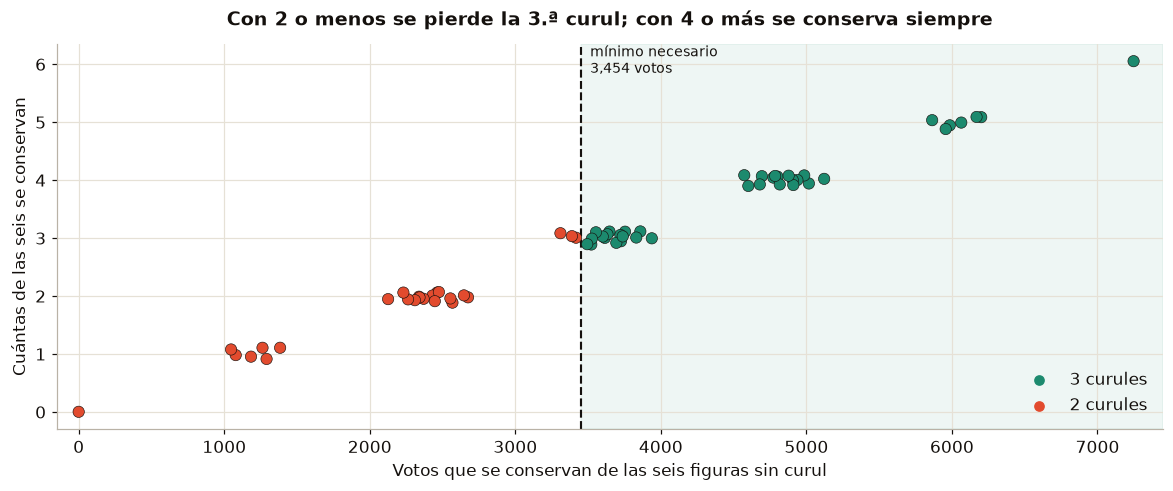

In [29]:
# Gráfico: curules de En Marcha según cuántas de sus seis figuras sin curul conserva
fig, ax = plt.subplots(figsize=(10.8, 4.6))
jit = np.random.default_rng(1).uniform(-.12, .12, len(EN))
col = [TEAL if c >= 3 else VERM for c in EN.curules]
ax.scatter(EN.votos_conservados, EN.conservadas + jit, c=col, s=55, edgecolor=INK, lw=.4, zorder=3)
ax.axvline(necesarios, color=INK, lw=1.4, ls="--")
ax.text(necesarios + 60, 6.35, f"mínimo necesario\n{necesarios:,.0f} votos", fontsize=9, va="top")
ax.axvspan(necesarios, fs.sum()+200, color=TEAL, alpha=.07)
ax.set_yticks(range(7)); ax.set_xlim(-150, fs.sum()+200)
ax.set_xlabel("Votos que se conservan de las seis figuras sin curul")
ax.set_ylabel("Cuántas de las seis se conservan")
ax.set_title("Con 2 o menos se pierde la 3.ª curul; con 4 o más se conserva siempre", fontsize=12.3)
ax.scatter([], [], c=TEAL, label="3 curules"); ax.scatter([], [], c=VERM, label="2 curules")
ax.legend(frameon=False, loc="lower right"); plt.tight_layout(); plt.show()

In [30]:
# Escenario (nivel C): las mismas 9 figuras repartidas en DOS listas de 17
# Bloque = En Marcha. Se prueba cada forma de dejar k de las 6 figuras sin curul en En Marcha y llevar
# las demás a una lista nueva. E = votos NUEVOS que aportarían las candidaturas que llenan los puestos
# libres de la lista nueva (en una sola lista no había puestos: 17 de 17 ocupados).
base_em = V_EM - fs.sum()
def bloque(keep, E):
    T = totales(2023); kept = fs[list(keep)].sum()
    T[EM] = base_em + kept; T["LISTA NUEVA"] = fs.sum() - kept + E
    s, c, _ = reparto(T, 0.5*(VALIDOS[2023] + E)/CURULES)
    return s[EM], s["LISTA NUEVA"]
print("Sin votos nuevos (E = 0), máximo de curules del bloque en cualquier división:",
      max(sum(bloque(c, 0)) for k in range(7) for c in combinations(range(6), k)))
filas = []
for k in range(7):
    mejor = None
    for keep in combinations(range(6), k):
        if sum(bloque(keep, 9000)) < 4: continue
        lo, hi = 0, 9000
        for _ in range(40):
            m = (lo+hi)/2
            if sum(bloque(keep, m)) >= 4: hi = m
            else: lo = m
        if mejor is None or hi < mejor[0]: mejor = (hi, keep)
    if mejor:
        em, nu = bloque(mejor[1], mejor[0])
        filas.append({"figuras sin curul que quedan en En Marcha": k,
                      "votos de figuras en la lista nueva": int(fs.sum() - fs[list(mejor[1])].sum()),
                      "candidaturas libres en la lista nueva": 17 - (6 - k),
                      "votos nuevos necesarios para 4 curules": int(np.ceil(mejor[0])),
                      "en bancas medianas": round(np.ceil(mejor[0])/MED_B[2023], 1),
                      "curules En Marcha + nueva": f"{em} + {nu}"})
ESC = pd.DataFrame(filas); display(ESC)
print(f"Referencia: dentro de En Marcha, la 4.ª curul pedía {para4 - V_EM:,.0f} votos más, sin puestos libres para buscarlos.")

Sin votos nuevos (E = 0), máximo de curules del bloque en cualquier división: 3


,figuras sin curul que quedan en En Marcha,votos de figuras en la lista nueva,candidaturas libres en la lista nueva,votos nuevos necesarios para 4 curules,en bancas medianas,curules En Marcha + nueva
0,0,7248,11,837,4.6,2 + 2
1,1,6201,12,1884,10.3,2 + 2
2,2,5122,13,2963,16.2,2 + 2
3,3,3938,14,4147,22.7,2 + 2
4,4,2675,15,1368,7.5,3 + 1
5,5,1384,16,2659,14.5,3 + 1
6,6,0,17,4043,22.1,3 + 1


Referencia: dentro de En Marcha, la 4.ª curul pedía 815 votos más, sin puestos libres para buscarlos.


**Hallazgo 18: En Marcha necesitaba 3 de sus 6 figuras sin curul; las otras 3 aportaron 3.794 votos que no se convirtieron en curul.** `Nivel A (cálculo exacto) · escenario final Nivel C`

El recálculo exacto del reparto de 2023 en las 64 combinaciones da una respuesta sin ambigüedad:

- **Para conservar 3 curules, En Marcha necesitaba 11.560 votos** (3 × 3.853, el cociente de Conservador – MIRA, que era el siguiente en la fila; con 11.559 habría empatado y la curul se sorteaba). Tuvo 15.354: le **sobraron 3.794 votos**, el 24,7 % de la lista. Por debajo de ese mínimo, la tercera curul pasaba a Conservador – MIRA.
- De los 7.248 votos de las seis figuras sin curul, **eran necesarios 3.454 y sobraban 3.794**.
- **Con 0, 1 o 2 de las seis**, la lista caía a 2 curules en las 22 combinaciones. **Con 3**, conservaba las 3 curules en 17 de 20 combinaciones (fallaban solo las tres más débiles, de 3.310 a 3.417 votos). **Con 4, 5 o 6**, siempre.
- Respuesta corta: **de las seis figuras que no salieron, tres eran necesarias y tres sobraban.** Las tres sobrantes no alcanzaban para una 4.ª curul: faltaron **815 votos** (≈0,65 figuras), y la lista no tenía puestos libres para buscarlos (17 de 17 ocupados).

**Escenario (no es un hecho): las mismas 9 figuras en dos listas.** Si las figuras se hubieran repartido entre En Marcha y una segunda lista, **sin votos nuevos el bloque seguía en 3 curules** en cualquier división: la cifra repartidora no premia dividirse. Lo que cambia es el número de puestos, porque una segunda lista abre hasta 11 candidaturas más. La división más eficiente era dejar en En Marcha a las 3 elegidas y su equipo (8.106 votos, 2 curules) y llevar las 6 figuras sin curul a la nueva (7.248 votos): con **837 votos nuevos** de sus otras 11 candidaturas, unas 4–5 bancas medianas, el bloque habría tenido **4 curules (2 + 2)**. Son casi los mismos 815 votos que le faltaron a En Marcha para su 4.ª curul; la diferencia es que en dos listas había puestos para buscarlos.

*Lo que NO significa:* el escenario supone que cada figura conserva sus votos al cambiar de lista y que las demás listas no cambian; ninguna de las dos cosas está garantizada. Lo exacto es el cálculo sobre la lista real: tres de las seis figuras sin curul no cambiaron el número de curules de En Marcha.

### 8.11 Figuras sobrantes en todas las listas

El cálculo de En Marcha se repite para **cada lista con curul que tuvo figuras sin elegir**: se enumeran todas las combinaciones de quitar figuras no elegidas y se busca el **mayor número que la lista podía perder sin perder ninguna curul** (figuras sobrantes). El resto son figuras no elegidas pero **necesarias**: sin sus votos la lista habría tenido menos curules.

In [31]:
# --- 8.11 Figuras necesarias vs sobrantes, todas las listas ---
filas = []
for y in (2019, 2023):
    for lista, V in totales(y).items():
        cur = SEATS[y][lista]
        if not cur: continue
        dd = ce[(ce.anio==y) & (ce.nombre_partido==lista)]
        nf = dd[(~dd.electo) & (dd.tipo=="F")].votos.values.astype(float)
        if not len(nf): continue
        max_quit, votos_q = 0, 0
        for k in range(len(nf), 0, -1):
            ok = [c for c in combinations(range(len(nf)), k) if curules_con(y, lista, V - nf[list(c)].sum()) >= cur]
            if ok:
                max_quit = k; votos_q = min(nf[list(c)].sum() for c in ok); break
        filas.append(dict(anio=y, lista=lista, curules=cur, figuras=int((dd.tipo=="F").sum()),
                          figuras_sin_curul=len(nf), sobrantes=max_quit, necesarias=len(nf)-max_quit,
                          votos_figuras_sin_curul=int(nf.sum()), votos_sobrante_lista=int(MARG[(MARG.anio==y)&(MARG.lista==lista)].sobrante.iloc[0])))
SOBR = pd.DataFrame(filas)
display(SOBR.sort_values(["anio", "figuras_sin_curul"], ascending=[True, False]))
for y in (2019, 2023, None):
    d = SOBR if y is None else SOBR[SOBR.anio==y]
    fig_tot = int((ce.tipo=="F").sum()) if y is None else int(((ce.anio==y) & (ce.tipo=="F")).sum())
    ele = int((ce.electo & (ce.tipo=="F")).sum()) if y is None else int((ce.electo & (ce.tipo=="F") & (ce.anio==y)).sum())
    print(f"{'ambos' if y is None else y}: {fig_tot} figuras · {ele} elegidas · {d.figuras_sin_curul.sum()} sin curul en listas con curul "
          f"→ {d.necesarias.sum()} necesarias para las curules de su lista y {d.sobrantes.sum()} sobrantes")

,anio,lista,curules,figuras,figuras_sin_curul,sobrantes,necesarias,votos_figuras_sin_curul,votos_sobrante_lista
1,2019,PARTIDO LIBERAL COLOMBIANO,2,6,4,2,2,6152,3891
0,2019,PARTIDO CAMBIO RADICAL,3,6,3,0,3,4239,212
2,2019,MOVIMIENTO ALTERNATIVO INDIGENA Y SOCIAL MAIS,2,4,2,2,0,2464,3037
4,2019,CIVICOS AL 100%,1,3,2,2,0,2295,4300
5,2019,PARTIDO ALIANZA VERDE,1,3,2,2,0,2661,3867
6,2019,PARTIDO POLO DEMOCRATICO ALTERNATIVO,1,3,2,2,0,2092,3679
3,2019,PARTIDO ALIANZA SOCIAL INDEPENDIENTE ASI,2,3,1,0,1,1056,560
7,2019,PARTIDO SOCIAL DE UNIDAD NACIONAL PARTIDO DE ...,1,2,1,0,1,1097,744
8,2023,AGRUPACIÓN POLÍTICA EN MARCHA,3,9,6,3,3,7248,3794
9,2023,CIVICOS,2,6,4,3,1,4435,3135


2019: 35 figuras · 17 elegidas · 17 sin curul en listas con curul → 7 necesarias para las curules de su lista y 10 sobrantes
2023: 37 figuras · 16 elegidas · 18 sin curul en listas con curul → 6 necesarias para las curules de su lista y 12 sobrantes
ambos: 72 figuras · 33 elegidas · 35 sin curul en listas con curul → 13 necesarias para las curules de su lista y 22 sobrantes


**Hallazgo 19: Casi dos de cada tres figuras que no salieron en listas con curul no eran necesarias para las curules de su lista.** `Nivel A`

En los dos ciclos hubo **72 figuras**: 33 salieron electas, 4 estaban en listas que no llegaron a la cifra y **35 quedaron sin curul en listas ganadoras**. De esas 35:

| | 2019 | 2023 | Total |
|---|:---:|:---:|:---:|
| Figuras sin curul en listas ganadoras | 17 | 18 | 35 |
| **Necesarias** (sin sus votos la lista perdía una curul) | 7 | 6 | **13** |
| **Sobrantes** (la lista conservaba sus curules sin ellas) | 10 | 12 | **22** |

El patrón de En Marcha no es excepcional. En 2019, el Partido Liberal tuvo 6 figuras y 2 curules: de sus 4 figuras sin curul, 2 eran necesarias y 2 sobraban; Cambio Radical, en cambio, necesitaba a sus 3 figuras sin curul para sostener la tercera (le sobraban solo 212 votos). En 2023, Cívicos tuvo 6 figuras y 2 curules: de sus 4 sin curul, 3 sobraban.

*Lo que NO significa:* "sobrante" se mide con los demás votos fijos. Una figura sobrante aportó votos reales a su lista y pudo ser decisiva para el margen de seguridad o el orden interno. Lo que dice el cálculo es que, **en el resultado que ocurrió**, sus votos no cambiaron el número de curules de la lista.

### 8.12 ¿Y el territorio? Un resultado nulo que conviene reportar

Una hipótesis razonable: que las figuras electas sean las que reparten mejor sus votos por la ciudad, o al revés, las que tienen un fortín. Se puede medir, y la respuesta es que **no**.

In [32]:
# --- 8.12 ¿La geografía del voto distingue a la figura electa de la que no salió? ---
vm = pd.read_csv(ANAL/"votos_mesa.csv", encoding="utf-8-sig",
                 usecols=["anio", "corporacion", "territorio", "nombre_partido", "nombre_candidato", "tipo_opcion", "votos"])
vm = vm[(vm.corporacion=="CONCEJO") & (vm.tipo_opcion=="candidato")]
cc  = vm.groupby(["anio", "nombre_partido", "nombre_candidato", "territorio"], as_index=False).votos.sum()
tot = cc.groupby(["anio", "nombre_partido", "nombre_candidato"], as_index=False).votos.sum().rename(columns={"votos": "tot"})
cc  = cc.merge(tot, on=["anio", "nombre_partido", "nombre_candidato"]); cc["sh"] = cc.votos/cc.tot
met = (cc.groupby(["anio", "nombre_partido", "nombre_candidato", "tot"])
         .apply(lambda g: pd.Series({"hhi": float((g.sh**2).sum()), "top_sh": float(g.sh.max())}), include_groups=False)
         .reset_index())
info = ce[["anio", "nombre_partido", "nombre_candidato", "tipo", "electo"]]
met = met.merge(info, on=["anio", "nombre_partido", "nombre_candidato"], how="left")
FU = met[met.tipo=="F"]
print("Concentración territorial de las FIGURAS, electas vs no electas (HHI alto = voto concentrado)\n")
for y in (2019, 2023):
    for e, lbl in [(True, "electas"), (False, "no electas")]:
        s = FU[(FU.anio==y) & (FU.electo==e)]
        print(f"  {y} {lbl:11} n={len(s):>3}  HHI mediano {s.hhi.median():.3f}  territorio principal {100*s.top_sh.median():.1f} %")

ovs = []
for _, L in AB.iterrows():
    sub = cc[(cc.anio==L.anio) & (cc.nombre_partido==L.lista)]
    figs = ce[(ce.anio==L.anio) & (ce.nombre_partido==L.lista) & (ce.tipo=="F")].nombre_candidato.values
    sub = sub[sub.nombre_candidato.isin(figs)]
    if len(figs) < 2: continue
    perf = {c: sub[sub.nombre_candidato==c].set_index("territorio").sh for c in figs}
    pares = []
    for a, b in combinations(figs, 2):
        pa, pb = perf[a].align(perf[b], fill_value=0); pares.append(float(np.minimum(pa, pb).sum()))
    ovs.append(dict(anio=L.anio, lista=L.lista, nF=len(figs), solape=float(np.mean(pares)), curules=L.cur))
OV = pd.DataFrame(ovs); OV["efic"] = OV.curules/OV.nF
print("\nSolapamiento territorial medio entre figuras de una misma lista (0 = mapas distintos, 1 = idénticos)")
for y in (2019, 2023):
    s = OV[OV.anio==y]
    print(f"  {y}: media {s.solape.mean():.3f} · n={len(s)} · correlación solape vs curules por figura "
          f"{np.corrcoef(s.solape, s.efic)[0,1]:+.2f}")

Concentración territorial de las FIGURAS, electas vs no electas (HHI alto = voto concentrado)

  2019 electas     n= 17  HHI mediano 0.148  territorio principal 21.4 %
  2019 no electas  n= 18  HHI mediano 0.147  territorio principal 20.6 %
  2023 electas     n= 16  HHI mediano 0.139  territorio principal 20.4 %
  2023 no electas  n= 21  HHI mediano 0.143  territorio principal 20.8 %

Solapamiento territorial medio entre figuras de una misma lista (0 = mapas distintos, 1 = idénticos)
  2019: media 0.806 · n=9 · correlación solape vs curules por figura +0.06
  2023: media 0.755 · n=7 · correlación solape vs curules por figura -0.72


**Hallazgo 20: Cómo reparte sus votos una figura por la ciudad no predice si sale electa.** `Nivel B (resultado nulo)`

La concentración territorial de las figuras electas y la de las no electas es prácticamente la misma en ambos ciclos (ver la salida de arriba). Lo que sí aparece es un dato estructural: **las figuras de una misma lista pescan en el mismo territorio** (solapamiento medio de 0,81 en 2019 y 0,76 en 2023), no se reparten la ciudad. Eso ayuda a entender 8.10–8.11: sumar una figura más a una lista no abre un frente nuevo, compite por un voto parecido.

La relación entre menor solapamiento y más curules por figura es +0,06 en 2019 y −0,72 en 2023 (n = 9 y 7): **no hay evidencia** de efecto, y se reporta el nulo en lugar de quedarse con el ciclo que daba el resultado atractivo.

*Lo que NO significa:* que el territorio no importe para hacer campaña. Significa que, entre quienes ya son figuras, la **forma** geográfica de sus votos no decide la curul.

### 8.13 Robustez: ¿cambian las conclusiones si se mueven los cortes?

Se repiten los resultados clave con nueve combinaciones de cortes (figura 0,20 / 0,225 / 0,25 cifras; medio 0,10 / 0,124 / 0,15). Una conclusión es robusta si se mantiene en todas.

In [33]:
# --- 8.13 Sensibilidad a los cortes del criterio ---
filas = []
for cf in (0.20, 0.225, 0.25):
    for cm in (0.10, 0.124, 0.15):
        cut = {"F": cf, "M": cm, "B": CUT["B"]}
        Ux = AB[P17].values / AB.cifra.values[:, None]
        T = AB[["anio", "gano", "u_tot", "cur"]].copy()
        T["F"] = (Ux >= cf).sum(1); T["M"] = ((Ux >= cm) & (Ux < cf)).sum(1)
        T["B"] = ((Ux >= cut["B"]) & (Ux < cm)).sum(1); T["R"] = ((Ux > 0) & (Ux < cut["B"])).sum(1)
        f = {"corte figura": cf, "corte medio": cm}
        for y in (2019, 2023):
            d = T[T.anio==y]
            f[f"F=0 gana {y}"] = f"{int(d[d.F==0].gano.sum())}/{int((d.F==0).sum())}"
            f[f"F≥2 gana {y}"] = f"{int(d[d.F>=2].gano.sum())}/{int((d.F>=2).sum())}"
            f[f"δ banca {y}"] = round(cliff(d[d.gano].B, d[~d.gano].B), 2)
        accs = []
        for tr, te in ((2019, 2023), (2023, 2019)):
            a, b_ = T[T.anio==tr], T[T.anio==te]
            bb, *_ = np.linalg.lstsq(a[XV].values.astype(float), a.u_tot.values, rcond=None)
            accs.append(((b_[XV].values @ bb >= 1) == b_.gano).mean())
        f["ecuación: acierto fuera de muestra"] = f"{accs[0]:.0%} / {accs[1]:.0%}"
        filas.append(f)
ROB = pd.DataFrame(filas); display(ROB)

,corte figura,corte medio,F=0 gana 2019,F≥2 gana 2019,δ banca 2019,F=0 gana 2023,F≥2 gana 2023,δ banca 2023,ecuación: acierto fuera de muestra
0,0.200,0.100,0/5,9/9,0.20,0/8,9/9,0.27,100% / 88%
1,0.200,0.124,0/5,9/9,0.09,0/8,9/9,0.38,100% / 100%
2,0.200,0.150,0/5,9/9,0.12,0/8,9/9,0.45,100% / 100%
3,0.225,0.100,0/5,9/9,0.20,0/10,7/7,0.27,96% / 94%
4,0.225,0.124,0/5,9/9,0.09,0/10,7/7,0.38,96% / 100%
5,0.225,0.150,0/5,9/9,0.12,0/10,7/7,0.45,96% / 100%
6,0.250,0.100,1/7,7/7,0.20,0/10,6/6,0.27,91% / 88%
7,0.250,0.124,1/7,7/7,0.09,0/10,6/6,0.38,91% / 100%
8,0.250,0.150,1/7,7/7,0.12,0/10,6/6,0.45,91% / 100%


**Lectura de la prueba de robustez.** Las conclusiones de 8.5, 8.6 se sostienen con casi todos los cortes:

- **Dos o más figuras, curul** en las nueve combinaciones y en ambos años.
- **Sin figura, sin curul** con cortes de figura de 0,20 y 0,225. Con el corte más alto (0,25) aparece una excepción: Bienestar y Unidad Social (2019), cuya cabeza sacó 1.013 votos, justo el piso del electo; con ese corte deja de contar como figura.
- **El número de bancas separa poco** (δ entre 0,09 y 0,45 según corte y año), siempre bastante menos que figuras y medios.
- La ecuación ajustada en un ciclo **sigue acertando en el otro** entre 88 % y 100 % de las listas.

Lo que sí cambia con los cortes son los coeficientes de la ecuación y las cantidades exactas de cada tipo en las recetas; por eso las recetas usan el corte central y se presentan como escenarios.

### 8.14 La receta para 17 puestos (síntesis práctica de la sección)

Todo lo anterior se resume en cifras repartidoras, para que sirva con la cifra que resulte en 2027 (en 2019 fue 4.412 y en 2023, 4.042):

| Para… | Composición mínima de 17 (P ≥ 80 %) | Qué cuesta | Evidencia |
|---|---|---|:---:|
| **1 curul** | 1 figura + 1 o 2 medios + 10–11 banca + 4 relleno | Ninguna figura queda sin curul | B/C |
| **2 curules** | 4 figuras + 3 medios + 6 banca + 4 relleno | ≈2 figuras sin curul | B/C |
| **3 curules** | 7–8 figuras + 3–4 medios + 2 banca + 4 relleno | ≈4–5 figuras sin curul | C |

**Reglas que replican en 2019 y 2023:**

1. **El objetivo se fija en votos.** Una curul cuesta una cifra repartidora; para conservarla basta superar el siguiente cociente en la fila (0,95–0,98 de la cifra en estos dos ciclos).
2. **Sin figura no hubo curul** (0 de 15 listas; Conservador – MIRA, con 4 medios, quedó a 190 votos). Con dos o más figuras, siempre (16 de 16).
3. **Con una sola figura decide el número 2 y el volumen del resto**, no cuántos nombres de banca haya. El resto de la lista debe aportar ≈0,65 cifras.
4. **La segunda curul pide unas 4 figuras; la tercera, 7 u 8.** Cada figura por encima de las curules que hará la lista queda sin puesto.
5. **Las figuras de más no suman curules a su propia lista.** En los dos ciclos, 22 de las 35 figuras sin curul en listas ganadoras sobraban; en En Marcha, 3 de 6. Dividir figuras entre listas no da curules por sí solo; lo que da es puestos libres para sumar votos nuevos.

### 8.15 Si quieres GANAR un puesto: en qué lista entrar

Ganar exige **dos condiciones a la vez**: que la lista supere la cifra y que quedes entre los N primeros de esa lista, donde N es el número de curules que hace. De ahí las dos trampas, presentes en los dos ciclos:

- **Trampa 1: entrar donde no eres de los N primeros.** Es la causa de casi todas las figuras sin curul. En 2019 Morgan Egea sacó **1.705 votos y no salió**, más que la mediana del electo de ese año (1.701). Con esos mismos votos, en otra lista habría entrado.
- **Trampa 2: ser la figura de una lista que no llega.** Kelly Ortiz, 1.472 votos, el 48 % de su lista, sin curul: Vamos Unidos sumó 3.033 contra una cifra de 4.042, a 1.010 votos de la curul.

**Qué mirar antes de firmar, en orden:**

1. **¿La lista va a superar la cifra?** Usa la ecuación de 8.6: suma 0,355 por figura, 0,155 por medio, 0,063 por banca y 0,009 por relleno. Si no llega a 1, la lista está en riesgo.
2. **¿Cuántos van a quedar por encima de mí?** Si la lista hará ~2 curules y ya hay 3 figuras más fuertes que tú, tu voto no te alcanza aunque sea alto.
3. **Regla corta:** entras si el número de compañeros más fuertes que tú es menor que las curules que hará la lista. Ser el número 1 o 2 de una lista que hace 1 o 2 curules gana a ser el número 5 de una que hace 3.

## 9. El sistema de partidos visto desde las comunas

La sección anterior trató la lista como una estructura de candidatos. Falta preguntarse qué es la **etiqueta** del partido en Barrancabermeja: ¿arrastra voto propio, hay comunas fieles a una marca, se está fragmentando el voto?


In [34]:
# --- 9.1 ¿Cuánto cambia el voto entre partidos, comuna por comuna? ---
# Índice de Pedersen: mitad de la suma de cambios absolutos en la cuota de cada lista.
vmc = pd.read_csv(ANAL/"votos_mesa.csv", encoding="utf-8-sig",
                  usecols=["anio","corporacion","territorio","nombre_partido",
                           "tipo_opcion","es_voto_valido","votos"])
vmc = vmc[(vmc.corporacion=="CONCEJO") & (vmc.es_voto_valido)]

pc  = vmc.groupby(["anio","territorio","nombre_partido"], as_index=False).votos.sum()
tt  = pc.groupby(["anio","territorio"], as_index=False).votos.sum().rename(columns={"votos":"T"})
pc  = pc.merge(tt, on=["anio","territorio"]); pc["sh"] = 100*pc.votos/pc["T"]

ped = {}
for t in URB:
    a = pc[(pc.anio==2019) & (pc.territorio==t)].set_index("nombre_partido").sh
    b = pc[(pc.anio==2023) & (pc.territorio==t)].set_index("nombre_partido").sh
    a, b = a.align(b, fill_value=0)
    ped[t] = float(np.abs(a-b).sum()/2)
PED = pd.Series(ped).sort_values(ascending=False)

print("VOLATILIDAD DEL VOTO ENTRE LISTAS, Concejo 2019 → 2023 (índice de Pedersen)")
print("0 = ninguna lista cambió su cuota · 100 = recambio total\n")
for t, v in PED.items():
    print(f"  {t:12} {v:>5.1f}")
print(f"\n  Promedio ciudad {PED.mean():.1f} · rango {PED.min():.1f}–{PED.max():.1f} "
      f"(apenas {PED.max()-PED.min():.1f} puntos entre la más y la menos volátil)")


VOLATILIDAD DEL VOTO ENTRE LISTAS, Concejo 2019 → 2023 (índice de Pedersen)
0 = ninguna lista cambió su cuota · 100 = recambio total

  COMUNA 2      92.4
  COMUNA 1      92.3
  COMUNA 6      92.2
  COMUNA 7      91.5
  COMUNA 3      91.2
  COMUNA 4      90.3
  COMUNA 5      89.7

  Promedio ciudad 91.4 · rango 89.7–92.4 (apenas 2.7 puntos entre la más y la menos volátil)


In [35]:
# --- 9.2 ¿Es volatilidad real o recambio de etiquetas? ---
lst19 = set(pe[pe.anio==2019].nombre_partido); lst23 = set(pe[pe.anio==2023].nombre_partido)
ambas = lst19 & lst23
print(f"Listas que compitieron en 2019 : {len(lst19)}")
print(f"Listas que compitieron en 2023 : {len(lst23)}")
print(f"Listas presentes en AMBOS años : {len(ambas)}  -> {', '.join(sorted(ambas))}\n")
for y, s in [(2019, pe[pe.anio==2019]), (2023, pe[pe.anio==2023])]:
    sh = 100*s[s.nombre_partido.isin(ambas)].votos.sum()/s.votos.sum()
    print(f"  Voto que fue a listas presentes en ambos años, {y}: {sh:.1f}%")

c19 = set(ce[ce.anio==2019].nombre_candidato); c23 = set(ce[ce.anio==2023].nombre_candidato)
rep = c19 & c23
r   = ce[ce.nombre_candidato.isin(rep)]
pa  = r.pivot_table(index="nombre_candidato", columns="anio",
                    values="nombre_partido", aggfunc="first").dropna()
cam = int((pa[2019] != pa[2023]).sum())
print(f"\nCandidatos que se presentaron en los dos ciclos: {len(rep)}")
print(f"  de ellos, cambiaron de partido: {cam}  ({100*cam/len(pa):.0f}%)")

pv = r.pivot_table(index="nombre_candidato", columns="anio", values="votos", aggfunc="sum").dropna()
pv["dif"] = pv[2023] - pv[2019]
print(f"  subieron su votación: {int((pv.dif>0).sum())} · bajaron: {int((pv.dif<0).sum())} "
      f"· cambio mediano {pv.dif.median():+,.0f} votos")


Listas que compitieron en 2019 : 18
Listas que compitieron en 2023 : 25
Listas presentes en AMBOS años : 1  -> PARTIDO LIBERAL COLOMBIANO

  Voto que fue a listas presentes en ambos años, 2019: 11.3%
  Voto que fue a listas presentes en ambos años, 2023: 8.4%

Candidatos que se presentaron en los dos ciclos: 71
  de ellos, cambiaron de partido: 68  (96%)
  subieron su votación: 28 · bajaron: 42 · cambio mediano -23 votos


        listas  nº efectivo  candidatos  voto mediano
------------------------------------------------------
  2019      18         12.8         275           178
  2023      25         16.0         359           113


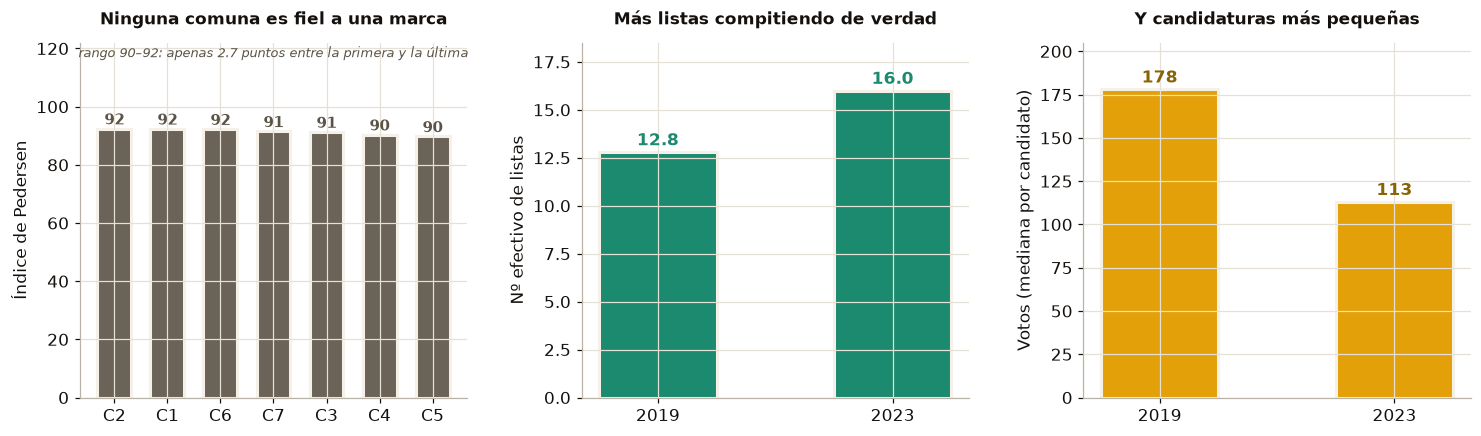

In [36]:
# --- 9.3 Fragmentación: ¿se está atomizando la competencia? ---
print(f"{'':6} {'listas':>7} {'nº efectivo':>12} {'candidatos':>11} {'voto mediano':>13}")
print("-"*54)
frag = {}
for y in (2019, 2023):
    s  = pe[pe.anio==y]; sh = s.votos/s.votos.sum()
    nef = 1/float((sh**2).sum())
    cs  = ce[ce.anio==y]
    frag[y] = (len(s), nef, len(cs), cs.votos.median())
    print(f"{y:>6} {len(s):>7} {nef:>12.1f} {len(cs):>11} {cs.votos.median():>13.0f}")

# Tres paneles, cada uno con UNA sola medida y su propia escala.
fig, axes = plt.subplots(1, 3, figsize=(13.6, 4.1))

ax = axes[0]
x = np.arange(len(PED))
# Color uniforme: el hallazgo es precisamente que no hay comuna distinta.
ax.bar(x, PED.values, .64, color="#6B6358", edgecolor=PAPER, linewidth=2)
for xi, v in enumerate(PED.values):
    ax.text(xi, v+1.5, f"{v:.0f}", ha="center", fontsize=9.5, fontweight="bold", color="#5B5347")
ax.set_xticks(x); ax.set_xticklabels([t.replace("COMUNA ","C") for t in PED.index])
ax.set_ylim(0, 122); ax.set_ylabel("Índice de Pedersen")
ax.annotate(f"rango {PED.min():.0f}–{PED.max():.0f}: apenas {PED.max()-PED.min():.1f} puntos "
            "entre la primera y la última",
            xy=(.5, .99), xycoords="axes fraction", ha="center", va="top",
            fontsize=8.6, color="#5B5347", style="italic")
ax.set_title("Ninguna comuna es fiel a una marca", fontsize=11, fontweight="bold")

ax = axes[1]
xx = np.arange(2); nef = [frag[2019][1], frag[2023][1]]
ax.bar(xx, nef, .5, color=TEAL, edgecolor=PAPER, linewidth=2)
for xi, v in zip(xx, nef):
    ax.text(xi, v+.35, f"{v:.1f}", ha="center", fontsize=11, fontweight="bold", color=TEAL)
ax.set_xticks(xx); ax.set_xticklabels(["2019", "2023"])
ax.set_ylim(0, 18.5); ax.set_ylabel("Nº efectivo de listas")
ax.set_title("Más listas compitiendo de verdad", fontsize=11, fontweight="bold")

ax = axes[2]
med = [frag[2019][3], frag[2023][3]]
ax.bar(xx, med, .5, color=OCHRE, edgecolor=PAPER, linewidth=2)
for xi, v in zip(xx, med):
    ax.text(xi, v+4, f"{v:.0f}", ha="center", fontsize=11, fontweight="bold", color="#8A6204")
ax.set_xticks(xx); ax.set_xticklabels(["2019", "2023"])
ax.set_ylim(0, 205); ax.set_ylabel("Votos (mediana por candidato)")
ax.set_title("Y candidaturas más pequeñas", fontsize=11, fontweight="bold")

plt.tight_layout(); plt.show()


**Hallazgo 21: La etiqueta de partido no arrastra voto: es un vehículo que se alquila cada elección.** `Nivel A/B`

Tres mediciones apuntan a lo mismo:

- **De las 18 listas de 2019 y las 25 de 2023, solo una compitió en ambas** (el Partido Liberal). Las listas que existieron en los dos ciclos recibieron el **11,3 %** del voto en 2019 y el **8,4 %** en 2023.
- **El 96 % de los candidatos que se presentaron en los dos ciclos (68 de 71) lo hizo bajo un partido distinto.**
- La volatilidad entre listas (índice de Pedersen) es de **91,4 en promedio**, y va de **89,7 a 92,4** es decir, prácticamente la misma en las siete comunas. **No hay comuna fiel a una marca.**

La combinación es concluyente: si casi ninguna etiqueta sobrevive de un ciclo al siguiente, y casi todos los candidatos cambian de etiqueta, entonces el voto que se mueve no está siguiendo a los partidos. Esto da un mecanismo al Hallazgo 6 (la geografía local del Liberal no se parece a la del Senado, r = −0,07): **no es que la gente vote distinto al partido en lo local, es que en lo local la etiqueta casi no existe como identidad continua.**

Al mismo tiempo la competencia se está fragmentando: el número efectivo de listas pasó de **12,8 a 16,0**, los candidatos de 275 a 359, y el voto mediano por candidato cayó de **178 a 113**.

*Lo que NO significa:* un Pedersen de 91 no significa que 91 % de los votantes cambiara de opinión. Como las etiquetas mismas desaparecen y se crean, el índice mide **recambio de la oferta** tanto o más que cambio de preferencias. Es justamente ese punto el que sostiene el hallazgo: lo que rota es la oferta partidaria, no necesariamente el electorado.

**Para 2027:** la etiqueta bajo la que se compite no hereda votos del ciclo anterior. Para una lista nueva eso es una buena noticia (no parte en desventaja); para quien cuente con el "voto del partido", es una advertencia.


,roll_2019,roll_2023,cambio
comuna,,,
COMUNA 1,0.73,2.10,1.37
COMUNA 2,0.88,1.13,0.25
COMUNA 3,1.86,2.18,0.32
COMUNA 4,1.83,1.42,-0.41
COMUNA 5,1.70,2.12,0.42
COMUNA 6,2.10,2.45,0.35
COMUNA 7,1.48,2.76,1.28


Roll-off subió en 6 de las 7 comunas urbanas.
Mayor fuga de voto al Concejo en 2023: COMUNA 7 (2.76%)
Correlación del roll-off entre ciclos: +0.35  -> débil: no es un rasgo fijo de cada comuna.


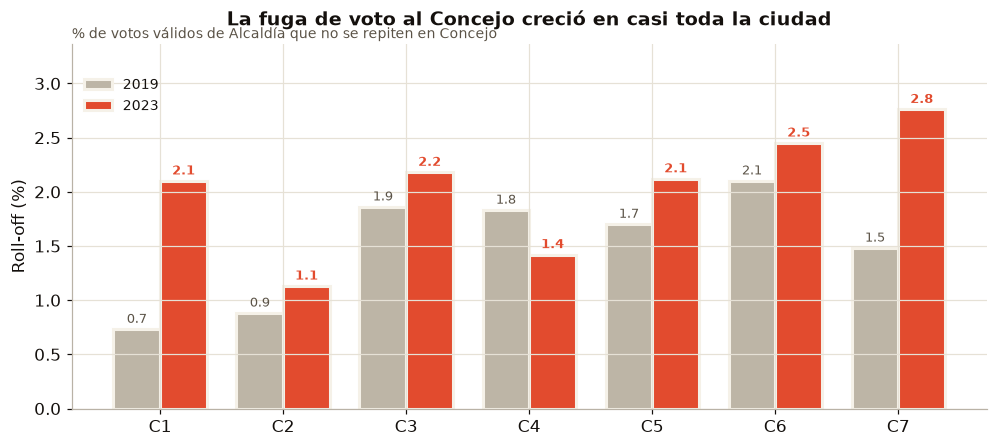

In [37]:
# --- 9.4 Roll-off por comuna: ¿dónde se pierde el voto al Concejo? ---
# Se recarga incluyendo ALCALDE (las cargas anteriores filtraban solo CONCEJO)
vm_ac = pd.read_csv(ANAL/"votos_mesa.csv", encoding="utf-8-sig",
                    usecols=["anio","corporacion","territorio","es_voto_valido","votos"])
ro = (vm_ac[vm_ac.es_voto_valido & vm_ac.corporacion.isin(["ALCALDE","CONCEJO"])]
        .groupby(["anio","corporacion","territorio"], as_index=False).votos.sum())
filas = []
for t in URB:
    f = {"comuna": t}
    for y in (2019, 2023):
        a = ro[(ro.anio==y)&(ro.corporacion=="ALCALDE")&(ro.territorio==t)].votos.sum()
        c = ro[(ro.anio==y)&(ro.corporacion=="CONCEJO")&(ro.territorio==t)].votos.sum()
        f[f"roll_{y}"] = round(100*(a-c)/a, 2) if a else np.nan
    f["cambio"] = round(f["roll_2023"] - f["roll_2019"], 2)
    filas.append(f)
RO = pd.DataFrame(filas).set_index("comuna")
display(RO)
print(f"Roll-off subió en {int((RO.cambio>0).sum())} de las {len(RO)} comunas urbanas.")
print(f"Mayor fuga de voto al Concejo en 2023: {RO.roll_2023.idxmax()} ({RO.roll_2023.max():.2f}%)")
print(f"Correlación del roll-off entre ciclos: {np.corrcoef(RO.roll_2019, RO.roll_2023)[0,1]:+.2f}"
      "  -> débil: no es un rasgo fijo de cada comuna.")

fig, ax = plt.subplots(figsize=(9.2, 4.2))
x = np.arange(len(RO)); w = .38
ax.bar(x-w/2, RO.roll_2019, w, color="#BDB5A6", edgecolor=PAPER, linewidth=2, label="2019")
ax.bar(x+w/2, RO.roll_2023, w, color=VERM,      edgecolor=PAPER, linewidth=2, label="2023")
for xi, (a, b) in enumerate(zip(RO.roll_2019, RO.roll_2023)):
    ax.text(xi-w/2, a+.06, f"{a:.1f}", ha="center", fontsize=8.5, color="#5B5347")
    ax.text(xi+w/2, b+.06, f"{b:.1f}", ha="center", fontsize=8.5, fontweight="bold", color=VERM)
ax.set_xticks(x); ax.set_xticklabels([c.replace("COMUNA ","C") for c in RO.index])
ax.set_ylabel("Roll-off (%)")
ax.set_ylim(0, RO[["roll_2019","roll_2023"]].to_numpy().max()*1.22)
ax.set_title("La fuga de voto al Concejo creció en casi toda la ciudad",
             fontsize=12.5, fontweight="bold")
ax.annotate("% de votos válidos de Alcaldía que no se repiten en Concejo",
            xy=(0, 1.015), xycoords="axes fraction", fontsize=9, color="#5B5347")
ax.legend(frameon=False, fontsize=9, loc="upper left", bbox_to_anchor=(0, .94))
plt.tight_layout(); plt.show()


**Hallazgo 22: La fuga de voto al Concejo creció en seis de las siete comunas.** `Nivel A/B`

Entre quienes ya estaban en el puesto de votación y marcaron Alcaldía, una fracción no deja voto válido de Concejo. Esa fracción **subió en 6 de 7 comunas** entre 2019 y 2023; la única excepción fue la Comuna 4.

El salto mayor está en la **Comuna 7** (1,48 %; 2,76 %), seguida de la **Comuna 1** (0,73 %; 2,10 %). En volumen, cada punto de roll-off en la ciudad equivale a más de mil votos válidos de Concejo que no se emiten.

La correlación entre ciclos es **+0,35**, débil: a diferencia del mapa de participación (Spearman 0,72, Hallazgo 2), el roll-off **no es un rasgo estable de cada comuna**. Es un margen que se mueve, y por eso es accionable: una lista que trabaje el "marque también Concejo" en su territorio está disputando votos que hoy se pierden.

*Lo que NO significa:* el roll-off agregado incluye voto en blanco y nulo de Concejo, no solo tarjetas sin marcar; y es una diferencia entre totales, no el seguimiento de personas concretas.


## 10. Mirada a 2027: escenarios (no pronósticos)

Con **solo dos ciclos territoriales** (2019 y 2023) no es honesto "predecir" 2027 con un modelo. Lo riguroso es plantear **escenarios** acotados y decir de qué dependen.


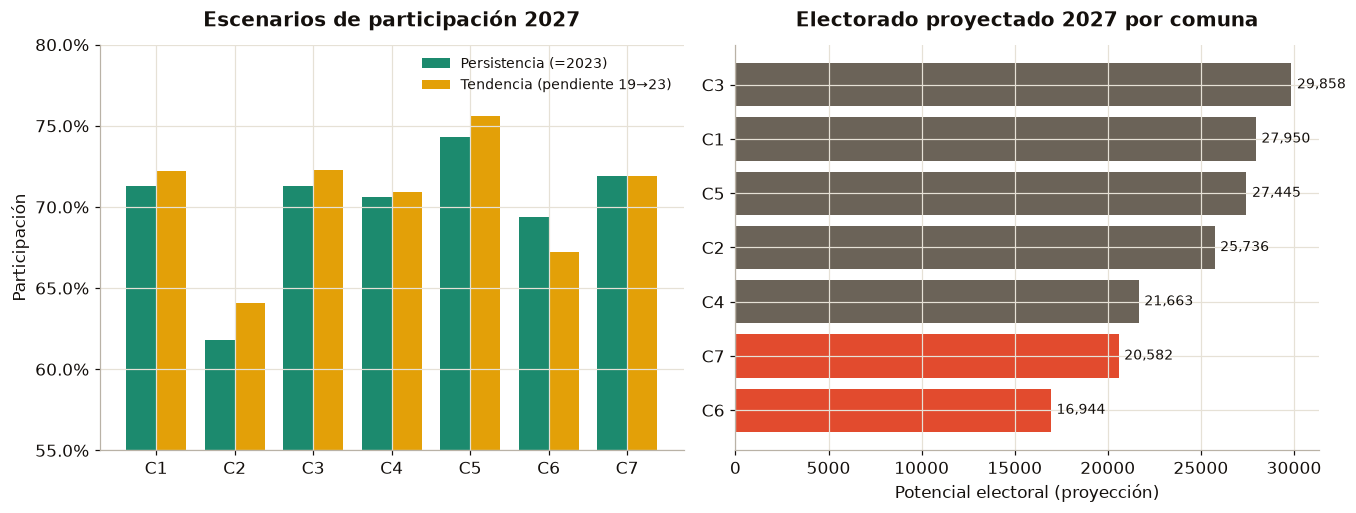

,2019,2023,Persistencia_2027,Tendencia_2027,censo_2026,censo_2027_proy,share_2027_%
territorio,,,,,,,
COMUNA 1,70.4,71.3,71.3,72.2,27890,27950,16.4
COMUNA 2,59.5,61.8,61.8,64.1,25773,25736,15.1
COMUNA 3,70.3,71.3,71.3,72.3,29369,29858,17.5
COMUNA 4,70.3,70.6,70.6,70.9,21430,21663,12.7
COMUNA 5,73.0,74.3,74.3,75.6,27015,27445,16.1
COMUNA 6,71.6,69.4,69.4,67.2,16255,16944,10.0
COMUNA 7,71.9,71.9,71.9,71.9,19309,20582,12.1


In [38]:
# Escenarios de participación territorial 2027 (persistencia vs tendencia)
esc = pd.DataFrame({"2019": p19.round(1), "2023": p23.round(1)})
esc["Persistencia_2027"] = esc["2023"]                              # se repite 2023
esc["Tendencia_2027"]    = (esc["2023"] + (esc["2023"]-esc["2019"])).clip(0,100).round(1)  # misma pendiente 4 años

# Electorado esperado 2027 por comuna: proyección log-lineal del censo 2019→2026 a 2027
import numpy as np
proj = {}
for c in URB:
    xs = np.array([2019,2023,2026]); ys = np.array([cen.loc[c,f"censo_{y}"] for y in xs], float)
    b = np.polyfit(xs, np.log(ys), 1)
    proj[c] = float(np.exp(np.polyval(b, 2027)))
esc["censo_2026"] = cen.censo_2026.astype(int)
esc["censo_2027_proy"] = pd.Series(proj).round(0).astype(int)
esc["share_2027_%"] = (esc["censo_2027_proy"]/esc["censo_2027_proy"].sum()*100).round(1)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
ax = axes[0]
x = np.arange(len(URB)); w=.38
ax.bar(x-w/2, esc["Persistencia_2027"], w, color=TEAL,  label="Persistencia (=2023)")
ax.bar(x+w/2, esc["Tendencia_2027"],    w, color=OCHRE, label="Tendencia (pendiente 19→23)")
ax.set_xticks(x); ax.set_xticklabels([c.replace('COMUNA ','C') for c in URB])
ax.set_ylim(55,80); ax.yaxis.set_major_formatter(PercentFormatter())
ax.set_title("Escenarios de participación 2027"); ax.set_ylabel("Participación"); ax.legend(frameon=False, fontsize=9)

ax = axes[1]
order = esc.sort_values("censo_2027_proy", ascending=True)
ax.barh([c.replace('COMUNA ','C') for c in order.index], order["censo_2027_proy"],
        color=[VERM if c in ("COMUNA 7","COMUNA 6") else "#6B6358" for c in order.index])
for yi,(c,v) in enumerate(order["censo_2027_proy"].items()):
    ax.text(v+300, yi, f"{v:,}", va="center", fontsize=9)
ax.set_title("Electorado proyectado 2027 por comuna"); ax.set_xlabel("Potencial electoral (proyección)")
plt.tight_layout(); plt.show()
display(esc)


**Hallazgo 23: 2027 se juega sobre un mapa conocido, con la periferia pesando más.** `Nivel C (escenario)`

Bajo ambos escenarios, la jerarquía de comunas se mantiene: **Comuna 2 sigue siendo la de menor participación** y las Comunas **5, 7, 1, 3** las de mayor. La novedad es de **peso**: por crecimiento de censo, las Comunas **6 y 7** aportan una fracción creciente del electorado, así que una curul en 2027 se construye cada vez más mirando hacia la periferia.

*Lo que NO significa:* **no es un pronóstico.** Son dos escenarios aritméticos (persistencia y continuación de la tendencia) sobre dos puntos de datos; sirven para acotar expectativas, no para predecir un resultado. Choques locales (un candidato fuerte, una coyuntura) pueden mover la participación más que cualquiera de estas líneas.


## 11. Síntesis de hallazgos

| # | Hallazgo | Evidencia | Qué NO significa |
|---|----------|:---------:|------------------|
| 1 | Barranca participa más en lo **local** (~70 %) que en lo **nacional** (legislativas ~57–60 %, presidencial 64–69 %); la legislativa es la más baja y **cayó** de 2022 a 2026. | A/B | No es el patrón del país; es propio de Barranca. |
| 2 | El mapa de abstención por comuna es **estructural** (Spearman ≈ 0,72) y la **Comuna 2 es la más baja** en toda elección. | B | No son las mismas personas cada vez; es patrón de territorio. |
| 3 | Casi nadie vota "solo Alcaldía"; la fuga es de **votos válidos de Concejo** (~2 % en 2023, y creciendo). | A/B | Dato agregado, no individual; incluye blanco y nulo. |
| 4 | Hay **cuatro arquetipos** de comuna (apática que se encoge / periferia que crece / bastión / centro estable). | B | Perfiles descriptivos, no fijos. |
| 5 | El electorado se **corre hacia la periferia joven** (Comunas 6 y 7); la 2 se encoge. | A/B | Correlación ecológica; no prueba conducta individual. |
| **6** | **El voto al Concejo es personal, no ideológico**: la geografía local del Partido Liberal no se parece a su geografía al Senado (r = −0,07). | B | No mide clientelismo; con 2 partidos comparables es ilustrativo. |
| **7** | **Fortines**: un concejal (Ceferino Garay) sacó el **42 % de sus votos en un solo puesto** (HHI 7× la mediana). | A/B | Concentración ≠ irregularidad; mide dependencia territorial. |
| **8** | **Dos abstenciones**: Comunas 6 y 7 se activan solo para lo local (brecha ~18 pts); la Comuna 2 es apatía pareja (~9 pts). | B | Describe el patrón, no su causa. |
| **9** | **Reglas verificadas**: 17 curules, máx. 17 candidaturas por lista, umbral 50 % del cociente. La última curul se decidió por 72 votos (2019) y 220 (2023); en 2023, 13 de 25 listas no pasaron el umbral. | A | La cifra de 17 curules para 2027 la confirma la Registraduría. |
| **10** | **Criterio único en cifras repartidoras**: el piso del electo fue 0,230 cifras en ambos ciclos; figura ≥0,225, medio ≥0,124, banca ≥0,025. | A/B | Dos observaciones; se prueba la sensibilidad a los cortes (8.13). |
| **11** | **El número 2 de la lista** separa a ganadoras de perdedoras tanto o más que la cabeza (δ = 0,97 y 0,98). | B | No prueba causalidad: indica dónde mirar primero. |
| **12** | **Las posiciones 2–17 explican más del 80 %** de la diferencia de votos entre listas; la cabeza, 12–16 %. | B | La cabeza es condición necesaria, no la que marca diferencias. |
| **13** | Figuras, medios y volumen 2–17 separan en ambos ciclos (p<0,05); **el número de bancas no** (p = 0,79 y 0,12). 0 figuras → 0/15 curules; ≥2 → 16/16. | B | 40 listas; "≥2 figuras" no garantiza curul sin equipo. |
| **14** | **Ecuación de la curul** (cifras): 0,355·F + 0,155·M + 0,063·B + 0,009·R. Ajustada en un ciclo predice el otro (r ≥ 0,988; acierta curul sí/no 96–100 %). | B | Da promedios; una figura concreta puede valer de 0,23 a 0,6 cifras. |
| **15** | **Recetas de 17** (P ≥ 80 %): 1 curul = 1 figura + 1–2 medios; 2 curules = 4 figuras + 3 medios; 3 curules = 7–8 figuras y 4–5 de ellas sin puesto. | B/C | Escenarios; combinaciones no observadas son extrapolación. |
| **21** | **Votos que no eligieron a nadie**: 32,5 % de los válidos en 2019 y 43,5 % en 2023. A varias perdedoras les faltó menos de una figura (Conservador – MIRA, 190 votos). | A/B | El sobrante es inherente al reparto proporcional. |
| **22** | **Los 978 votos** entre Los Verídicos y Por un Cambio Bueno y Justo = 0,78 figuras; 42 % salen del número 2 (un medio de 875 frente a 469) y 43 % de las posiciones 6–17. | A | Dos listas; ilustra el mecanismo de 8.3–8.5. |
| **18** | **En Marcha necesitaba 3 de sus 6 figuras sin curul**; las otras 3 aportaron 3.794 votos que no se convirtieron en curul. Le faltaron 815 para la 4.ª, sin puestos libres para buscarlos. | A (C el escenario de dos listas) | El escenario supone que los votos se trasladan intactos. |
| **19** | **22 de las 35 figuras sin curul en listas ganadoras sobraban** para las curules de su lista; 13 eran necesarias. | A | Con los demás votos fijos; sus votos sí sumaron al margen. |
| **20** | **La geografía del voto de una figura NO predice si sale electa**; las figuras de una lista se solapan ~0,8 en territorio. | B (nulo) | No dice que el territorio no importe para hacer campaña. |
| **21** | **La etiqueta de partido no arrastra voto**: solo 1 lista compitió en ambos ciclos y **96 % de los candidatos repetidores cambió de partido**. Volatilidad ~91 e igual en las 7 comunas. | A/B | El Pedersen mide recambio de la oferta tanto como cambio de preferencias. |
| **22** | **El roll-off creció en 6 de 7 comunas**; no es rasgo fijo de cada una (r = +0,35), por eso es accionable. | A/B | Incluye blanco y nulo; es diferencia de totales, no seguimiento de personas. |
| 23 | 2027: **mismo orden** de participación, con la periferia pesando más. | C | Escenario, no pronóstico. |

## Implicaciones para 2027

- **Cómo se ensambla una lista de 17.** El objetivo se fija en votos: una curul cuesta una cifra repartidora y la ecuación de 8.6 permite sumar la lista antes de inscribirla (0,355 por figura, 0,155 por medio, 0,063 por banca). Sin figura no hubo curul; con una sola, deciden el número 2 y el volumen del resto. La segunda curul pide unas 4 figuras y la tercera 7 u 8, con varias de ellas sin puesto: en los dos ciclos, 22 de 35 figuras sin curul en listas ganadoras sobraban.
- **Qué mira un candidato antes de firmar.** No el tamaño ni la fama de la lista, sino cuántos compañeros van a quedar por encima suyo frente a las curules que la lista va a hacer.
- **La etiqueta pesa poco.** Casi ninguna marca sobrevive de un ciclo al siguiente y el 96 % de los repetidores cambió de partido: una lista nueva no parte en desventaja, y quien cuente con el "voto del partido" se está apoyando en algo que los datos no muestran.
- **Dónde está el voto disponible.** La Comuna 2 concentra la mayor bolsa de abstención pero es la más difícil de activar; el electorado nuevo crece en las Comunas 6 y 7. Y el roll-off voto que ya está en el puesto y no llega al Concejo, subió en casi toda la ciudad: es el voto más barato de recuperar.


## 12. Reproducibilidad, métodos y fuentes

**Fuentes** · Registraduría Nacional del Estado Civil (resultados E-14 y censo electoral) y CNE. Territoriales 2019 y 2023, Congreso 2022 y **2026**, Presidencia 2026 (1.ª y 2.ª vuelta). El Congreso 2026 se agregó desde el escrutinio por mesa y se guardó en `datos/procesados/participacion/participacion_congreso_2026.csv`. Procesamiento propio.

**Métodos** · Participación = votos depositados / potencial electoral. *Roll-off* = diferencia agregada Alcaldía–Concejo en tarjetas depositadas y válidas (misma jornada). Estabilidad del ranking = correlación de Spearman entre comunas. **Nacionalización** = correlación de Pearson, por puesto de votación, entre el % de un mismo partido al Concejo 2023 y al Senado 2022. **Fortines** = concentración territorial del voto de cada candidato (índice Herfindahl-Hirschman, HHI, y % del puesto más fuerte), desde los votos por candidato y puesto en `votos_mesa.csv` (302.979 registros). **Brecha de movilización** = participación territorial 2023 − legislativa 2026 por comuna. Proyección de censo a 2027 = ajuste log-lineal sobre 2019–2023–2026 (escenario). Escenarios de participación = persistencia (=2023) y tendencia (misma pendiente 2019→2023). Los agregados de nacionalización y fortines se guardaron en `datos/procesados/analisis/`.

**Método de la sección 8 (anatomía de listas)** · Se analizan las **43 listas al Concejo** de los dos ciclos (18 en 2019, 25 en 2023). El reparto se recalcula con la cifra repartidora (D'Hondt) y el umbral del 50 % del cociente electoral (Art. 263 CP), y coincide con 17 curules en ambos años. Las **3 listas cerradas** cuentan para el reparto pero se excluyen del análisis por tipo de candidatura. **Criterio único**: cada candidatura se mide en cifras repartidoras de su año (`u = votos ÷ cifra`) y se clasifica en figura (u ≥ 0,225), medio (≥ 0,124), banca (≥ 0,025) o relleno. **Perfil de 17 posiciones**: votos ordenados de mayor a menor dentro de cada lista, con ceros en puestos vacíos. **Descomposición de la varianza** del total por bloques: `Cov(bloque, total)/Var(total)`, con intervalos *bootstrap* (5.000 remuestreos). **Pruebas con/sin curul**: δ de Cliff y p-valor por permutación (10.000), por ciclo. **Ecuación de la curul**: mínimos cuadrados sin intercepto del total de la lista sobre el número de candidaturas de cada tipo, validada ajustando en un ciclo y prediciendo el otro. **Simulación**: para cada composición de 17 puestos, 4.000 listas simuladas sorteando candidaturas reales del mismo tipo y la proporción de voto solo de lista de una lista real; validada fuera de muestra. **Márgenes y figuras sobrantes**: búsqueda binaria y enumeración exacta de combinaciones, recalculando el reparto completo con umbral y los demás votos fijos. **Robustez**: nueve combinaciones de cortes. El solapamiento territorial entre figuras de una lista es el área común de sus perfiles de voto por territorio (suma de mínimos de las cuotas).

**Método de la sección 9 (sistema de partidos)** · Volatilidad = índice de Pedersen entre las cuotas de cada lista por territorio, Concejo 2019 vs 2023. Fragmentación = número efectivo de listas (Laakso-Taagepera, inverso de la suma de cuotas al cuadrado). Permanencia de etiquetas y cambio de partido = cruce por nombre de lista y por nombre de candidato entre los dos ciclos.

**Límites declarados** ·
- **El `n` es pequeño.** La sección 8 se apoya en 40 listas abiertas repartidas en dos ciclos. Las reglas que se ofrecen son las que replican en ambos ciclos, se validan fuera de muestra y resisten la prueba de cortes; aun así son regularidades de dos elecciones, no leyes.
- La ecuación y la simulación suponen que el voto de cada candidatura se suma al de la lista sin restarse a otras de la misma lista. Las combinaciones de 17 que no se observaron en 2019–2023 son extrapolación.
- Los escenarios de traslado de figuras entre listas suponen que cada figura conserva sus votos y que las demás listas no cambian.
- El cruce de candidatos entre ciclos se hace por **nombre**; homónimos o cambios de registro podrían afectarlo marginalmente.
- El nivel por comuna de **Congreso 2022** tiene cobertura de puestos ~92 % (≈6 puestos sin comuna): se usa solo como referencia.
- Los análisis por comuna son **ecológicos**: describen territorios, no personas.
- Los **escenarios 2027** se apoyan en dos ciclos territoriales; son acotaciones, no predicciones.
- El censo 2026 corresponde al corte de la elección presidencial de 2026; para 2027 la Registraduría publicará un censo actualizado.

**Herramientas** · Python · pandas · numpy · matplotlib (la sección 8 usa solo numpy para estadística, sin dependencias adicionales). Cada cifra del cuaderno se recomputa desde los archivos del proyecto.

---
*Laura Pérez · Ciencia de datos — Observatorio de Dinámicas Electorales de Barrancabermeja · @layape*
